# SAMS Vision: PPE detection training

This notebook trains the YOLOv8 detector that SAMS uses to check whether each worker is wearing a hard hat, a safety vest, gloves, and safety shoes. The live service (`monitoring/services/ppe_inference.py`) loads `models/vision/ppe/best.pt` and reads every class rule from `models/vision/ppe/metadata.json`. This notebook writes both files.

## What the model has to do

The live service finds each worker, splits the body into head, torso, hands, and feet, and only accepts a gear box that sits inside the matching region. The detector therefore has to recognise gear while it is worn, on real people, in real work areas. For every item there is a worn class and a missing class.

| SAMS item | Body region | Worn class | Missing class |
|-----------|-------------|------------|---------------|
| hard_hat | head | helmet | no_helmet |
| vest | torso | vest | no_vest |
| gloves | hands | gloves | no_gloves |
| boots | feet | boots | no_boots |

The full label list has 12 classes. The first 11 are the Construction-PPE classes, in the same order, so the class ids never change. `no_vest` is added as class 11 so a worker without a vest can be flagged. `goggles`, `no_goggle`, and `none` are kept so the ids stay aligned, but SAMS does not alarm on them.

## Data sources

| Short name | Source | What it shows | Why it is used |
|------------|--------|---------------|----------------|
| cpex | Ultralytics Construction-PPE | Construction workers with person, worn gear, and missing gear labels | The reference label list, and the only source that labels people |
| mend | Mendeley PPE, DOI 10.17632/zkzghjvpn2.6 | Workers in industrial workspaces with helmets and vests | Factory floors, lines, and lighting that look like SAMS sites |
| wppe | Worker PPE set, Roboflow PPEs v7 (keremberke/protective-equipment-detection) | Workers wearing or missing gloves, shoes, helmets, goggles | The main source of worn and missing gloves and shoes |
| site | Your own labelled SAMS camera frames, optional, under `datasets/vision/ppe/site/` on Drive | Your workers, your floor, your camera | The most trustworthy data. Its test split is scored on its own |

## How to improve PPE on site (do this before expecting missing-gear recall to hold)

Public datasets alone leave missing-gear recall weak on new cameras (boots and `no_boots` especially). Before the next training pass:

1. Capture SAMS frames into `datasets/vision/ppe/site/{train,val,test}/` with the same 12-class YOLO list as Construction-PPE (`helmet` … `no_vest`). Split by recording so one session never sits in both train and test.
2. Prefer scenes with **missing** gear and clear **feet** (boots / no_boots), several angles and lighting levels.
3. Add empty shop frames under `datasets/vision/ppe/background/` so empty negatives exist for false alarms.
4. Promote on **missing-gear recall** (and boots) together with mAP — this notebook now does that when choosing the winner.

## Steps

| Section | Step |
|---------|------|
| 0 | Setup, configuration, class list, helper functions |
| 1 to 3 | Download each source and rewrite its labels into the shared class list |
| 4 | Add the person boxes that Mendeley and the Worker PPE set do not label |
| 5 | Remove duplicate images so no training photo is also a val or test photo |
| 6 | Build one table of every image and fix the val and test splits |
| 7 | Exploratory data analysis |
| 8 | PCA of images and of object crops |
| 9 | Build the training sets: real-image selection first, augmentation second |
| 10 | Training setup: hyperparameters, early stopping, freezing and unfreezing |
| 11 | Experiments, one change at a time, including teacher-filled labels and a larger model |
| 12 | Compare the experiments and choose the recipe |
| 13 | Evaluate the chosen model in detail |
| 14 | Final test per source, metadata for the live service, model card, export check |


## 0. Setup

### 0.1 Paths

The notebook runs in Google Colab or locally. In Colab, data is unpacked on the fast local disk (`/content/SAMS`) and models and results are saved to Google Drive so they survive a disconnect. Locally, the project root is used.

In [56]:
from pathlib import Path

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    SAMS_ROOT = Path("/content/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")

for folder in [
    SAMS_ROOT / "datasets" / "vision" / "ppe",
    SAMS_ROOT / "models" / "vision" / "ppe",
    SAMS_ROOT / "results" / "vision" / "ppe",
]:
    folder.mkdir(parents=True, exist_ok=True)

print("SAMS_ROOT:", SAMS_ROOT.resolve())

Running in Colab: True
SAMS_ROOT: /content/SAMS


In [57]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "ppe"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "ppe"
DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "ppe"

for folder in [MODELS_DIR, RESULTS_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("MODELS_DIR: ", MODELS_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("DATA_DIR:   ", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODELS_DIR:  /content/drive/MyDrive/SAMS/models/vision/ppe
RESULTS_DIR: /content/drive/MyDrive/SAMS/results/vision/ppe
DATA_DIR:    /content/SAMS/datasets/vision/ppe


### 0.2 Packages

`albumentations` 2.x is required because the augmentation steps use its newer argument names. `onnx` and `onnxruntime` are only used for the export check in section 14.

In [58]:
import subprocess
import sys

PACKAGES = [
    "ultralytics>=8.3.0",
    "albumentations>=2.0.0",
    "huggingface_hub",
    "scikit-learn",
    "seaborn",
    "pandas",
    "matplotlib",
    "pyyaml",
    "Pillow",
    "onnx",
    "onnxruntime",
]

if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
    print("Packages installed.")
else:
    print("Not in Colab. Install these packages in your environment if an import fails:")
    print(PACKAGES)

Packages installed.


In [59]:
import gc
import hashlib
import json
import os
import random
import re
import shutil
import time
import urllib.request
import warnings
import zipfile
from collections import Counter
from datetime import datetime, timezone

import albumentations as A
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import ultralytics
import yaml
from IPython.display import display
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from ultralytics import YOLO

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

version_table = pd.DataFrame([
    {"package": "ultralytics", "version": ultralytics.__version__},
    {"package": "torch", "version": torch.__version__},
    {"package": "albumentations", "version": A.__version__},
    {"package": "pandas", "version": pd.__version__},
    {"package": "numpy", "version": np.__version__},
])
display(version_table)

,package,version
0,ultralytics,8.4.188
1,torch,2.11.0+cu130
2,albumentations,2.0.8
3,pandas,2.2.3
4,numpy,2.1.3


### 0.3 Configuration

Every setting that changes the result is in this one cell, with its meaning in the table below. Change a value here and rerun the notebook. Nothing further down hides its own constants.

**Training budget.** Every training run in this notebook is an experiment that can become the promoted model: there is no extra final run, no seed repeats and no leave-one-source-out models. Each run trains for at most `MAX_EPOCHS` and stops once val has not improved for `PATIENCE` epochs, and the best epoch is kept. A patience of 3 keeps Colab compute low. The cost is that a run can stop on a short noisy dip before it has fully converged; a longer run of the winner (120 epochs, patience 25) was tried and val mAP50-95 stayed flat at about 0.34 after epoch 50.

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

HAS_GPU = torch.cuda.is_available()
if HAS_GPU:
    YOLO_DEVICE = 0
    TORCH_DEVICE = "cuda"
else:
    YOLO_DEVICE = "cpu"
    TORCH_DEVICE = "cpu"

VAL_IMAGES_PER_SOURCE = 1000
MIN_EVAL_BOXES = 50
PERSON_PSEUDO_CONF = 0.50
EXTRA_BACKGROUND_DIR = DRIVE_ROOT / "datasets" / "vision" / "ppe" / "background"
SITE_DIR = DRIVE_ROOT / "datasets" / "vision" / "ppe" / "site"

TARGET_BOXES_PER_CLASS = 3000
TARGET_BOXES_PRIORITY = {
    "boots": 4500,
    "no_boots": 4500,
    "no_helmet": 4000,
    "no_vest": 4000,
    "no_gloves": 4000,
}
MAX_IMAGES_PER_SOURCE = 4000
MAX_IMAGES_SITE = 800
BACKGROUND_FRACTION = 0.10
MAX_COPIES_PER_IMAGE = 12

TEACHER_CONF = 0.60
TEACHER_IOU = 0.30

MAX_EPOCHS = 40
PATIENCE = 3
STAGE_A_EPOCHS = 10
FREEZE_LAYERS = 10
if HAS_GPU:
    BATCH = -1
else:
    BATCH = 4
IMGSZ_BASE = 640
IMGSZ_LARGE = 960
WINNER_TOLERANCE = 0.02

MISSING_F_BETA = 2.0
MATCH_IOU = 0.50
ROBUST_SAMPLE = 600
BOOTSTRAP_ROUNDS = 1000

config_rows = [
    {"setting": "SEED", "value": SEED, "meaning": "Random seed for sampling, augmentation, and training"},
    {"setting": "YOLO_DEVICE", "value": YOLO_DEVICE, "meaning": "0 is the first GPU, cpu means no GPU"},
    {"setting": "VAL_IMAGES_PER_SOURCE", "value": VAL_IMAGES_PER_SOURCE, "meaning": "Largest number of validation images taken from one source"},
    {"setting": "MIN_EVAL_BOXES", "value": MIN_EVAL_BOXES, "meaning": "Fewest real boxes a SAMS class should have in val and in test"},
    {"setting": "PERSON_PSEUDO_CONF", "value": PERSON_PSEUDO_CONF, "meaning": "Confidence needed to add a machine-made Person box"},
    {"setting": "EXTRA_BACKGROUND_DIR", "value": str(EXTRA_BACKGROUND_DIR), "meaning": "Folder for your own empty site frames. Leave it empty if you have none"},
    {"setting": "SITE_DIR", "value": str(SITE_DIR), "meaning": "Your labelled SAMS frames in YOLO format, split into train, val, and test. Empty is allowed"},
    {"setting": "TEACHER_CONF", "value": TEACHER_CONF, "meaning": "Confidence a teacher box needs to be added as a label for a class its source does not annotate"},
    {"setting": "TEACHER_IOU", "value": TEACHER_IOU, "meaning": "A teacher box overlapping an existing gear label this much is not added"},
    {"setting": "TARGET_BOXES_PER_CLASS", "value": TARGET_BOXES_PER_CLASS, "meaning": "Default training boxes each SAMS class should reach"},
    {"setting": "TARGET_BOXES_PRIORITY", "value": str(TARGET_BOXES_PRIORITY), "meaning": "Higher box targets for boots and missing-gear classes"},
    {"setting": "MAX_IMAGES_PER_SOURCE", "value": MAX_IMAGES_PER_SOURCE, "meaning": "Largest number of real training images one public source may give"},
    {"setting": "MAX_IMAGES_SITE", "value": MAX_IMAGES_SITE, "meaning": "Cap for labelled SAMS site frames in the curated set"},
    {"setting": "BACKGROUND_FRACTION", "value": BACKGROUND_FRACTION, "meaning": "Share of training images that have no gear at all"},
    {"setting": "MAX_COPIES_PER_IMAGE", "value": MAX_COPIES_PER_IMAGE, "meaning": "Most augmented copies made from one real photo"},
    {"setting": "MAX_EPOCHS", "value": MAX_EPOCHS, "meaning": "Upper limit on epochs. Early stopping usually ends sooner"},
    {"setting": "PATIENCE", "value": PATIENCE, "meaning": "Epochs without a val improvement before training stops"},
    {"setting": "STAGE_A_EPOCHS", "value": STAGE_A_EPOCHS, "meaning": "Epochs with the backbone frozen in two-stage fine-tuning"},
    {"setting": "FREEZE_LAYERS", "value": FREEZE_LAYERS, "meaning": "Layers frozen in stage A. 10 is the whole YOLOv8 backbone"},
    {"setting": "BATCH", "value": BATCH, "meaning": "-1 lets Ultralytics pick the largest batch that fits the GPU"},
    {"setting": "IMGSZ_BASE", "value": IMGSZ_BASE, "meaning": "Default training image size"},
    {"setting": "IMGSZ_LARGE", "value": IMGSZ_LARGE, "meaning": "Larger size tested for small gloves and shoes"},
    {"setting": "WINNER_TOLERANCE", "value": WINNER_TOLERANCE, "meaning": "Missing-gear recall gap treated as a tie; mAP50-95 then decides"},
    {"setting": "MISSING_F_BETA", "value": MISSING_F_BETA, "meaning": "Missing-gear thresholds maximise F-beta with this beta: 2 weighs recall twice as much as precision"},
    {"setting": "MATCH_IOU", "value": MATCH_IOU, "meaning": "Overlap needed for a prediction to count as finding a label"},
    {"setting": "ROBUST_SAMPLE", "value": ROBUST_SAMPLE, "meaning": "Val images used in the bad-conditions test"},
    {"setting": "BOOTSTRAP_ROUNDS", "value": BOOTSTRAP_ROUNDS, "meaning": "Resampling rounds for the confidence intervals"},
]
config_table = pd.DataFrame(config_rows).set_index("setting")
config_table.to_csv(RESULTS_DIR / "config.csv")
display(config_table)


,value,meaning
setting,,
SEED,42,"Random seed for sampling, augmentation, and tr..."
YOLO_DEVICE,0,"0 is the first GPU, cpu means no GPU"
VAL_IMAGES_PER_SOURCE,1000,Largest number of validation images taken from...
MIN_EVAL_BOXES,50,Fewest real boxes a SAMS class should have in ...
PERSON_PSEUDO_CONF,0.5,Confidence needed to add a machine-made Person...
EXTRA_BACKGROUND_DIR,/content/drive/MyDrive/SAMS/datasets/vision/pp...,Folder for your own empty site frames. Leave i...
SITE_DIR,/content/drive/MyDrive/SAMS/datasets/vision/pp...,"Your labelled SAMS frames in YOLO format, spli..."
TEACHER_CONF,0.6,Confidence a teacher box needs to be added as ...
TEACHER_IOU,0.3,A teacher box overlapping an existing gear lab...


### 0.4 Shared class list

Every source is rewritten into this list. `ALIAS_TO_NAME` maps the names used by the other sources (after lower case and removing spaces, dashes, and underscores) onto the shared names. A source class that has no entry here is dropped, and the notebook shows which ones.

`BALANCE_CLASSES` are the eight classes SAMS uses. Only these are balanced, because balancing goggles or `none` would add training images that do not help any SAMS alarm.

In [61]:
CLASS_NAMES = {
    0: "helmet",
    1: "gloves",
    2: "vest",
    3: "boots",
    4: "goggles",
    5: "none",
    6: "Person",
    7: "no_helmet",
    8: "no_goggle",
    9: "no_gloves",
    10: "no_boots",
    11: "no_vest",
}
NUM_CLASSES = len(CLASS_NAMES)

NAME_TO_ID = {}
for class_id, class_name in CLASS_NAMES.items():
    NAME_TO_ID[class_name] = class_id
PERSON_ID = NAME_TO_ID["Person"]

ALIAS_TO_NAME = {
    "helmet": "helmet",
    "hardhat": "helmet",
    "hard hat": "helmet",
    "nohelmet": "no_helmet",
    "no helmet": "no_helmet",
    "vest": "vest",
    "safety vest": "vest",
    "novest": "no_vest",
    "no vest": "no_vest",
    "no safety vest": "no_vest",
    "gloves": "gloves",
    "glove": "gloves",
    "no gloves": "no_gloves",
    "no glove": "no_gloves",
    "noglove": "no_gloves",
    "boots": "boots",
    "boot": "boots",
    "shoes": "boots",
    "shoe": "boots",
    "safety shoes": "boots",
    "no boots": "no_boots",
    "no boot": "no_boots",
    "no shoes": "no_boots",
    "no shoe": "no_boots",
    "noshoes": "no_boots",
    "goggles": "goggles",
    "goggle": "goggles",
    "no goggle": "no_goggle",
    "no goggles": "no_goggle",
    "nogoggles": "no_goggle",
    "person": "Person",
    "none": "none",
}


def norm_name(value):
    text = str(value).strip().lower()
    text = text.replace("-", " ").replace("_", " ")
    return " ".join(text.split())


def shared_id(raw_name):
    """Return the shared class id for a source class name, or None to drop it."""
    key = norm_name(raw_name)
    target = ALIAS_TO_NAME.get(key)
    if target is None:
        target = ALIAS_TO_NAME.get(key.replace(" ", ""))
    if target is None:
        return None
    return NAME_TO_ID[target]


SAMS_ITEMS = {
    "hard_hat": {"label": "Hard hat", "worn": ["helmet"], "missing": ["no_helmet"]},
    "vest": {"label": "Safety vest", "worn": ["vest"], "missing": ["no_vest"]},
    "gloves": {"label": "Gloves", "worn": ["gloves"], "missing": ["no_gloves"]},
    "boots": {"label": "Safety shoes", "worn": ["boots"], "missing": ["no_boots"]},
}

FOCUS_CLASSES = ["helmet", "no_helmet", "vest", "no_vest", "gloves", "no_gloves", "boots", "no_boots"]
MISSING_CLASSES = ["no_helmet", "no_vest", "no_gloves", "no_boots"]
BALANCE_CLASSES = list(FOCUS_CLASSES)


def target_boxes_for(class_name):
    """Box target for one class: priority classes need more examples than the default."""
    return int(TARGET_BOXES_PRIORITY.get(class_name, TARGET_BOXES_PER_CLASS))


def max_images_for(source):
    """Site frames are trusted and scarce; public sources stay capped."""
    if source == "site":
        return int(MAX_IMAGES_SITE)
    return int(MAX_IMAGES_PER_SOURCE)
WORN_MISSING_PAIRS = [
    ("helmet", "no_helmet"),
    ("vest", "no_vest"),
    ("gloves", "no_gloves"),
    ("boots", "no_boots"),
]

SOURCES = ["cpex", "mend", "wppe"]
UNLABELLED_BY_SOURCE = {
    "cpex": ["no_vest"],
    "mend": ["gloves", "no_gloves", "boots", "no_boots"],
    "wppe": ["vest", "no_vest"],
    "site": [],
}
SOURCE_NAMES = {
    "cpex": "Construction-PPE",
    "mend": "Mendeley industrial PPE",
    "wppe": "Worker PPE set (Roboflow PPEs v7)",
    "site": "SAMS site frames",
    "bg": "Extra background frames",
}

class_rows = []
for class_id, class_name in CLASS_NAMES.items():
    item_name = ""
    role = "not used by SAMS"
    for item_key, item in SAMS_ITEMS.items():
        if class_name in item["worn"]:
            item_name = item_key
            role = "worn"
        if class_name in item["missing"]:
            item_name = item_key
            role = "missing"
    if class_name == "Person":
        role = "person, used to place body regions"
    class_rows.append({
        "id": class_id,
        "class": class_name,
        "SAMS item": item_name,
        "role": role,
        "balanced in training": class_name in BALANCE_CLASSES,
    })
display(pd.DataFrame(class_rows).set_index("id"))


,class,SAMS item,role,balanced in training
id,,,,
0,helmet,hard_hat,worn,True
1,gloves,gloves,worn,True
2,vest,vest,worn,True
3,boots,boots,worn,True
4,goggles,,not used by SAMS,False
5,none,,not used by SAMS,False
6,Person,,"person, used to place body regions",False
7,no_helmet,hard_hat,missing,True
8,no_goggle,,not used by SAMS,False


### 0.5 Helper functions

All sources are copied into one staging folder, `merged/`, with this layout:

| Folder | Holds |
|--------|-------|
| `images/pool` | Every published training image. The training sets are chosen from here |
| `images/valcand` | Every published validation image. The fixed val split is chosen from here |
| `images/test` | Every published test image |
| `images/aug` | Augmented training copies, made in section 9 |
| `labels/...` | One YOLO label file per image, in the matching folder |

Training sets, val, and test are then written as text files that list image paths. Ultralytics accepts these lists, so no image is copied twice. Ultralytics finds each label by swapping `images` for `labels` in the path, which is why the two folder trees mirror each other.

Each label line is `class x_center y_center width height`, with the four box values divided by the image width or height so they lie between 0 and 1.

In [62]:
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}
MERGED = DATA_DIR / "merged"
LISTS_DIR = MERGED / "lists"


def list_images(folder):
    found = []
    if not folder.exists():
        return found
    for path in sorted(folder.iterdir()):
        if path.suffix.lower() in IMAGE_SUFFIXES:
            found.append(path)
    return found


def label_path_for(image_path):
    image_path = Path(image_path)
    folder = image_path.parent.name
    return MERGED / "labels" / folder / f"{image_path.stem}.txt"


def read_labels(label_path):
    """Read a YOLO label file into rows of [class_id, xc, yc, w, h]."""
    rows = []
    label_path = Path(label_path)
    if not label_path.is_file():
        return rows
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        class_id = int(float(parts[0]))
        xc = float(parts[1])
        yc = float(parts[2])
        w = float(parts[3])
        h = float(parts[4])
        rows.append([class_id, xc, yc, w, h])
    return rows


def clean_box(xc, yc, w, h):
    """Clip a box to the image. Return None if almost nothing is left."""
    x1 = max(0.0, xc - w / 2)
    y1 = max(0.0, yc - h / 2)
    x2 = min(1.0, xc + w / 2)
    y2 = min(1.0, yc + h / 2)
    new_w = x2 - x1
    new_h = y2 - y1
    if new_w < 0.003 or new_h < 0.003:
        return None
    return [(x1 + x2) / 2, (y1 + y2) / 2, new_w, new_h]


def write_labels(label_path, rows):
    """Write rows of [class_id, xc, yc, w, h]. An empty file means a background image."""
    label_path = Path(label_path)
    label_path.parent.mkdir(parents=True, exist_ok=True)
    lines = []
    for row in rows:
        box = clean_box(row[1], row[2], row[3], row[4])
        if box is None:
            continue
        lines.append(f"{int(row[0])} {box[0]:.6f} {box[1]:.6f} {box[2]:.6f} {box[3]:.6f}")
    text = ""
    if lines:
        text = "\n".join(lines) + "\n"
    label_path.write_text(text)
    return len(lines)


def remap_rows(rows, id_map):
    """Rewrite source class ids into shared ids. Rows with no shared class are dropped."""
    kept = []
    dropped = 0
    for row in rows:
        new_id = id_map.get(row[0])
        if new_id is None:
            dropped += 1
            continue
        kept.append([new_id, row[1], row[2], row[3], row[4]])
    return kept, dropped


def stage_image(source_image, rows, folder, prefix):
    """Copy one image into merged/images/<folder> and write its labels."""
    target_image = MERGED / "images" / folder / f"{prefix}_{source_image.name}"
    target_image.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source_image, target_image)
    write_labels(label_path_for(target_image), rows)
    return target_image


def write_list(name, image_paths):
    """Write a text file with one image path per line, for Ultralytics."""
    LISTS_DIR.mkdir(parents=True, exist_ok=True)
    path = LISTS_DIR / f"{name}.txt"
    lines = []
    for image_path in image_paths:
        lines.append(str(image_path))
    path.write_text("\n".join(lines) + "\n")
    return path


def read_list(list_path):
    paths = []
    for line in Path(list_path).read_text().splitlines():
        if line.strip():
            paths.append(Path(line.strip()))
    return paths


def class_counts_for_images(image_paths):
    counts = Counter()
    for image_path in image_paths:
        for row in read_labels(label_path_for(image_path)):
            counts[row[0]] += 1
    return counts


def counts_table(named_counters, classes=None):
    """One row per class, one column per Counter of class ids."""
    if classes is None:
        classes = list(CLASS_NAMES.values())
    table = pd.DataFrame(index=classes)
    for column, counter in named_counters.items():
        values = []
        for class_name in classes:
            values.append(int(counter.get(NAME_TO_ID[class_name], 0)))
        table[column] = values
    table.index.name = "class"
    return table


def size_bucket(w, h, width, height, train_size=IMGSZ_BASE):
    """Small, medium, or large, measured after the image is resized for training."""
    scale = train_size / max(width, height)
    area = (w * width * scale) * (h * height * scale)
    if area < 32 * 32:
        return "small"
    if area < 96 * 96:
        return "medium"
    return "large"


CLASS_COLORS = {}
color_palette = sns.color_palette("tab20", NUM_CLASSES)
for class_id in CLASS_NAMES:
    CLASS_COLORS[class_id] = color_palette[class_id]


def draw_boxes(ax, image_path, rows, title="", color=None):
    """Draw [class_id, xc, yc, w, h] rows on an image."""
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    ax.imshow(image)
    for row in rows:
        class_id = row[0]
        left = (row[1] - row[3] / 2) * width
        top = (row[2] - row[4] / 2) * height
        box_color = color
        if box_color is None:
            box_color = CLASS_COLORS[class_id]
        rectangle = patches.Rectangle(
            (left, top), row[3] * width, row[4] * height,
            fill=False, linewidth=2, edgecolor=box_color,
        )
        ax.add_patch(rectangle)
        ax.text(left, top, CLASS_NAMES[class_id], color="white", fontsize=7, backgroundcolor=box_color)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


def save_figure(fig, name):
    path = RESULTS_DIR / f"{name}.png"
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.show()
    print("Saved figure:", path)


def save_table(frame, name):
    frame.to_csv(RESULTS_DIR / f"{name}.csv")
    display(frame)


def preview_images(image_paths, title, name, columns=4, rows=2):
    """Show a seeded random grid of images with their labels drawn."""
    picks = []
    for image_path in image_paths:
        picks.append(Path(image_path))
    random.Random(SEED).shuffle(picks)
    picks = picks[:columns * rows]
    fig, axes = plt.subplots(rows, columns, figsize=(4.5 * columns, 4.2 * rows))
    for ax in axes.flatten():
        ax.axis("off")
    for ax, image_path in zip(axes.flatten(), picks):
        rows_in_image = read_labels(label_path_for(image_path))
        draw_boxes(ax, image_path, rows_in_image, title=f"{image_path.name[:30]}  ({len(rows_in_image)} boxes)")
    fig.suptitle(title)
    plt.tight_layout()
    save_figure(fig, name)


if MERGED.exists():
    pass
MERGED.mkdir(parents=True, exist_ok=True)
STAGED = []
print("Staging folder:", MERGED)

Staging folder: /content/SAMS/datasets/vision/ppe/merged


## 1. Construction-PPE

This is the reference source. Its 11 class names are the first 11 names of the shared list, in the same order, so its labels are copied as they are. It is also the only source with human-drawn `Person` boxes.

The cell checks that the class names in the Ultralytics dataset file still match the shared list. If Ultralytics ever changes them, the notebook stops here instead of training a model whose class ids the live service would read wrongly.

In [63]:
from ultralytics.data.utils import check_det_dataset
from ultralytics.utils import SETTINGS

package_dir = Path(ultralytics.__file__).resolve().parent
cpex_yaml_path = package_dir / "cfg" / "datasets" / "construction-ppe.yaml"
cpex_yaml = yaml.safe_load(cpex_yaml_path.read_text())

official_names = {}
raw_names = cpex_yaml["names"]
if isinstance(raw_names, dict):
    for key, value in raw_names.items():
        official_names[int(key)] = str(value)
else:
    for index, value in enumerate(raw_names):
        official_names[index] = str(value)

for class_id, class_name in official_names.items():
    if CLASS_NAMES.get(class_id) != class_name:
        raise RuntimeError(f"Construction-PPE class {class_id} is {class_name}, expected {CLASS_NAMES.get(class_id)}")
print("Construction-PPE names match the first", len(official_names), "shared classes.")

datasets_root = Path(SETTINGS.get("datasets_dir", str(Path.home() / "datasets")))
cpex_root = datasets_root / "construction-ppe"
if not (cpex_root / "images" / "train").exists():
    print("Downloading Construction-PPE...")
    check_det_dataset(str(cpex_yaml_path))
else:
    print("Construction-PPE already present at", cpex_root)

Construction-PPE names match the first 11 shared classes.
Construction-PPE already present at /content/datasets/construction-ppe


In [64]:
CPEX_SPLITS = {"train": "pool", "val": "valcand", "test": "test"}

cpex_rows = []
for original_split, folder in CPEX_SPLITS.items():
    images = list_images(cpex_root / "images" / original_split)
    no_boxes = 0
    for image_path in images:
        label_file = cpex_root / "labels" / original_split / f"{image_path.stem}.txt"
        rows = read_labels(label_file)
        if not rows:
            no_boxes += 1
        target = stage_image(image_path, rows, folder, "cpex")
        STAGED.append({"source": "cpex", "folder": folder, "original_split": original_split, "image": target})
    cpex_rows.append({
        "published split": original_split,
        "staged as": folder,
        "images": len(images),
        "images with no boxes": no_boxes,
    })

save_table(pd.DataFrame(cpex_rows).set_index("published split"), "cpex_staging")

,staged as,images,images with no boxes
published split,,,
train,pool,1132,0
val,valcand,143,0
test,test,141,0


### Preview of Construction-PPE

Eight random training images with their labels. This is the reference source: every worker has a `Person` box, and worn and missing gear are both labelled.

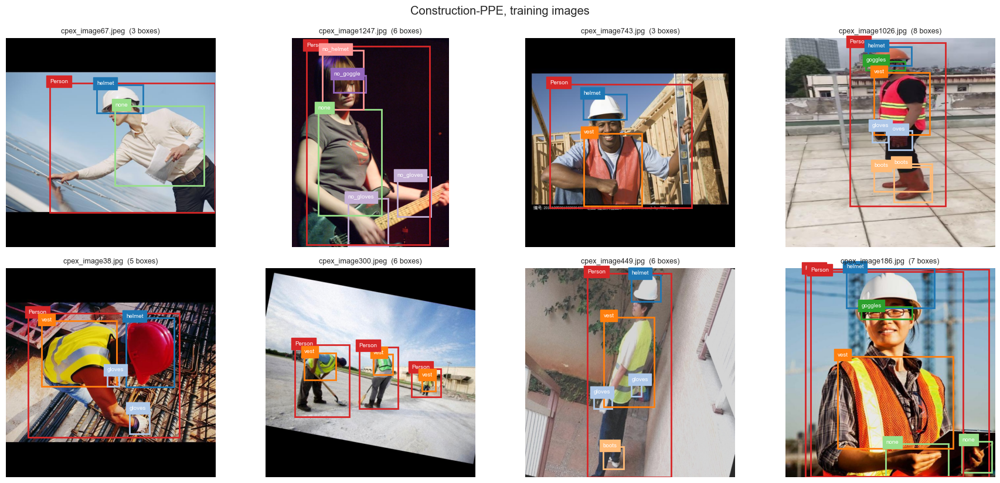

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/preview_cpex.png


In [65]:
cpex_preview = []
for record in STAGED:
    if record["source"] == "cpex" and record["folder"] == "pool":
        cpex_preview.append(record["image"])
preview_images(cpex_preview, "Construction-PPE, training images", "preview_cpex")

## 2. Mendeley industrial PPE

DOI 10.17632/zkzghjvpn2.6. The photos are industrial workspaces: different rooms, production lines, lighting, and backgrounds, with workers wearing or missing helmets and reflective vests. That is the kind of site SAMS watches.

The published classes are Helmet, NoHelmet, Vest, and NoVest. All four are kept. NoVest becomes `no_vest`, which gives SAMS a way to flag a missing vest.

This source does not label people, gloves, or shoes, even when they are in the photo. Section 4 adds the missing person boxes. The missing glove and shoe boxes cannot be added automatically, which is a known limitation listed in the model card (section 14.3).

In [66]:
MENDELEY_DOI = "10.17632/zkzghjvpn2.6"
api_url = "https://data.mendeley.com/api/datasets/zkzghjvpn2/files"
request = urllib.request.Request(api_url, headers={"User-Agent": "SAMS-ppe-notebook/2.0"})
with urllib.request.urlopen(request, timeout=120) as response:
    file_index = json.load(response)

zip_entries = []
for item in file_index:
    if str(item.get("filename", "")).lower().endswith(".zip"):
        zip_entries.append(item)
if not zip_entries:
    raise RuntimeError("The Mendeley file index has no zip file")

zip_entry = zip_entries[0]
zip_path = DATA_DIR / "mendeley_ppe.zip"
if not zip_path.exists() or zip_path.stat().st_size < 1000:
    print("Downloading", zip_entry["filename"])
    download_url = zip_entry["content_details"]["download_url"]
    download = urllib.request.Request(download_url, headers={"User-Agent": "SAMS-ppe-notebook/2.0"})
    with urllib.request.urlopen(download, timeout=600) as response, open(zip_path, "wb") as handle:
        while True:
            chunk = response.read(1 << 20)
            if not chunk:
                break
            handle.write(chunk)

mend_root = DATA_DIR / "mendeley_ppe"
if not list(mend_root.rglob("data.yaml")):
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(mend_root)

yaml_files = list(mend_root.rglob("data.yaml"))
if not yaml_files:
    raise FileNotFoundError("The Mendeley zip has no data.yaml")
mend_base = yaml_files[0].parent
mend_yaml = yaml.safe_load(yaml_files[0].read_text())

mend_names = {}
raw_names = mend_yaml["names"]
if isinstance(raw_names, dict):
    for key, value in raw_names.items():
        mend_names[int(key)] = str(value)
else:
    for index, value in enumerate(raw_names):
        mend_names[index] = str(value)

mend_map = {}
mapping_rows = []
for class_id, class_name in mend_names.items():
    target_id = shared_id(class_name)
    mend_map[class_id] = target_id
    if target_id is None:
        shared_name = "dropped"
    else:
        shared_name = CLASS_NAMES[target_id]
    mapping_rows.append({"source id": class_id, "source name": class_name, "shared name": shared_name})

save_table(pd.DataFrame(mapping_rows).set_index("source id"), "mend_class_mapping")

,source name,shared name
source id,,
0,Helmet,helmet
1,NoHelmet,no_helmet
2,NoVest,no_vest
3,Vest,vest


In [67]:
MEND_SPLITS = {"train": "pool", "valid": "valcand", "test": "test"}

mend_rows = []
for original_split, folder in MEND_SPLITS.items():
    image_dir = mend_base / original_split / "images"
    label_dir = mend_base / original_split / "labels"
    if not image_dir.exists():
        mend_rows.append({"published split": original_split, "staged as": folder, "images": 0,
                          "staged": 0, "skipped, no shared class": 0, "boxes dropped": 0})
        continue
    images = list_images(image_dir)
    staged = 0
    skipped = 0
    dropped_total = 0
    for image_path in images:
        rows = read_labels(label_dir / f"{image_path.stem}.txt")
        kept, dropped = remap_rows(rows, mend_map)
        dropped_total += dropped
        if not kept:
            skipped += 1
            continue
        target = stage_image(image_path, kept, folder, "mend")
        STAGED.append({"source": "mend", "folder": folder, "original_split": original_split, "image": target})
        staged += 1
    mend_rows.append({
        "published split": original_split,
        "staged as": folder,
        "images": len(images),
        "staged": staged,
        "skipped, no shared class": skipped,
        "boxes dropped": dropped_total,
    })

save_table(pd.DataFrame(mend_rows).set_index("published split"), "mend_staging")

,staged as,images,staged,"skipped, no shared class",boxes dropped
published split,,,,,
train,pool,1829,1829,0,0
valid,valcand,457,457,0,0
test,test,0,0,0,0


### Preview of Mendeley

Eight random training images with their labels in the shared class list. Check that `no_vest` boxes sit on workers without a reflective vest. Gloves, shoes, and the workers themselves are not labelled in this source, which is why section 4 adds person boxes.

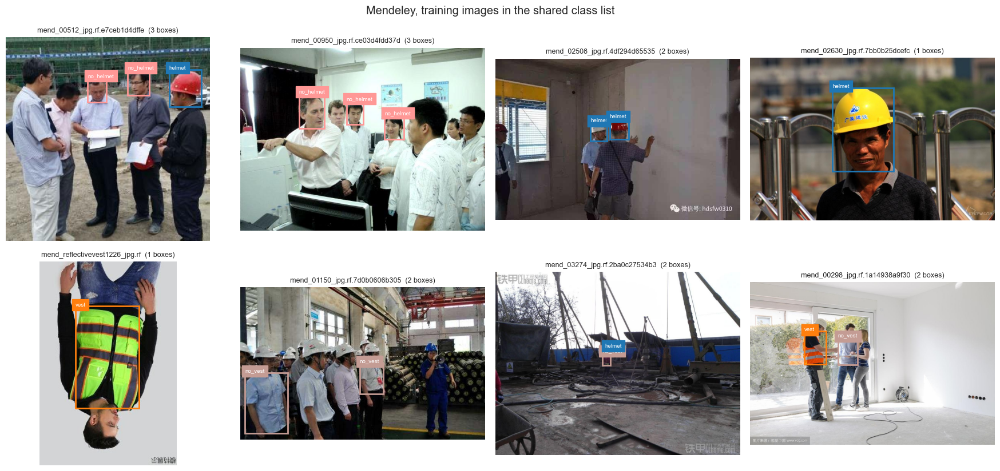

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/preview_mend.png


In [68]:
mend_preview = []
for record in STAGED:
    if record["source"] == "mend" and record["folder"] == "pool":
        mend_preview.append(record["image"])
preview_images(mend_preview, "Mendeley, training images in the shared class list", "preview_mend")

## 3. Worker PPE set (Roboflow PPEs v7)

Published on Hugging Face as `keremberke/protective-equipment-detection`, exported from the Roboflow Universe project `ppes-kaxsi`, version 7, under CC BY 4.0. It has about 12,000 images of workers wearing or missing gloves, safety shoes, helmets, goggles, and masks. Classes such as `no_glove` and `no_shoes` mark a bare hand or a foot without a safety shoe on a worker, which is exactly what the SAMS alarm needs. This is the main source of glove and shoe examples.

Mask and no-mask boxes are dropped, because a mask is not one of the SAMS items. An image whose only boxes are masks is skipped, because the other gear in it may be unlabelled. People are not labelled in this source either, so section 4 adds person boxes here too.

The labels are in COCO format: `[x_left, y_top, width, height]` in pixels. They are converted to YOLO format by moving to the box center and dividing by the image width and height stored with each image.

In [69]:
from huggingface_hub import snapshot_download

wppe_raw = DATA_DIR / "wppe_raw"
snapshot_download(
    repo_id="keremberke/protective-equipment-detection",
    repo_type="dataset",
    local_dir=str(wppe_raw),
    allow_patterns=["data/*.zip", "README.md", "README.dataset.txt"],
)

wppe_unzipped = DATA_DIR / "wppe_unzipped"
for archive_name in ["train.zip", "valid.zip", "test.zip"]:
    archive_path = wppe_raw / "data" / archive_name
    if not archive_path.is_file():
        raise FileNotFoundError(archive_path)
    destination = wppe_unzipped / archive_name.replace(".zip", "")
    if not destination.exists():
        with zipfile.ZipFile(archive_path) as archive:
            archive.extractall(destination)
        print("Extracted", archive_name)
    else:
        print("Already extracted", archive_name)


def find_coco_file(folder):
    preferred = list(folder.rglob("_annotations.coco.json"))
    if preferred:
        return preferred[0]
    for path in folder.rglob("*.json"):
        name = path.name.lower()
        if "coco" in name or "annotation" in name:
            return path
    raise FileNotFoundError(f"No COCO json under {folder}")


def load_coco_as_yolo(coco_path):
    """Return the COCO file, its images, and YOLO rows per image id in the shared class list."""
    coco = json.loads(coco_path.read_text())
    category_map = {}
    for category in coco["categories"]:
        category_map[int(category["id"])] = shared_id(category["name"])

    images = {}
    rows_by_image = {}
    for image in coco["images"]:
        images[int(image["id"])] = image
        rows_by_image[int(image["id"])] = []

    dropped = 0
    for annotation in coco["annotations"]:
        target_id = category_map.get(int(annotation["category_id"]))
        if target_id is None or "bbox" not in annotation:
            dropped += 1
            continue
        image = images[int(annotation["image_id"])]
        image_width = float(image["width"])
        image_height = float(image["height"])
        x_left, y_top, box_width, box_height = [float(value) for value in annotation["bbox"]]
        if box_width <= 1 or box_height <= 1:
            dropped += 1
            continue
        xc = (x_left + box_width / 2) / image_width
        yc = (y_top + box_height / 2) / image_height
        rows_by_image[int(annotation["image_id"])].append(
            [target_id, xc, yc, box_width / image_width, box_height / image_height]
        )
    return coco, images, rows_by_image, dropped


train_coco = json.loads(find_coco_file(wppe_unzipped / "train").read_text())
mapping_rows = []
for category in train_coco["categories"]:
    target_id = shared_id(category["name"])
    if target_id is None:
        shared_name = "dropped"
    else:
        shared_name = CLASS_NAMES[target_id]
    mapping_rows.append({"source id": category["id"], "source name": category["name"], "shared name": shared_name})

save_table(pd.DataFrame(mapping_rows).set_index("source id"), "wppe_class_mapping")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Already extracted train.zip
Already extracted valid.zip
Already extracted test.zip


,source name,shared name
source id,,
0,glove,gloves
1,goggles,goggles
2,helmet,helmet
3,mask,dropped
4,no_glove,no_gloves
5,no_goggles,no_goggle
6,no_helmet,no_helmet
7,no_mask,dropped
8,no_shoes,no_boots


In [70]:
WPPE_SPLITS = {"train": "pool", "valid": "valcand", "test": "test"}

wppe_rows = []
for original_split, folder in WPPE_SPLITS.items():
    coco_path = find_coco_file(wppe_unzipped / original_split)
    coco, images, rows_by_image, dropped = load_coco_as_yolo(coco_path)

    files_by_name = {}
    for path in coco_path.parent.rglob("*"):
        if path.suffix.lower() in IMAGE_SUFFIXES:
            files_by_name[path.name] = path

    staged = 0
    skipped = 0
    for image_id, rows in rows_by_image.items():
        if not rows:
            skipped += 1
            continue
        file_name = Path(images[image_id]["file_name"]).name
        source_image = files_by_name.get(file_name)
        if source_image is None:
            skipped += 1
            continue
        target = stage_image(source_image, rows, folder, "wppe")
        STAGED.append({"source": "wppe", "folder": folder, "original_split": original_split, "image": target})
        staged += 1

    wppe_rows.append({
        "published split": original_split,
        "staged as": folder,
        "images": len(images),
        "staged": staged,
        "skipped, no shared class": skipped,
        "boxes dropped": dropped,
    })

save_table(pd.DataFrame(wppe_rows).set_index("published split"), "wppe_staging")

,staged as,images,staged,"skipped, no shared class",boxes dropped
published split,,,,,
train,pool,6473,6227,246,0
valid,valcand,3570,3498,72,893
test,test,1935,1921,14,37


### Preview of the Worker PPE set

Eight random training images with their labels after the COCO-to-YOLO conversion. Check that glove and shoe boxes sit on hands and feet, and that `no_gloves` and `no_boots` boxes sit on bare hands and on feet without safety shoes. The workers have no person box yet. Section 4 adds them.

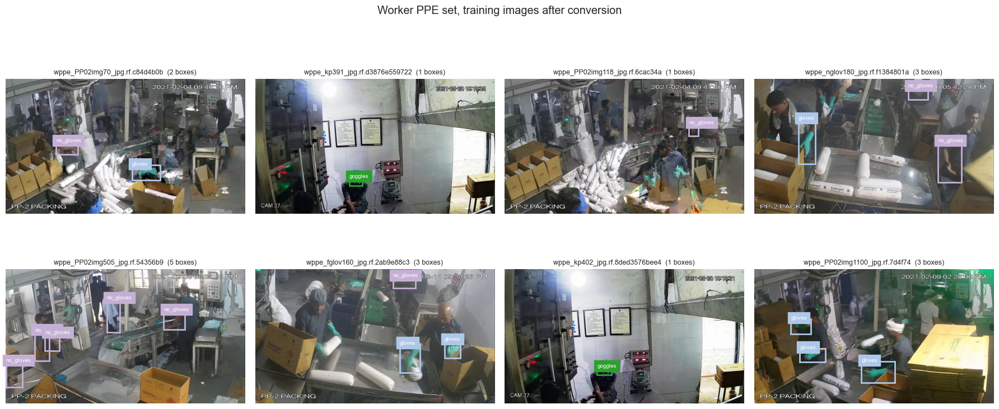

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/preview_wppe.png


In [71]:
wppe_preview = []
for record in STAGED:
    if record["source"] == "wppe" and record["folder"] == "pool":
        wppe_preview.append(record["image"])
preview_images(wppe_preview, "Worker PPE set, training images after conversion", "preview_wppe")

## 3b. SAMS site frames (optional)

Frames from your own cameras are the only images that show your workers, your gear, your floor and your lens. Label them in the shared class list (ids 0 to 11, as in section 0.4), including a `Person` box for every worker, and put them on Drive as:

```
datasets/vision/ppe/site/
    data.yaml            (optional; if present its names must match the shared list)
    train/images  train/labels
    val/images    val/labels
    test/images   test/labels
```

Split by recording or by day, not by frame, so that near-identical frames do not sit in two splits. The test split is scored on its own in section 14, which is the honest number for your site. If the folder is empty, this step does nothing.

Label checklist for site frames (YOLO, same class ids as Construction-PPE):

| Priority | What to capture |
|----------|-----------------|
| High | Workers **without** helmet / vest / gloves / boots (`no_*` classes) |
| High | Clear **feet** shots for `boots` and `no_boots` |
| Medium | Worn gear under shop lighting, phone camera angles SAMS will use |
| Always | Split by recording into `train` / `val` / `test`; keep empty frames for `background/` |

If this folder is empty the notebook still trains on public data, but test missing-gear recall will not reflect your site.


In [72]:
SITE_SPLITS = {"train": "pool", "val": "valcand", "test": "test"}

site_rows = []
if SITE_DIR.is_dir():
    site_yaml = SITE_DIR / "data.yaml"
    if site_yaml.is_file():
        site_names = yaml.safe_load(site_yaml.read_text())["names"]
        if isinstance(site_names, dict):
            site_names = {int(key): str(value) for key, value in site_names.items()}
        else:
            site_names = dict(enumerate(str(value) for value in site_names))
        for class_id, class_name in site_names.items():
            if CLASS_NAMES.get(class_id) != class_name:
                raise RuntimeError(f"Site class {class_id} is {class_name}, expected {CLASS_NAMES.get(class_id)}")
    for original_split, folder in SITE_SPLITS.items():
        images = list_images(SITE_DIR / original_split / "images")
        for image_path in images:
            rows = read_labels(SITE_DIR / original_split / "labels" / f"{image_path.stem}.txt")
            target = stage_image(image_path, rows, folder, "site")
            STAGED.append({"source": "site", "folder": folder, "original_split": original_split, "image": target})
        site_rows.append({"published split": original_split, "staged as": folder, "images": len(images)})

if any(row["images"] for row in site_rows):
    SOURCES.append("site")
    save_table(pd.DataFrame(site_rows).set_index("published split"), "site_staging")
else:
    display(pd.DataFrame([{"result": f"No site frames under {SITE_DIR}"}]))

,result
0,No site frames under /content/drive/MyDrive/SA...


## 4. Add the missing person boxes

Mendeley and the Worker PPE set do not label people. If those images went into training as they are, every worker in them would count as background, and the model would learn not to detect `Person`. The live service needs `Person` to place the head, torso, hand, and foot regions, so that would break every SAMS item.

A pretrained COCO detector (YOLOv8s) finds the people in those two sources, and its boxes above `PERSON_PSEUDO_CONF` are added as `Person` labels. This is done for train, val, and test of those sources, so the model is not marked wrong in val for finding a real person.

These boxes are machine-made. Construction-PPE keeps its human-drawn person boxes, so its test split is the cleanest check of `Person`.

In [73]:
person_model = YOLO("yolov8s.pt")

targets = []
for record in STAGED:
    if record["source"] in ("mend", "wppe"):
        targets.append(record)

images_seen = Counter()
images_with_person = Counter()
boxes_added = Counter()
PREDICT_CHUNK = 32
for start in range(0, len(targets), PREDICT_CHUNK):
    chunk = targets[start:start + PREDICT_CHUNK]
    chunk_paths = []
    for record in chunk:
        chunk_paths.append(str(record["image"]))
    results = person_model.predict(
        chunk_paths, conf=PERSON_PSEUDO_CONF, classes=[0], device=YOLO_DEVICE, verbose=False
    )
    for record, result in zip(chunk, results):
        key = (record["source"], record["folder"])
        images_seen[key] += 1
        label_file = label_path_for(record["image"])
        rows = read_labels(label_file)
        found = result.boxes.xywhn.cpu().numpy()
        for box in found:
            rows.append([PERSON_ID, float(box[0]), float(box[1]), float(box[2]), float(box[3])])
        if len(found) > 0:
            write_labels(label_file, rows)
            images_with_person[key] += 1
            boxes_added[key] += len(found)

pseudo_rows = []
for key in sorted(images_seen):
    pseudo_rows.append({
        "source": key[0],
        "folder": key[1],
        "images": images_seen[key],
        "images with a person found": images_with_person[key],
        "person boxes added": boxes_added[key],
    })

del person_model
gc.collect()
save_table(pd.DataFrame(pseudo_rows).set_index(["source", "folder"]), "person_pseudo_labels")

images  images with a person found  person boxes added
source folder                                                         
mend   pool       1829                        1785                7158
       valcand     457                         444                1794
wppe   pool       6227                        6204               17560
       test       1921                        1906                3707
       valcand    3498                        3477                7509

A quick look at a few images with the added person boxes. If the person boxes look wrong here, raise `PERSON_PSEUDO_CONF` and rerun section 4.

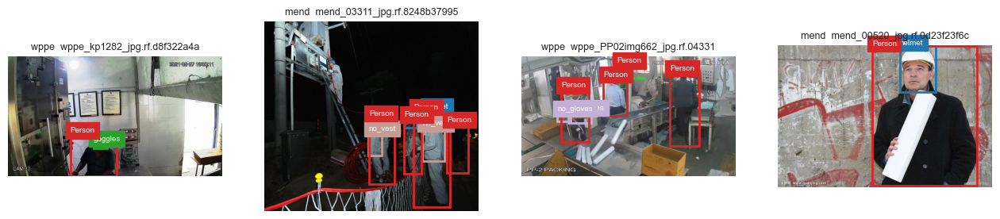

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/person_pseudo_label_samples.png


In [74]:
sample_records = []
for record in STAGED:
    if record["source"] in ("mend", "wppe") and record["folder"] == "pool":
        sample_records.append(record)
random.Random(SEED).shuffle(sample_records)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax in axes:
    ax.axis("off")
for ax, record in zip(axes, sample_records[:4]):
    rows = read_labels(label_path_for(record["image"]))
    draw_boxes(ax, record["image"], rows, title=f"{record['source']}  {record['image'].name[:28]}")
save_figure(fig, "person_pseudo_label_samples")

## 5. Remove duplicate images

Datasets built from video often contain the same frame more than once, and the same photo can appear in two splits. A training image that is also a val or test image makes the score look better than it is.

Each image gets a difference hash: it is shrunk to 9 by 8 grey pixels, and each bit records whether a pixel is brighter than its right-hand neighbour. Identical or nearly identical photos get the same 64-bit hash. The order of priority is test, then val, then training:

1. A val candidate with the same hash as a test image is removed.
2. A training image with the same hash as any val or test image is removed.
3. A repeat inside the training pool is removed, keeping the first copy.

In [75]:
def difference_hash(image_path):
    with Image.open(image_path) as image:
        small = image.convert("L").resize((9, 8))
    pixels = np.asarray(small, dtype=np.int16)
    brighter = pixels[:, 1:] > pixels[:, :-1]
    return np.packbits(brighter.flatten()).tobytes().hex()


for record in STAGED:
    record["hash"] = difference_hash(record["image"])

test_hashes = set()
for record in STAGED:
    if record["folder"] == "test":
        test_hashes.add(record["hash"])

removed = Counter()
kept_records = []
val_hashes = set()
for record in STAGED:
    if record["folder"] == "valcand" and record["hash"] in test_hashes:
        removed[(record["source"], "valcand", "same as a test image")] += 1
        continue
    if record["folder"] == "valcand":
        val_hashes.add(record["hash"])
    kept_records.append(record)

final_records = []
pool_hashes = set()
for record in kept_records:
    if record["folder"] != "pool":
        final_records.append(record)
        continue
    reason = None
    if record["hash"] in test_hashes or record["hash"] in val_hashes:
        reason = "same as a val or test image"
    elif record["hash"] in pool_hashes:
        reason = "repeat inside the training pool"
    if reason is None:
        pool_hashes.add(record["hash"])
        final_records.append(record)
        continue
    removed[(record["source"], "pool", reason)] += 1

kept_images = set()
for record in final_records:
    kept_images.add(record["image"])
for record in STAGED:
    if record["image"] not in kept_images:
        record["image"].unlink(missing_ok=True)
        label_path_for(record["image"]).unlink(missing_ok=True)

STAGED = final_records

removed_rows = []
for key, count in sorted(removed.items()):
    removed_rows.append({"source": key[0], "folder": key[1], "reason": key[2], "images removed": count})
if removed_rows:
    save_table(pd.DataFrame(removed_rows).set_index(["source", "folder"]), "duplicates_removed")
else:
    display(pd.DataFrame([{"result": "No duplicates found"}]))

reason  images removed
source folder                                                  
cpex   pool     repeat inside the training pool              10
       pool         same as a val or test image               5
mend   pool     repeat inside the training pool              18
       pool         same as a val or test image               8
       valcand             same as a test image               1
wppe   pool     repeat inside the training pool             647
       pool         same as a val or test image            1824
       valcand             same as a test image             674

## 6. One table of every image, and the fixed val and test splits

Two DataFrames are built here and used by everything after this point:

- `manifest`: one row per image, with its source, size, brightness, number of boxes, and a count column for each class.
- `boxes`: one row per box, with its class, position, size, and aspect ratio.

### How val and test are fixed

- **Test** is every published test image of every source. It is scored once, in section 14.
- **Val** is a random sample of at most `VAL_IMAGES_PER_SOURCE` published val images per source, so one large source does not decide which model wins.
- If a SAMS class still has fewer than `MIN_EVAL_BOXES` boxes in val, more real val images containing that class are added from the leftovers. No copies are made.
- Leftover val images are marked `unused` and are not used for training, so train and val stay fully separate.

In [76]:
manifest_rows = []
box_rows = []
for record in STAGED:
    image_path = record["image"]
    with Image.open(image_path) as image:
        width, height = image.size
        small = image.convert("L").resize((64, 64))
    brightness = float(np.asarray(small).mean())
    rows = read_labels(label_path_for(image_path))

    entry = {
        "image": str(image_path),
        "source": record["source"],
        "folder": record["folder"],
        "width": width,
        "height": height,
        "brightness": brightness,
        "boxes": len(rows),
    }
    for class_name in CLASS_NAMES.values():
        entry[class_name] = 0

    areas = []
    aspects = []
    centers_x = []
    centers_y = []
    for class_id, xc, yc, w, h in rows:
        class_name = CLASS_NAMES[class_id]
        entry[class_name] += 1
        box_w_px = w * width
        box_h_px = h * height
        aspect = box_w_px / max(box_h_px, 1e-6)
        areas.append(w * h)
        aspects.append(aspect)
        centers_x.append(xc)
        centers_y.append(yc)
        box_rows.append({
            "image": str(image_path),
            "source": record["source"],
            "class": class_name,
            "xc": xc,
            "yc": yc,
            "w": w,
            "h": h,
            "rel_area": w * h,
            "box_w_px": box_w_px,
            "box_h_px": box_h_px,
            "aspect": aspect,
            "size": size_bucket(w, h, width, height),
        })

    if areas:
        entry["mean_box_area"] = float(np.mean(areas))
        entry["mean_aspect"] = float(np.mean(aspects))
        entry["mean_xc"] = float(np.mean(centers_x))
        entry["mean_yc"] = float(np.mean(centers_y))
    else:
        entry["mean_box_area"] = 0.0
        entry["mean_aspect"] = 0.0
        entry["mean_xc"] = 0.5
        entry["mean_yc"] = 0.5
    manifest_rows.append(entry)

manifest = pd.DataFrame(manifest_rows)
boxes = pd.DataFrame(box_rows)
display(manifest.head())
display(boxes.head())

,image,source,folder,width,height,brightness,boxes,helmet,gloves,vest,boots,goggles,none,Person,no_helmet,no_goggle,no_gloves,no_boots,no_vest,mean_box_area,mean_aspect,mean_xc,mean_yc
0,/content/SAMS/datasets/vision/ppe/merged/image...,cpex,pool,640,640,34.581299,11,4,0,0,0,0,3,4,0,0,0,0,0,0.059553,0.858762,0.482516,0.493908
1,/content/SAMS/datasets/vision/ppe/merged/image...,cpex,pool,640,640,94.934570,3,1,0,0,0,0,1,1,0,0,0,0,0,0.139301,0.833421,0.553320,0.509669
2,/content/SAMS/datasets/vision/ppe/merged/image...,cpex,pool,640,640,156.378174,8,1,2,1,2,1,0,1,0,0,0,0,0,0.108175,1.378793,0.486498,0.523810
3,/content/SAMS/datasets/vision/ppe/merged/image...,cpex,pool,640,640,171.288330,8,1,2,1,2,1,0,1,0,0,0,0,0,0.031838,1.358442,0.381210,0.351625
4,/content/SAMS/datasets/vision/ppe/merged/image...,cpex,pool,640,640,172.059082,8,1,2,1,2,1,0,1,0,0,0,0,0,0.026787,1.323724,0.420037,0.374122


,image,source,class,xc,yc,w,h,rel_area,box_w_px,box_h_px,aspect,size
0,/content/SAMS/datasets/vision/ppe/merged/image...,cpex,helmet,0.421102,0.383109,0.101734,0.082469,0.008390,65.10976,52.78016,1.233603,medium
1,/content/SAMS/datasets/vision/ppe/merged/image...,cpex,helmet,0.245664,0.380945,0.119266,0.078141,0.009320,76.33024,50.01024,1.526292,medium
2,/content/SAMS/datasets/vision/ppe/merged/image...,cpex,Person,0.218617,0.540047,0.216234,0.456500,0.098711,138.38976,292.16000,0.473678,large
3,/content/SAMS/datasets/vision/ppe/merged/image...,cpex,Person,0.399352,0.550867,0.227484,0.448266,0.101973,145.58976,286.89024,0.507475,large
4,/content/SAMS/datasets/vision/ppe/merged/image...,cpex,Person,0.760930,0.529328,0.240266,0.482688,0.115974,153.77024,308.92032,0.497767,large


In [77]:
manifest["split"] = "unused"
manifest.loc[manifest["folder"] == "pool", "split"] = "train pool"
manifest.loc[manifest["folder"] == "test", "split"] = "test"

rng = np.random.default_rng(SEED)
for source in SOURCES:
    is_candidate = (manifest["folder"] == "valcand") & (manifest["source"] == source)
    candidate_index = manifest.index[is_candidate].to_numpy()
    if len(candidate_index) > VAL_IMAGES_PER_SOURCE:
        chosen = rng.choice(candidate_index, size=VAL_IMAGES_PER_SOURCE, replace=False)
    else:
        chosen = candidate_index
    manifest.loc[chosen, "split"] = "val"

topup_rows = []
for class_name in FOCUS_CLASSES:
    in_val = int(manifest.loc[manifest["split"] == "val", class_name].sum())
    added = 0
    if in_val < MIN_EVAL_BOXES:
        spare = manifest[(manifest["split"] == "unused") & (manifest[class_name] > 0)]
        spare = spare.sort_values(class_name, ascending=False)
        for index, row in spare.iterrows():
            if in_val >= MIN_EVAL_BOXES:
                break
            manifest.loc[index, "split"] = "val"
            in_val += int(row[class_name])
            added += 1
    topup_rows.append({"class": class_name, "val boxes after top-up": in_val, "real images added": added})
save_table(pd.DataFrame(topup_rows).set_index("class"), "val_top_up")

split_of_image = dict(zip(manifest["image"], manifest["split"]))
boxes["split"] = boxes["image"].map(split_of_image)

VAL_IMAGES = []
for image_path in manifest.loc[manifest["split"] == "val", "image"]:
    VAL_IMAGES.append(Path(image_path))
VAL_LIST = write_list("val", VAL_IMAGES)

TEST_LISTS = {}
TEST_LISTS["all"] = write_list("test_all", manifest.loc[manifest["split"] == "test", "image"])
for source in SOURCES:
    source_test = manifest.loc[(manifest["split"] == "test") & (manifest["source"] == source), "image"]
    if len(source_test) > 0:
        TEST_LISTS[source] = write_list(f"test_{source}", source_test)

list_rows = []
list_rows.append({"list": "val", "images": len(VAL_IMAGES), "file": str(VAL_LIST)})
for name, path in TEST_LISTS.items():
    list_rows.append({"list": f"test {name}", "images": len(read_list(path)), "file": str(path)})
display(pd.DataFrame(list_rows).set_index("list"))

,val boxes after top-up,real images added
class,,
helmet,704,0
no_helmet,293,0
vest,460,0
no_vest,221,0
gloves,470,0
no_gloves,535,0
boots,316,0
no_boots,137,0


,images,file
list,,
val,1599,/content/SAMS/datasets/vision/ppe/merged/lists...
test all,2062,/content/SAMS/datasets/vision/ppe/merged/lists...
test cpex,141,/content/SAMS/datasets/vision/ppe/merged/lists...
test wppe,1921,/content/SAMS/datasets/vision/ppe/merged/lists...


The table below checks that each SAMS class has enough real boxes to be scored. A class marked `False` will have a noisy score. The fix is more real images of that class, not copies.

In [78]:
eval_table = pd.DataFrame(index=FOCUS_CLASSES)
eval_table.index.name = "class"
for split_name in ["train pool", "val", "test"]:
    subset = manifest[manifest["split"] == split_name]
    column = []
    for class_name in FOCUS_CLASSES:
        column.append(int(subset[class_name].sum()))
    eval_table[split_name] = column
eval_table["val has enough"] = eval_table["val"] >= MIN_EVAL_BOXES
eval_table["test has enough"] = eval_table["test"] >= MIN_EVAL_BOXES
save_table(eval_table, "eval_split_sufficiency")

,train pool,val,test,val has enough,test has enough
class,,,,,
helmet,3265,704,1432,True,True
no_helmet,1351,293,1107,True,True
vest,2330,460,178,True,True
no_vest,830,221,0,True,False
gloves,4730,470,163,True,True
no_gloves,4493,535,58,True,True
boots,1217,316,313,True,True
no_boots,88,137,84,True,True


### Preview of val and test

Eight random images from each fixed split, with all their labels. These are the images every experiment is scored on, so they should look like real work sites with real workers, not close-ups or copies.

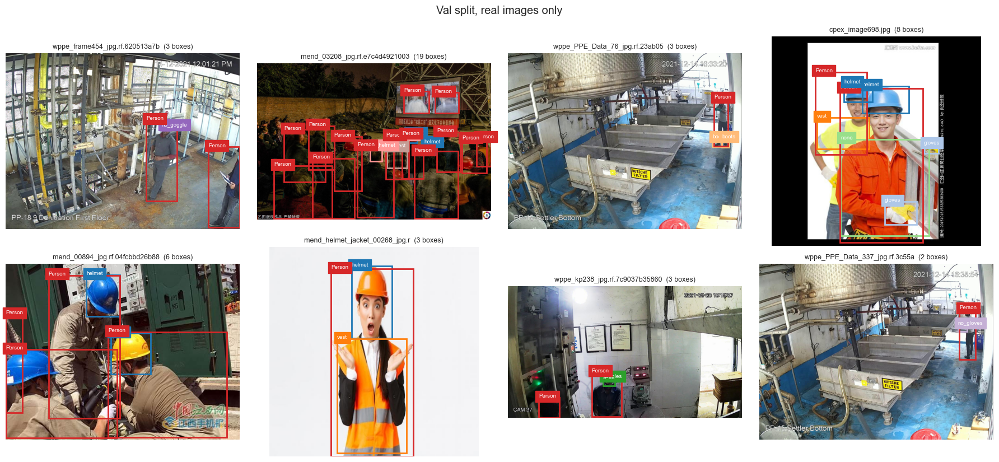

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/preview_val.png


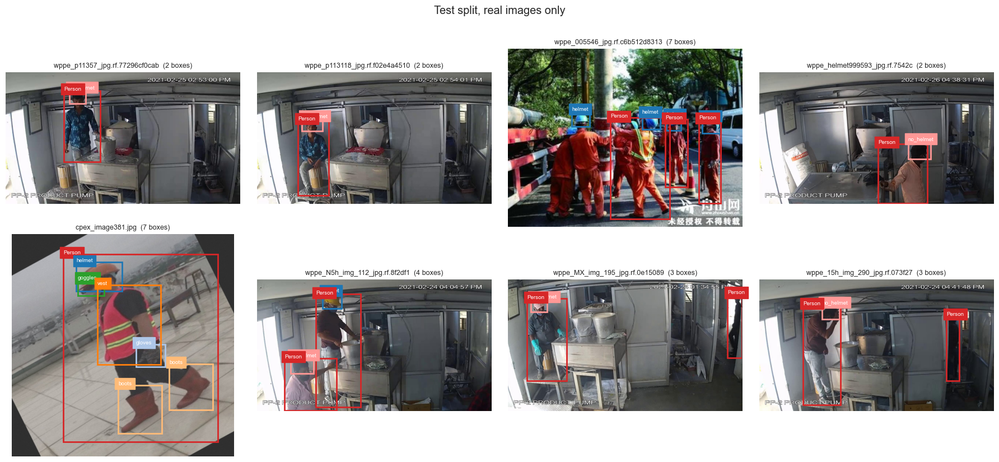

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/preview_test.png


In [79]:
val_preview = manifest.loc[manifest["split"] == "val", "image"]
preview_images(val_preview, "Val split, real images only", "preview_val")

test_preview = manifest.loc[manifest["split"] == "test", "image"]
preview_images(test_preview, "Test split, real images only", "preview_test")

## 7. Exploratory data analysis

The EDA answers five questions before any training:

1. How much data is there per source and split?
2. Which classes are rare, and which source supplies each class?
3. How big are the boxes? Gloves and shoes are expected to be small.
4. Do the sources look different (resolution, brightness, where the boxes sit)?
5. Which classes appear together? This decides how balancing behaves, because copying an image copies every box in it.

Unless a cell says otherwise, the EDA uses every image that is in train pool, val, or test. Leftover val images marked `unused` are left out.

### 7.1 Images per source and split

split,test,train pool,val,total
source,,,,
cpex,141,1117,143,1401
mend,0,1803,456,2259
wppe,1921,3756,1000,6677


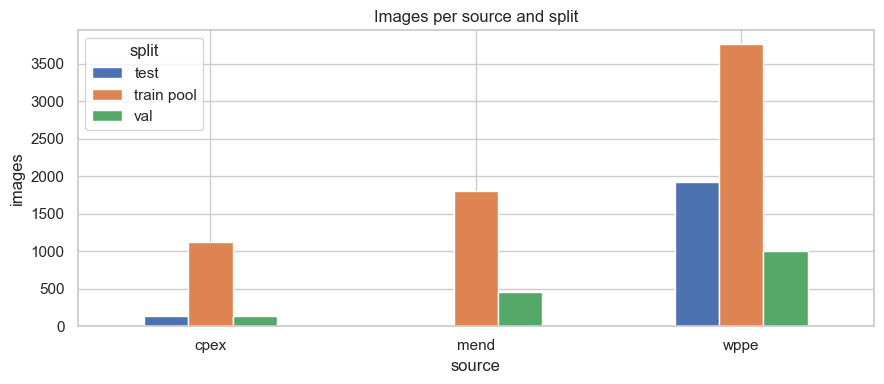

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_images_per_source_split.png


In [80]:
used_manifest = manifest[manifest["split"] != "unused"]
split_table = pd.crosstab(used_manifest["source"], used_manifest["split"])
split_table["total"] = split_table.sum(axis=1)
save_table(split_table, "eda_images_per_source_split")

fig, ax = plt.subplots(figsize=(9, 4))
split_table.drop(columns="total").plot(kind="bar", ax=ax)
ax.set_title("Images per source and split")
ax.set_xlabel("source")
ax.set_ylabel("images")
plt.xticks(rotation=0)
plt.tight_layout()
save_figure(fig, "eda_images_per_source_split")

### 7.2 Boxes per class and per source

The stacked bars show which source supplies each class. A class that comes from only one source is a risk: the model may learn that source's look instead of the gear.

source,cpex,mend,wppe,total
class,,,,
helmet,1716,2392,1293,5401
gloves,1420,0,3943,5363
vest,1600,1368,0,2968
boots,1579,0,267,1846
goggles,516,0,1704,2220
none,797,0,0,797
Person,2230,8870,18431,29531
no_helmet,485,1165,1101,2751
no_goggle,411,0,2022,2433


split,test,train pool,val
class,,,
helmet,1432,3265,704
gloves,163,4730,470
vest,178,2330,460
boots,313,1217,316
goggles,352,1489,379
none,65,651,81
Person,3943,21241,4347
no_helmet,1107,1351,293
no_goggle,110,1802,521


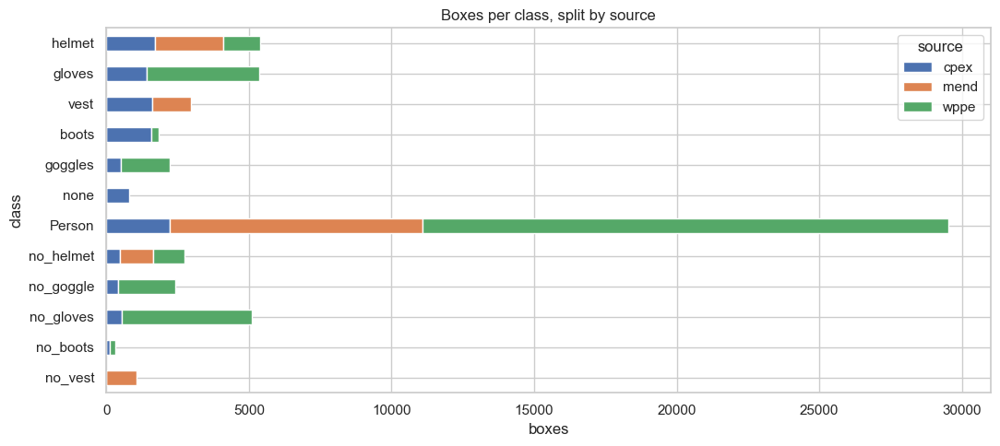

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_boxes_per_class_source.png


In [81]:
used_boxes = boxes[boxes["split"] != "unused"]
class_order = list(CLASS_NAMES.values())

class_source = pd.crosstab(used_boxes["class"], used_boxes["source"])
class_source = class_source.reindex(class_order, fill_value=0)
class_source["total"] = class_source.sum(axis=1)
save_table(class_source, "eda_boxes_per_class_source")

class_split = pd.crosstab(used_boxes["class"], used_boxes["split"])
class_split = class_split.reindex(class_order, fill_value=0)
save_table(class_split, "eda_boxes_per_class_split")

fig, ax = plt.subplots(figsize=(11, 5))
class_source.drop(columns="total").plot(kind="barh", stacked=True, ax=ax)
ax.set_title("Boxes per class, split by source")
ax.set_xlabel("boxes")
ax.invert_yaxis()
plt.tight_layout()
save_figure(fig, "eda_boxes_per_class_source")

### 7.3 Boxes per image

Crowded images make small gear harder to find, and they also matter for balancing: an image with many boxes adds many boxes of common classes when it is copied.

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
cpex,1401.0,8.15,5.78,1.0,5.0,7.0,8.0,58.0
mend,2259.0,6.57,4.27,1.0,3.0,5.0,9.0,35.0
wppe,6677.0,5.01,2.55,1.0,3.0,5.0,7.0,25.0


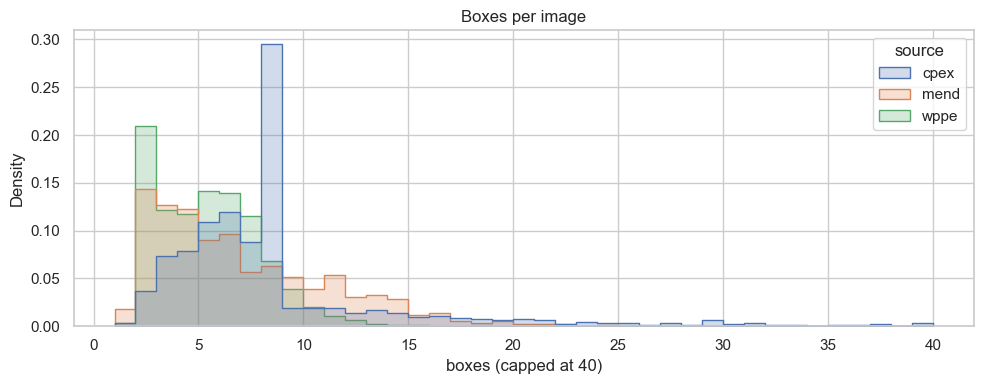

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_boxes_per_image.png


In [82]:
per_image = used_manifest.groupby("source")["boxes"].describe()
save_table(per_image.round(2), "eda_boxes_per_image")

fig, ax = plt.subplots(figsize=(10, 4))
clipped = used_manifest.copy()
clipped["boxes (capped at 40)"] = clipped["boxes"].clip(upper=40)
sns.histplot(data=clipped, x="boxes (capped at 40)", hue="source", binwidth=1,
             stat="density", common_norm=False, element="step", ax=ax)
ax.set_title("Boxes per image")
plt.tight_layout()
save_figure(fig, "eda_boxes_per_image")

### 7.4 Box size

Box area is shown as a share of the image area, on a log scale. The size table uses the COCO convention after the image is resized to 640 pixels for training: small is under 32 by 32 pixels, medium is under 96 by 96, large is anything bigger. A class that is mostly small is a reason to test the larger image size in section 11.

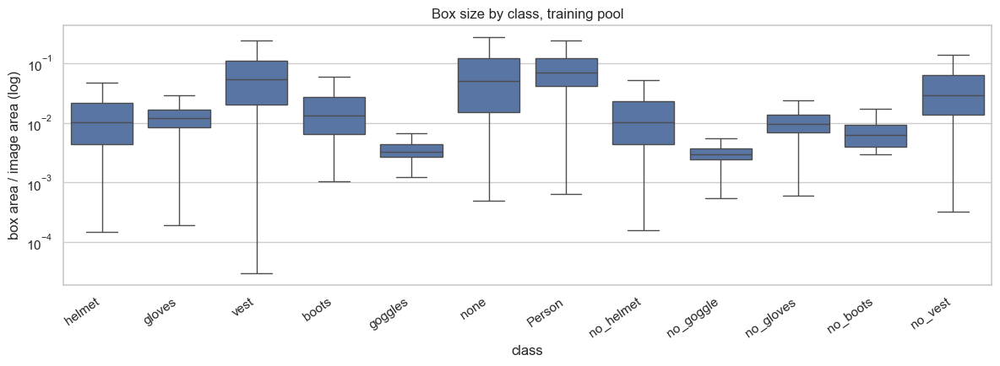

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_box_area_by_class.png


size,small,medium,large
class,,,
helmet,18.4,62.0,19.6
gloves,2.7,96.1,1.2
vest,3.0,28.8,68.1
boots,6.0,59.2,34.8
goggles,70.7,28.9,0.3
none,5.7,29.3,65.0
Person,0.9,20.4,78.7
no_helmet,19.3,60.5,20.2
no_goggle,85.5,14.5,0.1


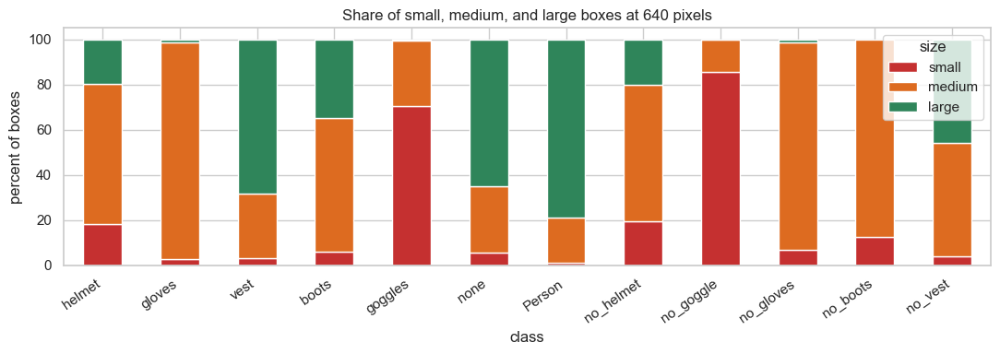

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_box_size_share.png


In [83]:
pool_boxes = boxes[boxes["split"] == "train pool"]
present_classes = []
for class_name in class_order:
    if class_name in set(pool_boxes["class"]):
        present_classes.append(class_name)

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=pool_boxes, x="class", y="rel_area", order=present_classes, showfliers=False, ax=ax)
ax.set_yscale("log")
ax.set_ylabel("box area / image area (log)")
ax.set_title("Box size by class, training pool")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
save_figure(fig, "eda_box_area_by_class")

size_table = pd.crosstab(pool_boxes["class"], pool_boxes["size"], normalize="index") * 100
size_table = size_table.reindex(index=present_classes, columns=["small", "medium", "large"], fill_value=0)
size_table = size_table.round(1)
save_table(size_table, "eda_box_size_share_percent")

fig, ax = plt.subplots(figsize=(11, 4))
size_table.plot(kind="bar", stacked=True, ax=ax, color=["#c53030", "#dd6b20", "#2f855a"])
ax.set_ylabel("percent of boxes")
ax.set_title("Share of small, medium, and large boxes at 640 pixels")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
save_figure(fig, "eda_box_size_share")

### 7.5 Box shape

Aspect ratio is width divided by height. A vest is usually taller than wide, a shoe usually wider than tall. A class whose shape varies a lot is harder to box tightly, which shows up as a lower mAP50-95 than mAP50.

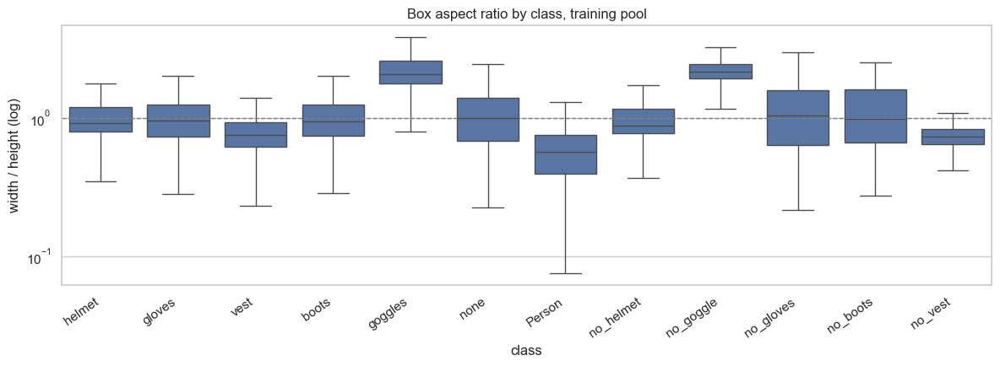

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_box_aspect_by_class.png


,count,25%,50%,75%
class,,,,
helmet,3265.0,0.80,0.92,1.19
gloves,4730.0,0.73,0.96,1.24
vest,2330.0,0.62,0.75,0.93
boots,1217.0,0.74,0.93,1.25
goggles,1489.0,1.77,2.05,2.58
none,651.0,0.68,1.00,1.39
Person,21241.0,0.39,0.57,0.75
no_helmet,1351.0,0.78,0.88,1.16
no_goggle,1802.0,1.92,2.15,2.44


In [84]:
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=pool_boxes, x="class", y="aspect", order=present_classes, showfliers=False, ax=ax)
ax.set_yscale("log")
ax.axhline(1.0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("width / height (log)")
ax.set_title("Box aspect ratio by class, training pool")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
save_figure(fig, "eda_box_aspect_by_class")

aspect_table = pool_boxes.groupby("class")["aspect"].describe()[["count", "25%", "50%", "75%"]]
save_table(aspect_table.reindex(present_classes).round(2), "eda_box_aspect_by_class")

### 7.6 Where the gear sits in the image

Each panel is a 2D histogram of box centers, with the top of the image at the top. Helmets should sit high, shoes low. If one source always has its gear in the same place, the model may learn the position instead of the object.

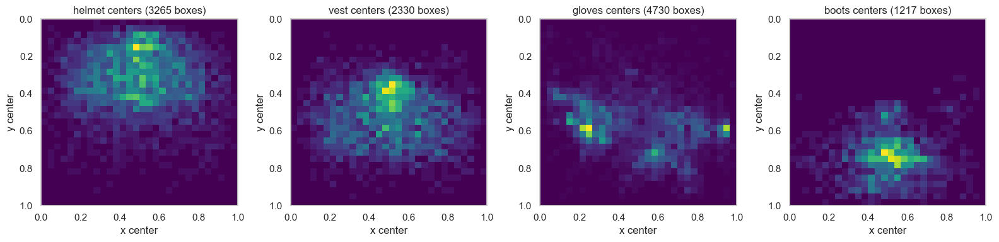

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_box_center_heatmaps.png


In [85]:
heatmap_classes = ["helmet", "vest", "gloves", "boots"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, class_name in zip(axes, heatmap_classes):
    class_boxes = pool_boxes[pool_boxes["class"] == class_name]
    if class_boxes.empty:
        ax.set_title(f"{class_name}: no boxes")
        ax.axis("off")
        continue
    ax.hist2d(class_boxes["xc"], class_boxes["yc"], bins=30, range=[[0, 1], [0, 1]], cmap="viridis")
    ax.invert_yaxis()
    ax.set_title(f"{class_name} centers ({len(class_boxes)} boxes)")
    ax.set_xlabel("x center")
    ax.set_ylabel("y center")
plt.tight_layout()
save_figure(fig, "eda_box_center_heatmaps")

### 7.7 Image resolution and brightness by source

Large differences between sources mean the model sees several different "looks". The robustness test in section 13 checks whether the chosen model holds up when images get darker, blurrier, or smaller.

,images,median_width,median_height,min_width,max_width,mean_brightness,std_brightness
source,,,,,,,
cpex,1401,640.0,640.0,408,1024,127.6,38.3
mend,2259,640.0,640.0,128,5712,120.8,36.8
wppe,6677,1280.0,720.0,200,2688,115.2,15.8


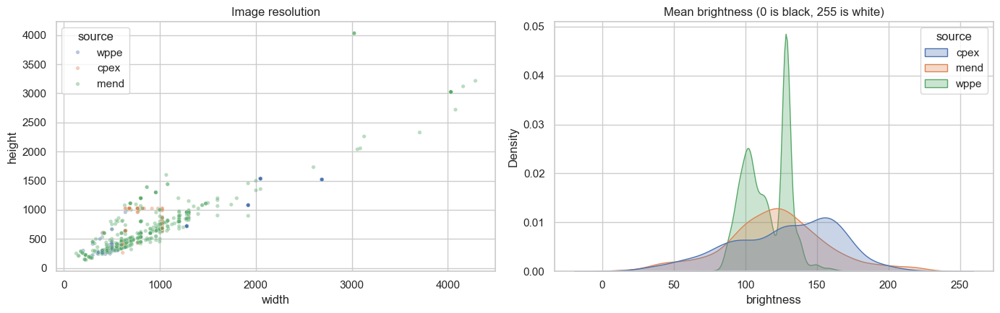

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_resolution_brightness.png


In [86]:
look_table = used_manifest.groupby("source").agg(
    images=("image", "count"),
    median_width=("width", "median"),
    median_height=("height", "median"),
    min_width=("width", "min"),
    max_width=("width", "max"),
    mean_brightness=("brightness", "mean"),
    std_brightness=("brightness", "std"),
)
save_table(look_table.round(1), "eda_resolution_brightness")

plot_sample = used_manifest
if len(plot_sample) > 4000:
    plot_sample = used_manifest.sample(4000, random_state=SEED)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=plot_sample, x="width", y="height", hue="source", alpha=0.4, s=15, ax=axes[0])
axes[0].set_title("Image resolution")
sns.kdeplot(data=used_manifest, x="brightness", hue="source", common_norm=False, fill=True, alpha=0.3, ax=axes[1])
axes[1].set_title("Mean brightness (0 is black, 255 is white)")
plt.tight_layout()
save_figure(fig, "eda_resolution_brightness")

### 7.8 Which classes appear together

Each cell is the percent of training images that contain the row class and also contain the column class. For example, the `gloves` row and `Person` column is the share of glove images that also show a person. Balancing copies whole images, so a rare class that always appears next to a common one will raise the common one too.

,helmet,gloves,vest,boots,goggles,none,Person,no_helmet,no_goggle,no_gloves,no_boots,no_vest
helmet,100.0,27.0,54.0,24.4,18.5,4.9,97.1,9.0,0.3,0.2,0.2,15.2
gloves,24.0,100.0,23.4,19.4,15.4,1.8,98.7,0.4,0.3,59.9,0.2,0.0
vest,72.4,35.2,100.0,33.1,24.6,5.7,94.3,6.3,0.1,0.1,0.0,4.1
boots,90.0,80.5,91.0,100.0,61.5,12.6,97.3,4.8,3.8,4.0,0.4,0.0
goggles,27.8,26.0,27.6,25.1,100.0,2.7,99.6,1.5,25.2,1.2,0.4,0.0
none,27.1,11.0,23.6,19.0,9.8,100.0,98.0,66.3,61.7,54.2,8.1,0.0
Person,28.6,32.6,20.7,7.8,19.5,5.2,100.0,11.1,19.7,29.6,0.4,7.8
no_helmet,23.8,1.2,12.3,3.4,2.6,31.5,99.0,100.0,28.9,25.2,3.6,28.3
no_goggle,0.4,0.5,0.1,1.5,24.9,16.5,99.8,16.3,100.0,13.5,1.7,0.0
no_gloves,0.2,66.0,0.1,1.1,0.8,9.6,98.7,9.4,8.9,100.0,1.1,0.0


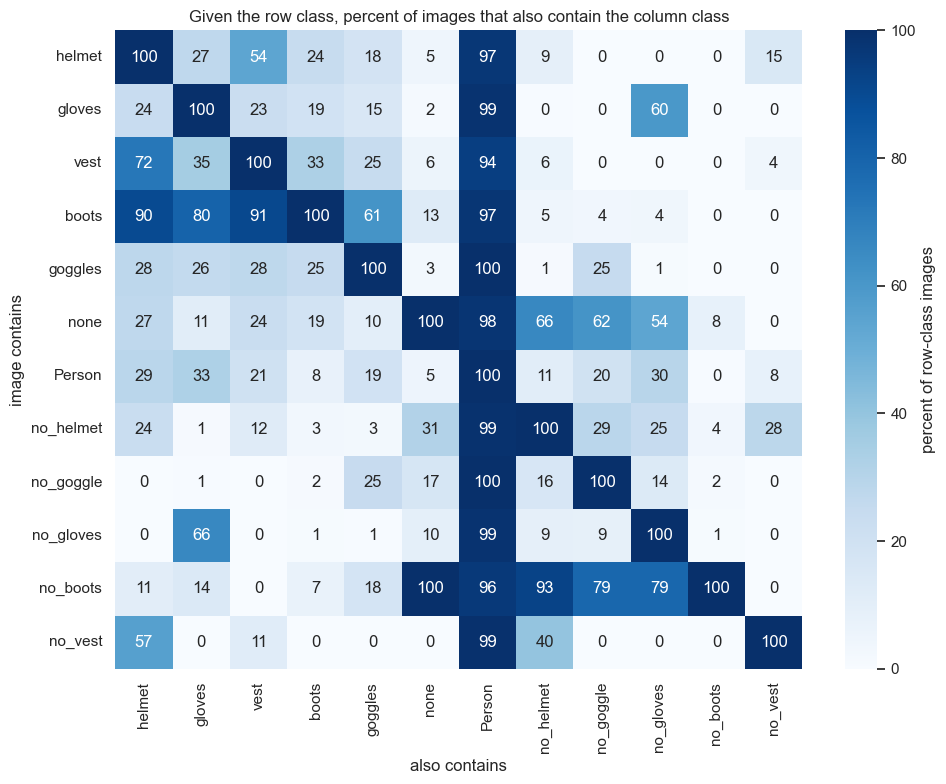

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_class_cooccurrence.png


In [87]:
pool_images = manifest[manifest["split"] == "train pool"]
presence = (pool_images[class_order] > 0).astype(int)
together = presence.T.dot(presence)
images_with_class = np.diag(together).astype(float)
images_with_class[images_with_class == 0] = np.nan
conditional = together.div(images_with_class, axis=0) * 100
save_table(conditional.round(1), "eda_class_cooccurrence_percent")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(conditional, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=ax,
            cbar_kws={"label": "percent of row-class images"})
ax.set_title("Given the row class, percent of images that also contain the column class")
ax.set_xlabel("also contains")
ax.set_ylabel("image contains")
plt.tight_layout()
save_figure(fig, "eda_class_cooccurrence")

### 7.9 Example images per SAMS class

One random training image per SAMS class, with all of its labels drawn. This is the quickest way to spot label problems such as missing boxes or boxes on the wrong object.

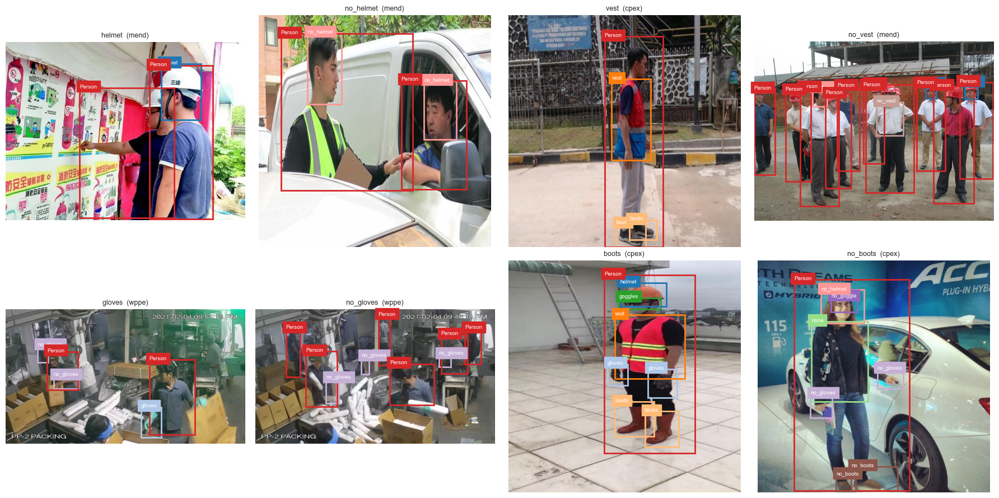

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_examples_per_class.png


In [88]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
flat_axes = axes.flatten()
for ax, class_name in zip(flat_axes, FOCUS_CLASSES):
    candidates = pool_images[pool_images[class_name] > 0]
    if candidates.empty:
        ax.set_title(f"{class_name}: no images")
        ax.axis("off")
        continue
    chosen = candidates.sample(1, random_state=SEED).iloc[0]
    rows = read_labels(label_path_for(chosen["image"]))
    draw_boxes(ax, chosen["image"], rows, title=f"{class_name}  ({chosen['source']})")
plt.tight_layout()
save_figure(fig, "eda_examples_per_class")

### 7.10 The same class in each source

One row per source, one column per SAMS class. Only the boxes of that column's class are drawn. This shows whether, for example, a glove in the Worker PPE set looks like a glove in Construction-PPE: same size, same angle, same kind of scene. A blank tile means that source has no training images of that class, so the model learns that class only from the other sources.

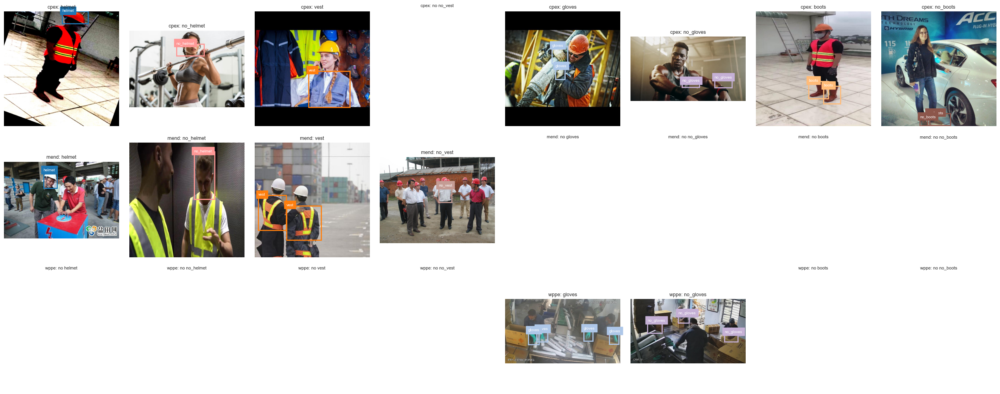

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/eda_class_by_source_grid.png


In [89]:
fig, axes = plt.subplots(
    len(SOURCES), len(FOCUS_CLASSES),
    figsize=(3.2 * len(FOCUS_CLASSES), 3.4 * len(SOURCES)),
)
for row_number, source in enumerate(SOURCES):
    for column_number, class_name in enumerate(FOCUS_CLASSES):
        ax = axes[row_number, column_number]
        ax.axis("off")
        has_class = (pool_images["source"] == source) & (pool_images[class_name] > 0)
        candidates = pool_images[has_class]
        if candidates.empty:
            ax.set_title(f"{source}: no {class_name}", fontsize=8)
            continue
        chosen = candidates.sample(1, random_state=SEED).iloc[0]
        class_rows = []
        for row in read_labels(label_path_for(chosen["image"])):
            if CLASS_NAMES[row[0]] == class_name:
                class_rows.append(row)
        draw_boxes(ax, chosen["image"], class_rows, title=f"{source}: {class_name}")
plt.tight_layout()
save_figure(fig, "eda_class_by_source_grid")

### 7.11 What the EDA means for balancing

This table is the input to section 9. `gap to target` is how many training boxes each SAMS class is missing. `sources` shows where real images for that class can come from. A class with one source and a large gap is where augmentation will have to do the most work.

In [90]:
gap_rows = []
for class_name in FOCUS_CLASSES:
    total = int(pool_images[class_name].sum())
    images_with = int((pool_images[class_name] > 0).sum())
    sources_with = sorted(pool_images.loc[pool_images[class_name] > 0, "source"].unique())
    gap_rows.append({
        "class": class_name,
        "train pool boxes": total,
        "images containing it": images_with,
        "sources": ", ".join(sources_with),
        "target": TARGET_BOXES_PER_CLASS,
        "gap to target": max(0, TARGET_BOXES_PER_CLASS - total),
    })
save_table(pd.DataFrame(gap_rows).set_index("class"), "eda_balance_gap")

,train pool boxes,images containing it,sources,target,gap to target
class,,,,,
helmet,3265,1926,"cpex, mend",3000,0
no_helmet,1351,731,"cpex, mend",3000,1649
vest,2330,1437,"cpex, mend",3000,670
no_vest,830,516,mend,3000,2170
gloves,4730,2164,"cpex, wppe",3000,0
no_gloves,4493,1964,"cpex, wppe",3000,0
boots,1217,522,cpex,3000,1783
no_boots,88,28,cpex,3000,2912


## 8. PCA

PCA (principal component analysis) turns many correlated numbers into a few new axes, ordered by how much of the variation they explain. Plotting the first two axes shows the structure of the data in one picture.

Two PCAs are run:

1. **Image level**: one row per image, built from its class counts and box statistics. This shows whether the three sources look like one dataset or three separate ones, and whether val and test cover the same kinds of images as training.
2. **Object level**: one row per gear crop, built from a pretrained ResNet-18 image embedding. This shows whether worn and missing versions of an item look different enough to be told apart.

### 8.1 Image-level PCA

Each feature is standardised (mean 0, standard deviation 1) first, so that large numbers such as image width do not dominate small ones such as class counts.

,explained variance %,cumulative %
component,,
PC1,14.9,14.9
PC2,11.3,26.2
PC3,10.2,36.4
PC4,8.6,45.0
PC5,7.8,52.8


,PC1,PC2
width,0.410,0.250
boxes,-0.404,0.440
helmet,-0.380,0.015
height,0.336,0.291
vest,-0.325,0.061
Person,-0.293,0.267
mean_aspect,0.275,0.170
no_vest,-0.179,0.041
no_goggle,0.162,0.297
boots,-0.155,0.233


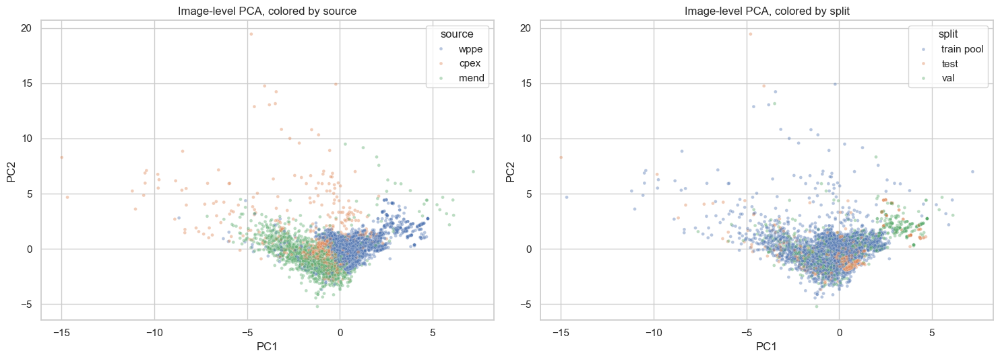

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/pca_image_level.png


In [91]:
IMAGE_FEATURES = list(CLASS_NAMES.values()) + [
    "boxes", "width", "height", "brightness", "mean_box_area", "mean_aspect", "mean_xc", "mean_yc",
]

pca_data = used_manifest.copy()
feature_matrix = pca_data[IMAGE_FEATURES].to_numpy(dtype=float)
scaled_features = StandardScaler().fit_transform(feature_matrix)

image_pca = PCA(n_components=5, random_state=SEED)
image_components = image_pca.fit_transform(scaled_features)
pca_data["PC1"] = image_components[:, 0]
pca_data["PC2"] = image_components[:, 1]

variance_rows = []
cumulative = 0.0
for index, ratio in enumerate(image_pca.explained_variance_ratio_):
    cumulative += ratio
    variance_rows.append({"component": f"PC{index + 1}", "explained variance %": ratio * 100, "cumulative %": cumulative * 100})
save_table(pd.DataFrame(variance_rows).set_index("component").round(1), "pca_image_explained_variance")

loadings = pd.DataFrame(image_pca.components_[:2].T, index=IMAGE_FEATURES, columns=["PC1", "PC2"])
loadings["abs PC1"] = loadings["PC1"].abs()
loadings = loadings.sort_values("abs PC1", ascending=False).drop(columns="abs PC1")
save_table(loadings.round(3), "pca_image_loadings")

plot_points = pca_data
if len(plot_points) > 6000:
    plot_points = pca_data.sample(6000, random_state=SEED)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=plot_points, x="PC1", y="PC2", hue="source", alpha=0.4, s=12, ax=axes[0])
axes[0].set_title("Image-level PCA, colored by source")
sns.scatterplot(data=plot_points, x="PC1", y="PC2", hue="split", alpha=0.4, s=12, ax=axes[1])
axes[1].set_title("Image-level PCA, colored by split")
plt.tight_layout()
save_figure(fig, "pca_image_level")

How to read it: if the sources form separate clouds, the model has to cover three different looks. If val or test points sit where there are no training points, those images are unlike anything in training and will score lower.

### 8.2 Object-level PCA of gear crops

Up to 150 boxes per SAMS class are cropped from the training pool (boxes smaller than 16 pixels are skipped), with 10 percent padding so some of the surrounding arm, leg, or head is visible. Each crop goes through ResNet-18 pretrained on ImageNet, which gives a 512-number description of what the crop looks like. The detector is not used here, so this measures how hard the classes are before any training.

In [92]:
import torchvision

CROPS_PER_CLASS = 150
CROP_PADDING = 0.10

resnet_weights = torchvision.models.ResNet18_Weights.DEFAULT
backbone = torchvision.models.resnet18(weights=resnet_weights)
backbone.fc = torch.nn.Identity()
backbone = backbone.eval().to(TORCH_DEVICE)
preprocess = resnet_weights.transforms()


def crop_object(image_path, xc, yc, w, h, padding=CROP_PADDING):
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    half_w = w * width * (1 + padding) / 2
    half_h = h * height * (1 + padding) / 2
    center_x = xc * width
    center_y = yc * height
    left = max(0, int(center_x - half_w))
    top = max(0, int(center_y - half_h))
    right = min(width, int(center_x + half_w))
    bottom = min(height, int(center_y + half_h))
    return image.crop((left, top, right, bottom))


crop_candidates = pool_boxes[
    pool_boxes["class"].isin(FOCUS_CLASSES)
    & (pool_boxes["box_w_px"] >= 16)
    & (pool_boxes["box_h_px"] >= 16)
]
sampled_parts = []
for class_name in FOCUS_CLASSES:
    class_rows = crop_candidates[crop_candidates["class"] == class_name]
    if len(class_rows) > CROPS_PER_CLASS:
        class_rows = class_rows.sample(CROPS_PER_CLASS, random_state=SEED)
    sampled_parts.append(class_rows)
crop_table = pd.concat(sampled_parts).reset_index(drop=True)

embedding_parts = []
with torch.no_grad():
    for start in range(0, len(crop_table), 64):
        chunk = crop_table.iloc[start:start + 64]
        tensors = []
        for _, row in chunk.iterrows():
            crop = crop_object(row["image"], row["xc"], row["yc"], row["w"], row["h"])
            tensors.append(preprocess(crop))
        batch = torch.stack(tensors).to(TORCH_DEVICE)
        embedding_parts.append(backbone(batch).cpu().numpy())
crop_embeddings = np.concatenate(embedding_parts)

del backbone
gc.collect()
if HAS_GPU:
    torch.cuda.empty_cache()

crop_counts = crop_table["class"].value_counts().reindex(FOCUS_CLASSES, fill_value=0)
display(crop_counts.to_frame("crops embedded"))

,crops embedded
class,
helmet,150
no_helmet,150
vest,150
no_vest,150
gloves,150
no_gloves,150
boots,150
no_boots,88


The scatter plots show the crops on the first two components. The pair panels show each worn class against its missing class.

The separability table goes one step further: a simple logistic regression is trained, with 5-fold cross-validation, to tell the worn crops of an item from the missing crops, using the first 50 components. An accuracy near 0.5 means the two look alike even to a strong pretrained network, so the detector will need more and cleaner examples of that pair. An accuracy near 1.0 means they are easy to tell apart.

,explained variance %
component,
PC1,8.800000
PC2,4.900000
first 50,64.400002


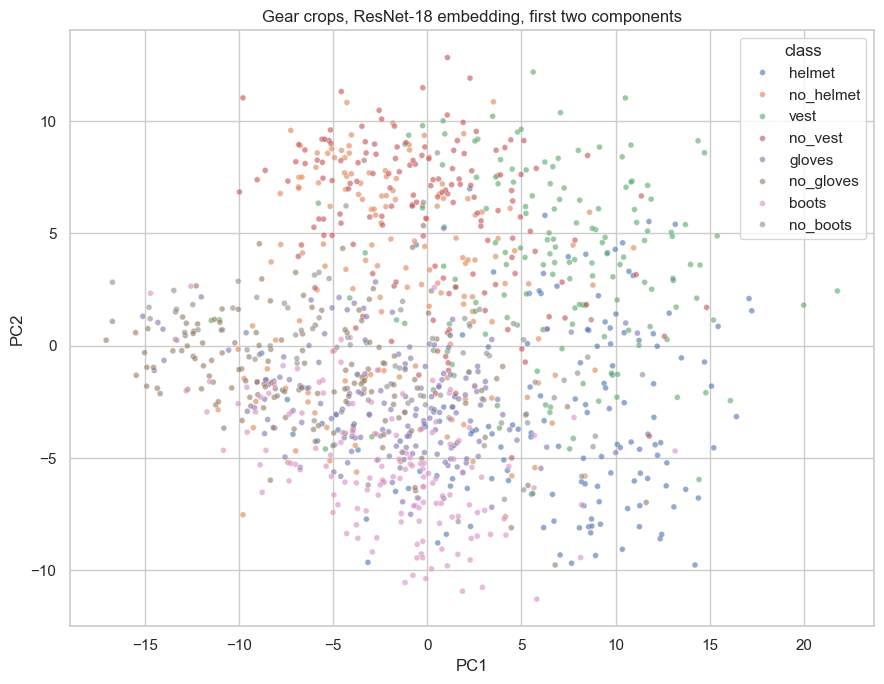

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/pca_crops_all_classes.png


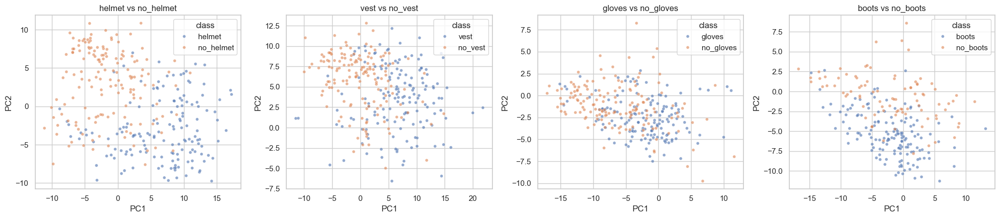

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/pca_crops_worn_vs_missing.png


,worn crops,missing crops,balanced accuracy mean,balanced accuracy std
pair,,,,
helmet vs no_helmet,150,150,0.907,0.034
vest vs no_vest,150,150,0.887,0.032
gloves vs no_gloves,150,150,0.907,0.033
boots vs no_boots,150,88,0.849,0.077


In [93]:
component_count = min(50, crop_embeddings.shape[0], crop_embeddings.shape[1])
crop_pca = PCA(n_components=component_count, random_state=SEED)
crop_components = crop_pca.fit_transform(StandardScaler().fit_transform(crop_embeddings))
crop_table["PC1"] = crop_components[:, 0]
crop_table["PC2"] = crop_components[:, 1]

crop_variance = pd.DataFrame({
    "component": ["PC1", "PC2", f"first {component_count}"],
    "explained variance %": [
        crop_pca.explained_variance_ratio_[0] * 100,
        crop_pca.explained_variance_ratio_[1] * 100,
        crop_pca.explained_variance_ratio_.sum() * 100,
    ],
}).set_index("component").round(1)
save_table(crop_variance, "pca_crop_explained_variance")

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=crop_table, x="PC1", y="PC2", hue="class", hue_order=FOCUS_CLASSES, alpha=0.6, s=18, ax=ax)
ax.set_title("Gear crops, ResNet-18 embedding, first two components")
plt.tight_layout()
save_figure(fig, "pca_crops_all_classes")

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
separability_rows = []
for ax, (worn_name, missing_name) in zip(axes, WORN_MISSING_PAIRS):
    pair_mask = crop_table["class"].isin([worn_name, missing_name]).to_numpy()
    pair_rows = crop_table[pair_mask]
    sns.scatterplot(data=pair_rows, x="PC1", y="PC2", hue="class", alpha=0.6, s=18, ax=ax)
    ax.set_title(f"{worn_name} vs {missing_name}")

    worn_count = int((pair_rows["class"] == worn_name).sum())
    missing_count = int((pair_rows["class"] == missing_name).sum())
    row = {"pair": f"{worn_name} vs {missing_name}", "worn crops": worn_count, "missing crops": missing_count}
    if worn_count >= 10 and missing_count >= 10:
        features = crop_components[pair_mask]
        target = (pair_rows["class"] == missing_name).astype(int).to_numpy()
        classifier = LogisticRegression(max_iter=2000)
        scores = cross_val_score(classifier, features, target, cv=5, scoring="balanced_accuracy")
        row["balanced accuracy mean"] = round(float(scores.mean()), 3)
        row["balanced accuracy std"] = round(float(scores.std()), 3)
    else:
        row["balanced accuracy mean"] = np.nan
        row["balanced accuracy std"] = np.nan
    separability_rows.append(row)
plt.tight_layout()
save_figure(fig, "pca_crops_worn_vs_missing")

save_table(pd.DataFrame(separability_rows).set_index("pair"), "pca_crop_separability")

## 9. Build the training sets

Three training sets are built so the experiments can show what each data step adds:

| Training set | How it is built |
|--------------|-----------------|
| full | Every image in the training pool, as published. This is the baseline |
| curated | Real images chosen from all three sources so each SAMS class gets close to `TARGET_BOXES_PER_CLASS`, plus a share of background images |
| balanced | The curated set, plus augmented copies that fill whatever gap real images could not |

Val and test are the same for all three.

### 9.1 Full training set

In [94]:
TRAIN_LISTS = {}
TRAIN_LISTS["full"] = write_list("train_full", pool_images["image"])
display(pd.DataFrame([{"training set": "full", "images": len(pool_images)}]).set_index("training set"))

,images
training set,
full,6676


### 9.2 Curated set: fill the rare classes with real images first

A real photo of a different worker on a different site teaches the model more than a flipped copy of a photo it has already seen. So real images are chosen before any augmentation.

How the selection works:

1. The SAMS classes are sorted from rarest to most common in the training pool.
2. For each class in that order, training images that contain the class are taken one by one, starting with the images where that class makes up the largest share of the boxes. This adds as few extra boxes of other classes as possible.
3. A class stops taking images once it reaches its target (`TARGET_BOXES_PRIORITY` for boots and missing gear, otherwise `TARGET_BOXES_PER_CLASS`).
4. Public sources stop at `MAX_IMAGES_PER_SOURCE`. Site frames use the higher `MAX_IMAGES_SITE` cap and are preferred when several images would fill a class equally.

Common classes such as `helmet` often reach the target just from the images picked for rarer classes. They then add no images of their own, which is how the selection keeps them from swamping the rare ones.


In [95]:
pool_totals = {}
for class_name in BALANCE_CLASSES:
    pool_totals[class_name] = int(pool_images[class_name].sum())
selection_order = sorted(BALANCE_CLASSES, key=pool_totals.get)

pool_with_boxes = pool_images[pool_images["boxes"] > 0]
selected_index = set()
selected_counts = Counter()
source_counts = Counter()
selection_rows = []

for class_name in selection_order:
    class_target = target_boxes_for(class_name)
    candidates = pool_with_boxes[pool_with_boxes[class_name] > 0].copy()
    candidates["share"] = candidates[class_name] / candidates["boxes"]
    candidates["from_site"] = (candidates["source"] == "site").astype(int)
    candidates = candidates.sort_values(["from_site", "share", class_name], ascending=[False, False, False])
    boxes_before = selected_counts[class_name]
    added = 0
    for index, row in candidates.iterrows():
        if selected_counts[class_name] >= class_target:
            break
        if index in selected_index:
            continue
        if source_counts[row["source"]] >= max_images_for(row["source"]):
            continue
        selected_index.add(index)
        source_counts[row["source"]] += 1
        for name in CLASS_NAMES.values():
            selected_counts[name] += int(row[name])
        added += 1
    selection_rows.append({
        "step": len(selection_rows) + 1,
        "class": class_name,
        "target": class_target,
        "train pool boxes": pool_totals[class_name],
        "boxes already selected before this step": boxes_before,
        "images added in this step": added,
        "boxes after this step": selected_counts[class_name],
    })

save_table(pd.DataFrame(selection_rows).set_index("step"), "curation_steps")

source_rows = []
for source in SOURCES:
    source_rows.append({
        "source": source,
        "train pool images": int((pool_images["source"] == source).sum()),
        "selected images": source_counts[source],
    })
save_table(pd.DataFrame(source_rows).set_index("source"), "curation_sources")


,class,train pool boxes,boxes already selected before this step,images added in this step,boxes after this step
step,,,,,
1,no_boots,88,0,28,88
2,no_vest,830,0,516,830
3,boots,1217,6,520,1217
4,no_helmet,1351,511,475,1351
5,vest,2330,812,838,2330
6,helmet,3265,2267,384,3001
7,no_gloves,4493,433,755,3000
8,gloves,4730,1687,405,3001


,train pool images,selected images
source,,
cpex,1117,1102
mend,1803,1671
wppe,3756,1148


### 9.3 Background images

Background images have no labels at all: empty work areas, gear lying on a bench, people in normal clothes. They teach the model that "gear present" is not "gear worn" and cut false alarms. Ultralytics recommends roughly 0 to 10 percent of training images be background.

Two kinds are used:

1. Training images from the sources that have no boxes at all (mostly Construction-PPE).
2. Your own empty frames from SAMS cameras, if you put them in `EXTRA_BACKGROUND_DIR`. These are the most useful, because they come from the real cameras.

In [96]:
background_pool = pool_images[pool_images["boxes"] == 0]
wanted_background = int(BACKGROUND_FRACTION * len(selected_index))

if len(background_pool) > wanted_background:
    background_pick = background_pool.sample(wanted_background, random_state=SEED)
else:
    background_pick = background_pool
for index in background_pick.index:
    selected_index.add(index)

extra_background = []
extra_images = list_images(EXTRA_BACKGROUND_DIR)
for image_path in extra_images:
    target = stage_image(image_path, [], "background", "bg")
    extra_background.append(target)

background_table = pd.DataFrame([
    {"kind": "source images with no boxes", "available": len(background_pool), "added": len(background_pick)},
    {"kind": "your own frames in EXTRA_BACKGROUND_DIR", "available": len(extra_images), "added": len(extra_background)},
]).set_index("kind")
save_table(background_table, "curation_background")

curated_paths = []
for image_path in manifest.loc[sorted(selected_index), "image"]:
    curated_paths.append(Path(image_path))
curated_paths.extend(extra_background)
TRAIN_LISTS["curated"] = write_list("train_curated", curated_paths)
print("Curated training images:", len(curated_paths))

,available,added
kind,,
source images with no boxes,0,0
your own frames in EXTRA_BACKGROUND_DIR,0,0


Curated training images: 3921


### 9.4 Balanced set: augment only what real images could not fill

For every SAMS class still under the target, augmented copies are made from curated training images that contain it, again starting with the images where that class makes up the largest share of the boxes. Copies are made in rounds: one copy of every candidate image, then a second copy of every candidate, and so on. That spreads the copies over as many different photos as possible. No photo is copied more than `MAX_COPIES_PER_IMAGE` times.

Each copy goes through a random mix of transforms, so no two copies are the same. They imitate what SAMS cameras see:

| Transform | Imitates |
|-----------|----------|
| horizontal flip | A worker facing the other way |
| small scale, shift, rotation | A different camera position |
| brightness, contrast, hue, saturation | Different lighting and gear colors |
| motion blur, Gaussian blur, noise | Moving workers and cheap sensors |
| shadow, fog | Shade, dust, and steam on a site |
| downscale, JPEG compression | Low-resolution, compressed CCTV streams |

Vertical flips are not used: a hard hat never appears below a worker's feet. A box that loses more than 70 percent of its area to the shift is dropped from the copy.

This only touches the training split. Ultralytics also applies its own random augmentation during training (mosaic, flips, HSV, scale). The stored copies fix the class counts, and the built-in augmentation adds variety on top.

In [97]:
def build_augmenter():
    bbox_params = A.BboxParams(format="yolo", label_fields=["class_labels"], min_visibility=0.3, clip=True)
    steps = [
        A.HorizontalFlip(p=0.5),
        A.Affine(scale=(0.85, 1.15), translate_percent=(-0.06, 0.06), rotate=(-8, 8), p=0.6),
        A.RandomBrightnessContrast(brightness_limit=0.35, contrast_limit=0.35, p=0.7),
        A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=20, val_shift_limit=20, p=0.45),
        A.OneOf([
            A.MotionBlur(blur_limit=7),
            A.GaussianBlur(blur_limit=(3, 5)),
            A.GaussNoise(std_range=(0.02, 0.08)),
        ], p=0.5),
        A.OneOf([
            A.RandomShadow(),
            A.RandomFog(fog_coef_range=(0.1, 0.25)),
        ], p=0.25),
        A.Downscale(scale_range=(0.4, 0.9), p=0.3),
        A.ImageCompression(quality_range=(30, 90), p=0.35),
    ]
    return A.Compose(steps, bbox_params=bbox_params, seed=SEED)


augmenter = build_augmenter()
AUG_IMAGE_DIR = MERGED / "images" / "aug"
AUG_LABEL_DIR = MERGED / "labels" / "aug"
for folder in [AUG_IMAGE_DIR, AUG_LABEL_DIR]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True)


def make_augmented_copy(image_path, copy_name):
    """Write one augmented copy of a training image. Return its path, or None if nothing survived."""
    rows = read_labels(label_path_for(image_path))
    boxes_in = []
    labels_in = []
    for row in rows:
        box = clean_box(row[1], row[2], row[3], row[4])
        if box is None:
            continue
        boxes_in.append(box)
        labels_in.append(row[0])
    image = np.array(Image.open(image_path).convert("RGB"))
    try:
        result = augmenter(image=image, bboxes=boxes_in, class_labels=labels_in)
    except ValueError as error:
        print("Skipped", Path(image_path).name, error)
        return None

    new_rows = []
    for class_id, box in zip(result["class_labels"], result["bboxes"]):
        new_rows.append([int(class_id), float(box[0]), float(box[1]), float(box[2]), float(box[3])])
    if not new_rows:
        return None

    target_image = AUG_IMAGE_DIR / f"{copy_name}.jpg"
    Image.fromarray(result["image"]).save(target_image, quality=95)
    write_labels(label_path_for(target_image), new_rows)
    return target_image


balanced_counts = Counter(selected_counts)
copies_made = Counter()
photos_used = {}
copies_per_image = Counter()
aug_paths = []
aug_sources = Counter()
selected_frame = manifest.loc[sorted(selected_index)]

for class_name in selection_order:
    photos_used[class_name] = set()
    class_target = target_boxes_for(class_name)
    if balanced_counts[class_name] >= class_target:
        continue
    candidates = selected_frame[selected_frame[class_name] > 0].copy()
    if candidates.empty:
        continue
    candidates["share"] = candidates[class_name] / candidates["boxes"]
    candidates["from_site"] = (candidates["source"] == "site").astype(int)
    candidates = candidates.sort_values(["from_site", "share"], ascending=[False, False])

    for copy_round in range(MAX_COPIES_PER_IMAGE):
        if balanced_counts[class_name] >= class_target:
            break
        for index, row in candidates.iterrows():
            if balanced_counts[class_name] >= class_target:
                break
            if copies_per_image[index] >= MAX_COPIES_PER_IMAGE:
                continue
            copy_number = copies_per_image[index]
            copies_per_image[index] += 1
            copy_name = f"aug_{class_name}_{copy_number}_{Path(row['image']).stem}"
            new_path = make_augmented_copy(row["image"], copy_name)
            if new_path is None:
                continue
            for new_row in read_labels(label_path_for(new_path)):
                balanced_counts[CLASS_NAMES[new_row[0]]] += 1
            copies_made[class_name] += 1
            photos_used[class_name].add(index)
            aug_paths.append(new_path)
            aug_sources[row["source"]] += 1

balance_rows = []
for class_name in BALANCE_CLASSES:
    class_target = target_boxes_for(class_name)
    if balanced_counts[class_name] >= class_target:
        status = "reached target"
    else:
        status = "short: not enough real photos to copy"
    balance_rows.append({
        "class": class_name,
        "train pool boxes": pool_totals[class_name],
        "after real-image selection": selected_counts[class_name],
        "after augmentation": balanced_counts[class_name],
        "target": class_target,
        "copies made for this class": copies_made[class_name],
        "real photos copied": len(photos_used[class_name]),
        "status": status,
    })
save_table(pd.DataFrame(balance_rows).set_index("class"), "balancing_result")

balanced_paths = list(curated_paths) + aug_paths
TRAIN_LISTS["balanced"] = write_list("train_balanced", balanced_paths)
print("Augmented copies:", len(aug_paths))
print("Balanced training images:", len(balanced_paths))


,train pool boxes,after real-image selection,after augmentation,target,copies made for this class,real photos copied,status
class,,,,,,,
helmet,3265,3007,5129,3000,0,0,reached target
no_helmet,1351,1351,3002,3000,59,59,reached target
vest,2330,2330,3392,3000,0,0,reached target
no_vest,830,830,3004,3000,1327,516,reached target
gloves,4730,3001,4155,3000,0,0,reached target
no_gloves,4493,3182,3814,3000,0,0,reached target
boots,1217,1217,3000,3000,708,520,reached target
no_boots,88,88,963,3000,280,28,short: not enough real photos to copy


Augmented copies: 2374
Balanced training images: 6295


A few augmented copies with their boxes, to confirm the boxes still sit on the gear after the transforms.

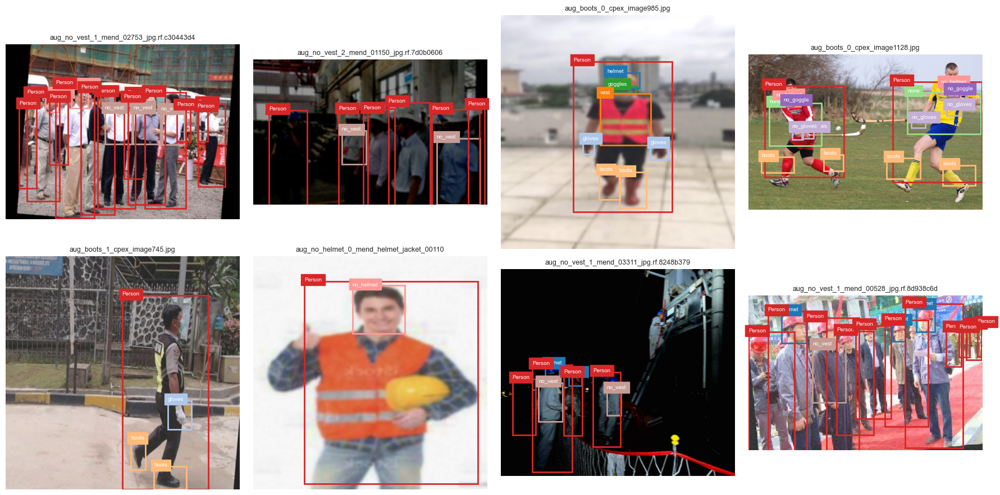

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/augmented_examples.png


In [98]:
preview = list(aug_paths)
random.Random(SEED).shuffle(preview)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax in axes.flatten():
    ax.axis("off")
for ax, image_path in zip(axes.flatten(), preview[:8]):
    draw_boxes(ax, image_path, read_labels(label_path_for(image_path)), title=image_path.name[:40])
plt.tight_layout()
save_figure(fig, "augmented_examples")

### 9.5 Compare the training sets with val and test

The left chart shows the SAMS classes in the three training sets. The balanced set should be close to flat. The right chart shows val and test, which keep their natural, unbalanced counts on purpose: they should look like real site data, where missing gear is rarer than worn gear.

,train full,train curated,train balanced,val,test
class,,,,,
helmet,3265,3007,5129,704,1432
gloves,4730,3001,4155,470,163
vest,2330,2330,3392,460,178
boots,1217,1217,3000,316,313
goggles,1489,408,833,379,352
none,651,633,1425,81,65
Person,21241,11302,19058,4347,3943
no_helmet,1351,1351,3002,293,1107
no_goggle,1802,333,802,521,110


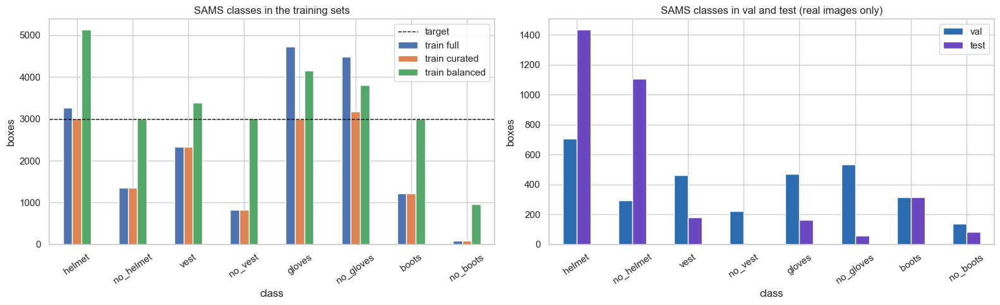

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/training_sets_class_counts.png


,full,curated,balanced,full %,curated %,balanced %
source,,,,,,
cpex,1117,1102,2091,16.7,28.1,33.2
mend,1803,1671,3056,27.0,42.6,48.5
wppe,3756,1148,1148,56.3,29.3,18.2
bg,0,0,0,0.0,0.0,0.0


In [99]:
split_counters = {
    "train full": class_counts_for_images(read_list(TRAIN_LISTS["full"])),
    "train curated": class_counts_for_images(read_list(TRAIN_LISTS["curated"])),
    "train balanced": class_counts_for_images(read_list(TRAIN_LISTS["balanced"])),
    "val": class_counts_for_images(VAL_IMAGES),
    "test": class_counts_for_images(read_list(TEST_LISTS["all"])),
}
all_classes_table = counts_table(split_counters)
save_table(all_classes_table, "training_sets_class_counts")

focus_table = all_classes_table.loc[FOCUS_CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
focus_table[["train full", "train curated", "train balanced"]].plot(kind="bar", ax=axes[0])
axes[0].axhline(TARGET_BOXES_PER_CLASS, color="black", linestyle="--", linewidth=1, label="target")
axes[0].set_title("SAMS classes in the training sets")
axes[0].set_ylabel("boxes")
axes[0].legend()
focus_table[["val", "test"]].plot(kind="bar", ax=axes[1], color=["#2b6cb0", "#6b46c1"])
axes[1].set_title("SAMS classes in val and test (real images only)")
axes[1].set_ylabel("boxes")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
save_figure(fig, "training_sets_class_counts")

share_rows = []
for source in SOURCES:
    full_images = int((pool_images["source"] == source).sum())
    curated_images = source_counts[source] + int((background_pick["source"] == source).sum())
    share_rows.append({
        "source": source,
        "full": full_images,
        "curated": curated_images,
        "balanced": curated_images + aug_sources[source],
    })
share_rows.append({"source": "bg", "full": 0, "curated": len(extra_background), "balanced": len(extra_background)})
share_table = pd.DataFrame(share_rows).set_index("source")
share_percent = (share_table / share_table.sum() * 100).round(1)
share_percent.columns = ["full %", "curated %", "balanced %"]
save_table(pd.concat([share_table, share_percent], axis=1), "training_sets_source_share")

### 9.6 Dataset files for Ultralytics

One YAML file per training set. They all point at the same val list, so every experiment is scored on exactly the same images.

In [100]:
def write_data_yaml(name, train_list, val_list, test_list):
    data = {
        "path": str(MERGED),
        "train": str(train_list),
        "val": str(val_list),
        "test": str(test_list),
        "names": CLASS_NAMES,
    }
    path = DATA_DIR / f"ppe_{name}.yaml"
    path.write_text(yaml.safe_dump(data, sort_keys=False))
    return path


DATA_YAMLS = {}
for name, train_list in TRAIN_LISTS.items():
    DATA_YAMLS[name] = write_data_yaml(name, train_list, VAL_LIST, TEST_LISTS["all"])

yaml_rows = []
for name, path in DATA_YAMLS.items():
    yaml_rows.append({
        "training set": name,
        "train images": len(read_list(TRAIN_LISTS[name])),
        "val images": len(VAL_IMAGES),
        "test images": len(read_list(TEST_LISTS["all"])),
        "yaml": str(path),
    })
save_table(pd.DataFrame(yaml_rows).set_index("training set"), "dataset_yaml_files")

,train images,val images,test images,yaml
training set,,,,
full,6676,1599,2062,/content/SAMS/datasets/vision/ppe/ppe_full.yaml
curated,3921,1599,2062,/content/SAMS/datasets/vision/ppe/ppe_curated....
balanced,6295,1599,2062,/content/SAMS/datasets/vision/ppe/ppe_balanced...


## 10. Training setup

### Transfer learning and fine-tuning

Every model starts from YOLOv8 weights pretrained on COCO. The pretrained network already knows edges, textures, and people. Fine-tuning adapts it to PPE.

YOLOv8 has three parts: the **backbone** (layers 0 to 9) turns the image into features, the **neck** mixes features at different scales, and the **head** predicts boxes and classes. Freezing a layer means its weights are not updated during training.

Two ways of fine-tuning are compared:

| Method | What happens |
|--------|--------------|
| single stage | All layers train from the first epoch |
| two stage | **Stage A:** the backbone is frozen (`freeze=10`) and only the neck and head train, for `STAGE_A_EPOCHS`. The new class layers settle without disturbing the pretrained features. **Stage B:** every layer is unfrozen and training continues from stage A's best weights with a 10 times lower learning rate and a cosine schedule, so the backbone is adjusted gently |

### Early stopping

After every epoch, Ultralytics scores the model on val. If the val fitness (0.1 times mAP50 plus 0.9 times mAP50-95) does not improve for the run's patience, training stops and the best epoch is kept. Every run uses `MAX_EPOCHS` and `PATIENCE`. The epoch count is only an upper limit.

### Hyperparameters

The optimizer is set to SGD on purpose. With the Ultralytics default `optimizer="auto"`, the learning rate below would be ignored and chosen automatically, which would make the experiments hard to compare.

In [101]:
BASE_HPARAMS = {
    "optimizer": "SGD",
    "lr0": 0.01,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,
    "warmup_epochs": 3.0,
    "cos_lr": False,
    "box": 7.5,
    "cls": 1.0,
    "dfl": 1.5,
    "hsv_h": 0.015,
    "hsv_s": 0.7,
    "hsv_v": 0.4,
    "degrees": 0.0,
    "translate": 0.1,
    "scale": 0.5,
    "fliplr": 0.5,
    "flipud": 0.0,
    "mosaic": 1.0,
    "close_mosaic": 5,
}

HPARAM_MEANING = {
    "optimizer": "Update rule. SGD with momentum is the YOLOv8 reference setting",
    "lr0": "Starting learning rate",
    "lrf": "Final learning rate as a fraction of lr0",
    "momentum": "How much of the last update carries into the next one",
    "weight_decay": "Penalty on large weights, reduces overfitting",
    "warmup_epochs": "Epochs where the learning rate ramps up from a small value",
    "cos_lr": "Cosine learning-rate decay instead of linear",
    "box": "Weight of the box position loss",
    "cls": "Weight of the class loss",
    "dfl": "Weight of the distribution focal loss for box edges",
    "hsv_h": "Random hue change during training",
    "hsv_s": "Random saturation change during training",
    "hsv_v": "Random brightness change during training",
    "degrees": "Random rotation during training. Kept at 0, the stored copies already rotate",
    "translate": "Random shift during training",
    "scale": "Random zoom during training",
    "fliplr": "Chance of a left-right flip during training",
    "flipud": "Chance of an upside-down flip. 0, since gear is never upside down on a worker",
    "mosaic": "Chance of combining four images into one",
    "close_mosaic": "Turn mosaic off for the last N epochs so the model sees whole images",
}

hparam_rows = []
for name, value in BASE_HPARAMS.items():
    hparam_rows.append({"hyperparameter": name, "value": value, "meaning": HPARAM_MEANING[name]})
save_table(pd.DataFrame(hparam_rows).set_index("hyperparameter"), "hyperparameters_base")


,value,meaning
hyperparameter,,
optimizer,SGD,Update rule. SGD with momentum is the YOLOv8 r...
lr0,0.01,Starting learning rate
lrf,0.01,Final learning rate as a fraction of lr0
momentum,0.937,How much of the last update carries into the n...
weight_decay,0.0005,"Penalty on large weights, reduces overfitting"
warmup_epochs,3.0,Epochs where the learning rate ramps up from a...
cos_lr,False,Cosine learning-rate decay instead of linear
box,7.5,Weight of the box position loss
cls,0.5,Weight of the class loss


### Training and scoring functions

- `train_once` runs one Ultralytics training job from scratch, after deleting any folder an earlier run left under the same name.
- `score_model` scores saved weights on a split.
- `per_class_frame` turns Ultralytics metrics into a per-class DataFrame.
- `run_experiment` trains one experiment (single or two stage), reads the training log, scores the best weights on val, and records one row in `LEDGER`.

Reported val metrics:

| Metric | Meaning |
|--------|---------|
| precision | Share of predicted boxes that match a label |
| recall | Share of labelled boxes that are found |
| mAP50 | Mean average precision with a 50 percent box overlap needed |
| mAP50-95 | Mean of mAP from 50 to 95 percent overlap. Rewards tight boxes; used as the tie-break when choosing a winner |
| missing recall | Mean recall of no_helmet, no_vest, no_gloves, and no_boots. **Primary score for choosing the winner**, because a missed violation is the most costly error for SAMS |


In [102]:
LEDGER = []
EXPERIMENTS = {}


def free_memory():
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()


def read_training_log(run_dir):
    results_csv = Path(run_dir) / "results.csv"
    if not results_csv.is_file():
        return pd.DataFrame()
    log = pd.read_csv(results_csv)
    clean_columns = []
    for column in log.columns:
        clean_columns.append(column.strip())
    log.columns = clean_columns
    return log


def train_once(run_name, data_yaml, weights, imgsz, epochs, freeze, hparams, seed, patience):
    shutil.rmtree(MODELS_DIR / run_name, ignore_errors=True)
    model = YOLO(weights)
    args = dict(hparams)
    args["data"] = str(data_yaml)
    args["epochs"] = epochs
    args["patience"] = patience
    args["imgsz"] = imgsz
    args["batch"] = BATCH
    args["device"] = YOLO_DEVICE
    args["project"] = str(MODELS_DIR)
    args["name"] = run_name
    args["exist_ok"] = True
    args["seed"] = seed
    args["deterministic"] = False
    args["workers"] = 8
    args["cache"] = "disk"
    args["plots"] = True
    args["freeze"] = freeze
    started = time.time()
    model.train(**args)
    elapsed = time.time() - started
    run_dir = Path(model.trainer.save_dir)
    best = run_dir / "weights" / "best.pt"
    del model
    free_memory()
    return run_dir, best, elapsed


def score_model(weights_path, data_yaml, imgsz, split="val", plots=False, name=None):
    model = YOLO(str(weights_path))
    kwargs = {
        "data": str(data_yaml),
        "split": split,
        "imgsz": imgsz,
        "batch": 16,
        "device": YOLO_DEVICE,
        "plots": plots,
        "verbose": False,
    }
    if name is not None:
        kwargs["project"] = str(RESULTS_DIR)
        kwargs["name"] = name
        kwargs["exist_ok"] = True
    metrics = model.val(**kwargs)
    del model
    free_memory()
    return metrics


def per_class_frame(metrics):
    box = metrics.box
    rows = []
    for position, class_id in enumerate(box.ap_class_index):
        rows.append({
            "class": metrics.names[int(class_id)],
            "precision": float(box.p[position]),
            "recall": float(box.r[position]),
            "mAP50": float(box.ap50[position]),
            "mAP50-95": float(box.ap[position]),
        })
    return pd.DataFrame(rows).set_index("class")


def mean_missing_recall(per_class):
    present = []
    for class_name in MISSING_CLASSES:
        if class_name in per_class.index:
            present.append(class_name)
    if not present:
        return float("nan")
    return float(per_class.loc[present, "recall"].mean())


def best_epoch_of(log):
    if log.empty or "metrics/mAP50-95(B)" not in log.columns:
        return None
    fitness = 0.1 * log["metrics/mAP50(B)"] + 0.9 * log["metrics/mAP50-95(B)"]
    return int(log.loc[fitness.idxmax(), "epoch"])


def run_experiment(exp_id, change, data_yaml, weights="yolov8n.pt", imgsz=IMGSZ_BASE,
                   two_stage=False, hparams=None, seed=SEED, group="main",
                   epochs=MAX_EPOCHS, patience=PATIENCE):
    if hparams is None:
        hparams = BASE_HPARAMS

    recipe = {
        "data_yaml": Path(data_yaml),
        "weights": weights,
        "imgsz": imgsz,
        "two_stage": two_stage,
        "hparams": dict(hparams),
    }

    logs = []
    if two_stage:
        run_dir_a, best_a, time_a = train_once(
            f"{exp_id}_stageA_frozen", data_yaml, weights, imgsz,
            STAGE_A_EPOCHS, FREEZE_LAYERS, hparams, seed, patience,
        )
        stage_b_hparams = dict(hparams)
        stage_b_hparams["lr0"] = hparams["lr0"] / 10
        stage_b_hparams["warmup_epochs"] = 1.0
        stage_b_hparams["cos_lr"] = True
        run_dir, best, time_b = train_once(
            f"{exp_id}_stageB_unfrozen", data_yaml, str(best_a), imgsz,
            epochs, None, stage_b_hparams, seed, patience,
        )
        elapsed = time_a + time_b
        log_a = read_training_log(run_dir_a)
        log_a["stage"] = "A frozen"
        logs.append(log_a)
        log_b = read_training_log(run_dir)
        log_b["stage"] = "B unfrozen"
        logs.append(log_b)
        epochs_limit = epochs
    else:
        run_dir, best, elapsed = train_once(exp_id, data_yaml, weights, imgsz, epochs, None, hparams, seed, patience)
        log = read_training_log(run_dir)
        log["stage"] = "single"
        logs.append(log)
        epochs_limit = epochs

    full_log = pd.concat(logs, ignore_index=True)
    full_log["epoch overall"] = np.arange(1, len(full_log) + 1)
    last_log = logs[-1]

    metrics = score_model(best, data_yaml, imgsz)
    per_class = per_class_frame(metrics)
    train_list = yaml.safe_load(Path(data_yaml).read_text())["train"]

    summary = {
        "experiment_id": exp_id,
        "group": group,
        "change": change,
        "weights_in": weights,
        "train images": len(read_list(train_list)),
        "imgsz": imgsz,
        "two_stage": two_stage,
        "seed": seed,
        "epochs_limit": epochs_limit,
        "epochs_run": len(last_log),
        "best_epoch": best_epoch_of(last_log),
        "stopped_early": len(last_log) < epochs_limit,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "map50": float(metrics.box.map50),
        "map50_95": float(metrics.box.map),
        "missing_recall": mean_missing_recall(per_class),
        "minutes": round(elapsed / 60, 1),
        "best_pt": str(best),
    }
    LEDGER.append(summary)
    EXPERIMENTS[exp_id] = {"summary": summary, "per_class": per_class, "log": full_log, "recipe": recipe}

    with (Path(run_dir) / "experiment_summary.json").open("w") as handle:
        json.dump(summary, handle, indent=2)

    shown = ["experiment_id", "change", "epochs_run", "best_epoch", "stopped_early",
             "precision", "recall", "map50", "map50_95", "missing_recall", "minutes"]
    display(pd.DataFrame([summary])[shown].set_index("experiment_id").round(3))
    return summary

## 11. Experiments

Each experiment changes one thing compared with the one before it:

| Id | Change | Question it answers |
|----|--------|---------------------|
| E1 | Full training set, YOLOv8n, 640 | Baseline |
| E2 | Curated set | Does choosing real images per class beat using everything? |
| E3 | Balanced set | Do the augmented copies help the rare classes? |
| E4 | Balanced set at 960 pixels | Does a larger image help small gloves and shoes? |
| E5 | Two-stage fine-tuning at the better size | Does freezing the backbone first help? |
| E5h | AdamW optimizer with a lower learning rate | Does a different optimizer beat the SGD defaults? |
| E6 | Teacher-filled labels for classes a source does not annotate | Does it help to stop teaching unlabelled gear as background? |
| E7 | YOLOv8s with the best recipe so far | Does a larger model help? |

All experiments use early stopping with the same `MAX_EPOCHS` and `PATIENCE`, and the same val set. The first version listed E5h and E6 in this table but never ran them, so every model it produced was YOLOv8n.

### E1. Baseline: every training image

In [103]:
run_experiment(
    "ppe_e1_full",
    "Baseline: every training image, no selection, no copies",
    data_yaml=DATA_YAMLS["full"],
)

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/ppe/ppe_full.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yo

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,missing_recall,minutes
experiment_id,,,,,,,,,,
ppe_e1_full,"Baseline: every training image, no selection, ...",24,21,True,0.67,0.56,0.556,0.319,0.404,15.6


{'experiment_id': 'ppe_e1_full',
 'group': 'main',
 'change': 'Baseline: every training image, no selection, no copies',
 'weights_in': 'yolov8n.pt',
 'train images': 6676,
 'imgsz': 640,
 'two_stage': False,
 'seed': 42,
 'epochs_limit': 40,
 'epochs_run': 24,
 'best_epoch': 21,
 'stopped_early': True,
 'precision': 0.6698170868574382,
 'recall': 0.5595123527275585,
 'map50': 0.5559170167887628,
 'map50_95': 0.31938814331752224,
 'missing_recall': 0.4044708155125216,
 'minutes': 15.6,
 'best_pt': '/content/drive/MyDrive/SAMS/models/vision/ppe/ppe_e1_full/weights/best.pt'}

### E2. Curated real images

In [104]:
run_experiment(
    "ppe_e2_curated",
    "Real images chosen per class, plus background images",
    data_yaml=DATA_YAMLS["curated"],
)

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/ppe/ppe_curated.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,missing_recall,minutes
experiment_id,,,,,,,,,,
ppe_e2_curated,"Real images chosen per class, plus background ...",5,2,True,0.512,0.354,0.31,0.169,0.295,2.4


{'experiment_id': 'ppe_e2_curated',
 'group': 'main',
 'change': 'Real images chosen per class, plus background images',
 'weights_in': 'yolov8n.pt',
 'train images': 3921,
 'imgsz': 640,
 'two_stage': False,
 'seed': 42,
 'epochs_limit': 40,
 'epochs_run': 5,
 'best_epoch': 2,
 'stopped_early': True,
 'precision': 0.5123497998775303,
 'recall': 0.35442140165248365,
 'map50': 0.3102263116888779,
 'map50_95': 0.1689679591366516,
 'missing_recall': 0.2950979574287396,
 'minutes': 2.4,
 'best_pt': '/content/drive/MyDrive/SAMS/models/vision/ppe/ppe_e2_curated/weights/best.pt'}

### E3. Curated plus augmented copies

In [105]:
run_experiment(
    "ppe_e3_balanced",
    "Curated set plus augmented copies for classes still short",
    data_yaml=DATA_YAMLS["balanced"],
)

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/ppe/ppe_balanced.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, mode

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,missing_recall,minutes
experiment_id,,,,,,,,,,
ppe_e3_balanced,Curated set plus augmented copies for classes ...,4,2,True,0.545,0.345,0.309,0.177,0.25,3.6


{'experiment_id': 'ppe_e3_balanced',
 'group': 'main',
 'change': 'Curated set plus augmented copies for classes still short',
 'weights_in': 'yolov8n.pt',
 'train images': 6295,
 'imgsz': 640,
 'two_stage': False,
 'seed': 42,
 'epochs_limit': 40,
 'epochs_run': 4,
 'best_epoch': 2,
 'stopped_early': True,
 'precision': 0.545096758464527,
 'recall': 0.3451759895268909,
 'map50': 0.3085240860380601,
 'map50_95': 0.1774292776698541,
 'missing_recall': 0.2502126616381943,
 'minutes': 3.6,
 'best_pt': '/content/drive/MyDrive/SAMS/models/vision/ppe/ppe_e3_balanced/weights/best.pt'}

### E4. Larger image size

Gloves and shoes are often small (section 7.4). Training at 960 pixels gives them more pixels. It costs more memory and time.

In [106]:
run_experiment(
    "ppe_e4_imgsz_large",
    f"Balanced set at {IMGSZ_LARGE} pixels",
    data_yaml=DATA_YAMLS["balanced"],
    imgsz=IMGSZ_LARGE,
)

e3_score = EXPERIMENTS["ppe_e3_balanced"]["summary"]["map50_95"]
e4_score = EXPERIMENTS["ppe_e4_imgsz_large"]["summary"]["map50_95"]
if e4_score > e3_score:
    BEST_IMGSZ = IMGSZ_LARGE
    BEST_SINGLE_ID = "ppe_e4_imgsz_large"
else:
    BEST_IMGSZ = IMGSZ_BASE
    BEST_SINGLE_ID = "ppe_e3_balanced"

display(pd.DataFrame([
    {"image size": IMGSZ_BASE, "val mAP50-95": e3_score},
    {"image size": IMGSZ_LARGE, "val mAP50-95": e4_score},
]).set_index("image size").round(4))
print("Image size used from here on:", BEST_IMGSZ)

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/ppe/ppe_balanced.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, mode

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,missing_recall,minutes
experiment_id,,,,,,,,,,
ppe_e4_imgsz_large,Balanced set at 960 pixels,4,1,True,0.527,0.369,0.328,0.187,0.354,5.1


,val mAP50-95
image size,
640,0.1774
960,0.1875


Image size used from here on: 960


### E5. Two-stage fine-tuning: freeze, then unfreeze

Stage A trains with the backbone frozen. Stage B unfreezes every layer and continues at a lower learning rate. Both stages use early stopping.

In [107]:
run_experiment(
    "ppe_e5_two_stage",
    f"Frozen backbone for {STAGE_A_EPOCHS} epochs, then all layers at lr0 / 10, {BEST_IMGSZ} pixels",
    data_yaml=DATA_YAMLS["balanced"],
    imgsz=BEST_IMGSZ,
    two_stage=True,
)

single_score = EXPERIMENTS[BEST_SINGLE_ID]["summary"]["map50_95"]
two_stage_score = EXPERIMENTS["ppe_e5_two_stage"]["summary"]["map50_95"]
USE_TWO_STAGE = two_stage_score > single_score

display(pd.DataFrame([
    {"fine-tuning": "single stage", "experiment": BEST_SINGLE_ID, "val mAP50-95": single_score},
    {"fine-tuning": "two stage", "experiment": "ppe_e5_two_stage", "val mAP50-95": two_stage_score},
]).set_index("fine-tuning").round(4))

FINAL_RECIPE = {
    "data_yaml": DATA_YAMLS["balanced"],
    "imgsz": BEST_IMGSZ,
    "two_stage": USE_TWO_STAGE,
    "hparams": dict(BASE_HPARAMS),
}
print("Two-stage fine-tuning used from here on:", USE_TWO_STAGE)

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/ppe/ppe_balanced.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,missing_recall,minutes
experiment_id,,,,,,,,,,
ppe_e5_two_stage,"Frozen backbone for 10 epochs, then all layers...",11,8,True,0.664,0.452,0.425,0.256,0.432,21.1


,experiment,val mAP50-95
fine-tuning,,
single stage,ppe_e4_imgsz_large,0.1875
two stage,ppe_e5_two_stage,0.2560


Two-stage fine-tuning used from here on: True


### E5h. Optimizer: AdamW with a lower learning rate

AdamW adapts the step size of every weight and often converges faster on fine-tuning tasks. It needs a lower starting learning rate than SGD.

In [108]:
if USE_TWO_STAGE:
    RECIPE_SO_FAR_ID = "ppe_e5_two_stage"
else:
    RECIPE_SO_FAR_ID = BEST_SINGLE_ID

ADAMW_HPARAMS = dict(FINAL_RECIPE["hparams"])
ADAMW_HPARAMS["optimizer"] = "AdamW"
ADAMW_HPARAMS["lr0"] = 0.001
ADAMW_HPARAMS["momentum"] = 0.9

run_experiment(
    "ppe_e5h_adamw",
    "AdamW lr0=0.001 with the recipe so far",
    data_yaml=FINAL_RECIPE["data_yaml"],
    imgsz=FINAL_RECIPE["imgsz"],
    two_stage=FINAL_RECIPE["two_stage"],
    hparams=ADAMW_HPARAMS,
)

sgd_score = EXPERIMENTS[RECIPE_SO_FAR_ID]["summary"]["map50_95"]
adamw_score = EXPERIMENTS["ppe_e5h_adamw"]["summary"]["map50_95"]
save_table(pd.DataFrame([
    {"optimizer": "SGD", "experiment": RECIPE_SO_FAR_ID, "val mAP50-95": sgd_score},
    {"optimizer": "AdamW", "experiment": "ppe_e5h_adamw", "val mAP50-95": adamw_score},
]).set_index("optimizer").round(4), "experiment_optimizer_choice")

if adamw_score > sgd_score:
    FINAL_RECIPE["hparams"] = ADAMW_HPARAMS
    RECIPE_SO_FAR_ID = "ppe_e5h_adamw"
print("Optimizer used from here on:", FINAL_RECIPE["hparams"]["optimizer"])

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/ppe/ppe_balanced.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,missing_recall,minutes
experiment_id,,,,,,,,,,
ppe_e5h_adamw,AdamW lr0=0.001 with the recipe so far,6,3,True,0.563,0.459,0.416,0.245,0.425,15.5


,experiment,val mAP50-95
optimizer,,
SGD,ppe_e5_two_stage,0.2560
AdamW,ppe_e5h_adamw,0.2455


Optimizer used from here on: SGD


### E6. Teacher-filled labels for classes a source does not annotate

Each source labels only some of the gear. Mendeley labels helmets and vests but not the gloves and shoes its workers wear; the Worker PPE set labels gloves, shoes and helmets but no vests; Construction-PPE has no `no_vest` class. Every unlabelled glove, shoe or vest in those images is taught as background, which pushes the model away from exactly the items SAMS checks. `UNLABELLED_BY_SOURCE` lists the gaps.

The best model so far acts as a teacher. It predicts on every training image, and a box of a class that the image's source does not annotate is added as a label when its confidence is at least `TEACHER_CONF` and it does not overlap an existing gear label by `TEACHER_IOU` or more. Labels the source does annotate are never changed. Only training images are touched; val and test keep their published labels.

Two cautions when reading the result:

- Val keeps the same gaps, so a model that now finds those gloves, shoes and vests is marked wrong for them on val. E6 is therefore kept unless it loses by more than `WINNER_TOLERANCE`.
- The per-class table after the run compares E6 with the recipe so far on the classes each source does label, which is the fair comparison.

,,boxes added
source,class,
cpex,no_vest,2
mend,no_gloves,1


value
source item                            
cpex   images checked              2091
       images with a teacher box      2
mend   images checked              3056
       images with a teacher box      1
wppe   images checked              1148
       images with a teacher box      0

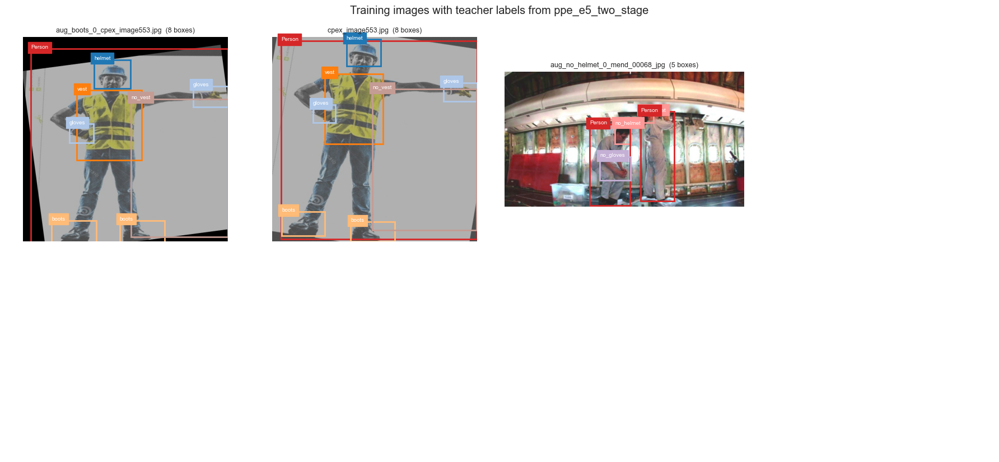

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/teacher_label_examples.png


In [109]:
SOURCE_PATTERN = re.compile(r"(?:^|_)(" + "|".join(sorted(UNLABELLED_BY_SOURCE)) + r")_")


def source_of(image_path):
    """The source an image (or an augmented copy of it) came from, from its staged file name."""
    match = SOURCE_PATTERN.search(Path(image_path).name)
    if match is None:
        return "bg"
    return match.group(1)


def overlap(box_a, box_b):
    """IoU of two [xc, yc, w, h] boxes in normalised coordinates."""
    left = max(box_a[0] - box_a[2] / 2, box_b[0] - box_b[2] / 2)
    right = min(box_a[0] + box_a[2] / 2, box_b[0] + box_b[2] / 2)
    top = max(box_a[1] - box_a[3] / 2, box_b[1] - box_b[3] / 2)
    bottom = min(box_a[1] + box_a[3] / 2, box_b[1] + box_b[3] / 2)
    shared = max(0.0, right - left) * max(0.0, bottom - top)
    union = box_a[2] * box_a[3] + box_b[2] * box_b[3] - shared
    return shared / union if union > 0 else 0.0


def link_or_copy(source_path, target_path):
    try:
        os.link(source_path, target_path)
    except OSError:
        shutil.copy2(source_path, target_path)


TEACHER_ID = RECIPE_SO_FAR_ID
TEACHER_WEIGHTS = Path(EXPERIMENTS[TEACHER_ID]["summary"]["best_pt"])
PSEUDO_IMAGE_DIR = MERGED / "images" / "pseudo"
PSEUDO_LABEL_DIR = MERGED / "labels" / "pseudo"
for folder in [PSEUDO_IMAGE_DIR, PSEUDO_LABEL_DIR]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True)

base_train = read_list(yaml.safe_load(Path(FINAL_RECIPE["data_yaml"]).read_text())["train"])
to_fill = [path for path in base_train if UNLABELLED_BY_SOURCE.get(source_of(path))]
filled_path = {}
with_teacher_boxes = []
teacher_boxes = Counter()
teacher_images = Counter()
teacher = YOLO(str(TEACHER_WEIGHTS))
for start in range(0, len(to_fill), 32):
    chunk = to_fill[start:start + 32]
    results = teacher.predict([str(path) for path in chunk], conf=TEACHER_CONF, imgsz=FINAL_RECIPE["imgsz"],
                              device=YOLO_DEVICE, verbose=False)
    for path, result in zip(chunk, results):
        source = source_of(path)
        wanted = {NAME_TO_ID[name] for name in UNLABELLED_BY_SOURCE[source]}
        rows = read_labels(label_path_for(path))
        gear = [row for row in rows if row[0] != PERSON_ID]
        added = []
        for class_id, box in zip(result.boxes.cls.cpu().numpy(), result.boxes.xywhn.cpu().numpy()):
            class_id = int(class_id)
            box = [float(value) for value in box]
            if class_id not in wanted:
                continue
            if any(overlap(box, row[1:5]) >= TEACHER_IOU for row in gear + added):
                continue
            added.append([class_id] + box)
            teacher_boxes[(source, CLASS_NAMES[class_id])] += 1
        target = PSEUDO_IMAGE_DIR / path.name
        link_or_copy(path, target)
        write_labels(label_path_for(target), rows + added)
        filled_path[path] = target
        if added:
            with_teacher_boxes.append(target)
        teacher_images[(source, "images with a teacher box")] += int(bool(added))
        teacher_images[(source, "images checked")] += 1
del teacher
free_memory()

pseudo_paths = [filled_path.get(path, path) for path in base_train]
TRAIN_LISTS["pseudo"] = write_list("train_pseudo", pseudo_paths)
DATA_YAMLS["pseudo"] = write_data_yaml("pseudo", TRAIN_LISTS["pseudo"], VAL_LIST, TEST_LISTS["all"])

teacher_rows = [{"source": key[0], "class": key[1], "boxes added": value} for key, value in sorted(teacher_boxes.items())]
if teacher_rows:
    save_table(pd.DataFrame(teacher_rows).set_index(["source", "class"]), "teacher_boxes_added")
save_table(pd.DataFrame([{"source": key[0], "item": key[1], "value": value} for key, value in sorted(teacher_images.items())]).set_index(["source", "item"]), "teacher_images")

if with_teacher_boxes:
    preview_images(with_teacher_boxes, f"Training images with teacher labels from {TEACHER_ID}", "teacher_label_examples")

In [110]:
run_experiment(
    "ppe_e6_teacher_labels",
    f"Teacher-filled labels from {TEACHER_ID} for classes a source does not annotate",
    data_yaml=DATA_YAMLS["pseudo"],
    imgsz=FINAL_RECIPE["imgsz"],
    two_stage=FINAL_RECIPE["two_stage"],
    hparams=FINAL_RECIPE["hparams"],
)

before = EXPERIMENTS[RECIPE_SO_FAR_ID]["per_class"]
after = EXPERIMENTS["ppe_e6_teacher_labels"]["per_class"]
fair_rows = []
for class_name in FOCUS_CLASSES:
    fair_rows.append({
        "class": class_name,
        "sources that label it": ", ".join(s for s in SOURCES if class_name not in UNLABELLED_BY_SOURCE.get(s, [])),
        f"{RECIPE_SO_FAR_ID} mAP50-95": before["mAP50-95"].get(class_name, np.nan),
        "ppe_e6_teacher_labels mAP50-95": after["mAP50-95"].get(class_name, np.nan),
        f"{RECIPE_SO_FAR_ID} recall": before["recall"].get(class_name, np.nan),
        "ppe_e6_teacher_labels recall": after["recall"].get(class_name, np.nan),
    })
save_table(pd.DataFrame(fair_rows).set_index("class").round(3), "experiment_teacher_labels_per_class")

so_far_score = EXPERIMENTS[RECIPE_SO_FAR_ID]["summary"]["map50_95"]
teacher_score = EXPERIMENTS["ppe_e6_teacher_labels"]["summary"]["map50_95"]
USE_TEACHER_LABELS = teacher_score >= so_far_score - WINNER_TOLERANCE
if USE_TEACHER_LABELS:
    FINAL_RECIPE["data_yaml"] = DATA_YAMLS["pseudo"]
    RECIPE_SO_FAR_ID = "ppe_e6_teacher_labels"
print("Teacher-filled labels used from here on:", USE_TEACHER_LABELS)

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/ppe/ppe_pseudo.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yo

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,missing_recall,minutes
experiment_id,,,,,,,,,,
ppe_e6_teacher_labels,Teacher-filled labels from ppe_e5_two_stage fo...,11,8,True,0.655,0.458,0.418,0.253,0.443,25.4


,sources that label it,ppe_e5_two_stage mAP50-95,ppe_e6_teacher_labels mAP50-95,ppe_e5_two_stage recall,ppe_e6_teacher_labels recall
class,,,,,
helmet,"cpex, mend, wppe",0.357,0.351,0.626,0.648
no_helmet,"cpex, mend, wppe",0.328,0.301,0.532,0.551
vest,"cpex, mend",0.455,0.458,0.711,0.722
no_vest,mend,0.268,0.253,0.624,0.647
gloves,"cpex, wppe",0.396,0.398,0.815,0.789
no_gloves,"cpex, wppe",0.124,0.138,0.570,0.573
boots,"cpex, wppe",0.243,0.223,0.310,0.329
no_boots,"cpex, wppe",0.000,0.000,0.000,0.000


Teacher-filled labels used from here on: True


### E7. YOLOv8s with the best recipe so far

YOLOv8s has about three times the parameters of YOLOv8n. Small gear such as gloves and shoes is where the extra capacity should show.

In [111]:
run_experiment(
    "ppe_e7_yolov8s",
    "YOLOv8s with the best data, image size, fine-tuning, and optimizer so far",
    data_yaml=FINAL_RECIPE["data_yaml"],
    weights="yolov8s.pt",
    imgsz=FINAL_RECIPE["imgsz"],
    two_stage=FINAL_RECIPE["two_stage"],
    hparams=FINAL_RECIPE["hparams"],
)

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SAMS/datasets/vision/ppe/ppe_pseudo.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yo

,change,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,missing_recall,minutes
experiment_id,,,,,,,,,,
ppe_e7_yolov8s,"YOLOv8s with the best data, image size, fine-t...",5,2,True,0.503,0.507,0.425,0.261,0.512,24.1


{'experiment_id': 'ppe_e7_yolov8s',
 'group': 'main',
 'change': 'YOLOv8s with the best data, image size, fine-tuning, and optimizer so far',
 'weights_in': 'yolov8s.pt',
 'train images': 6295,
 'imgsz': 960,
 'two_stage': True,
 'seed': 42,
 'epochs_limit': 40,
 'epochs_run': 5,
 'best_epoch': 2,
 'stopped_early': True,
 'precision': 0.5032995333834345,
 'recall': 0.5066684372637796,
 'map50': 0.4245725105889597,
 'map50_95': 0.26104025047943547,
 'missing_recall': 0.5116390187875317,
 'minutes': 24.1,
 'best_pt': '/content/drive/MyDrive/SAMS/models/vision/ppe/ppe_e7_yolov8s_stageB_unfrozen/weights/best.pt'}

## 12. Compare the experiments and choose the recipe

The winner is the experiment with the highest val **missing-gear recall**. If another experiment is within `WINNER_TOLERANCE` of that recall, the one with the higher val mAP50-95 wins instead. Missed violations matter most for SAMS; mAP only breaks near-ties. The winning run is the model evaluated and promoted from here on.


,group,change,weights_in,train images,imgsz,two_stage,epochs_run,best_epoch,stopped_early,precision,recall,map50,map50_95,missing_recall,minutes
experiment_id,,,,,,,,,,,,,,,
ppe_e1_full,main,"Baseline: every training image, no selection, ...",yolov8n.pt,6676,640,False,24,21,True,0.6698,0.5595,0.5559,0.3194,0.4045,15.6
ppe_e2_curated,main,"Real images chosen per class, plus background ...",yolov8n.pt,3921,640,False,5,2,True,0.5123,0.3544,0.3102,0.1690,0.2951,2.4
ppe_e3_balanced,main,Curated set plus augmented copies for classes ...,yolov8n.pt,6295,640,False,4,2,True,0.5451,0.3452,0.3085,0.1774,0.2502,3.6
ppe_e4_imgsz_large,main,Balanced set at 960 pixels,yolov8n.pt,6295,960,False,4,1,True,0.5273,0.3692,0.3277,0.1875,0.3538,5.1
ppe_e5_two_stage,main,"Frozen backbone for 10 epochs, then all layers...",yolov8n.pt,6295,960,True,11,8,True,0.6642,0.4523,0.4252,0.2560,0.4317,21.1
ppe_e5h_adamw,main,AdamW lr0=0.001 with the recipe so far,yolov8n.pt,6295,960,True,6,3,True,0.5628,0.4590,0.4163,0.2455,0.4248,15.5
ppe_e6_teacher_labels,main,Teacher-filled labels from ppe_e5_two_stage fo...,yolov8n.pt,6295,960,True,11,8,True,0.6548,0.4585,0.4179,0.2528,0.4429,25.4
ppe_e7_yolov8s,main,"YOLOv8s with the best data, image size, fine-t...",yolov8s.pt,6295,960,True,5,2,True,0.5033,0.5067,0.4246,0.2610,0.5116,24.1


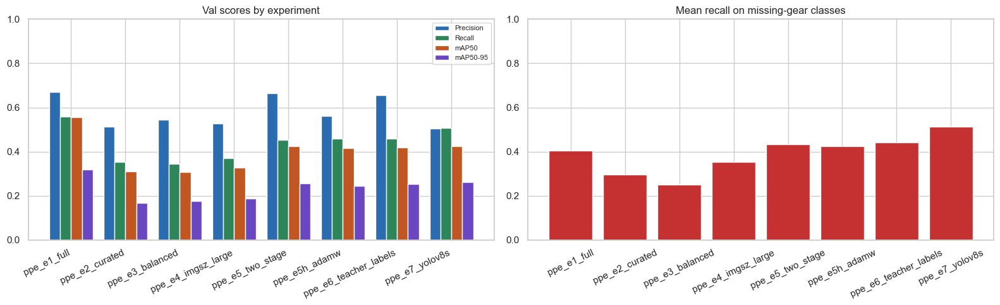

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/experiment_comparison.png


In [112]:
ledger_frame = pd.DataFrame(LEDGER)
ledger_columns = ["experiment_id", "group", "change", "weights_in", "train images", "imgsz", "two_stage",
                  "epochs_run", "best_epoch", "stopped_early", "precision", "recall", "map50", "map50_95",
                  "missing_recall", "minutes"]
ledger_view = ledger_frame[ledger_columns].set_index("experiment_id").round(4)
save_table(ledger_view, "experiment_ledger")

main_ledger = ledger_frame[ledger_frame["group"] == "main"].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
positions = np.arange(len(main_ledger))
bar_width = 0.2
series = [
    ("precision", "Precision", "#2b6cb0"),
    ("recall", "Recall", "#2f855a"),
    ("map50", "mAP50", "#c05621"),
    ("map50_95", "mAP50-95", "#6b46c1"),
]
for offset, (column, label, color) in enumerate(series):
    axes[0].bar(positions + (offset - 1.5) * bar_width, main_ledger[column], bar_width, label=label, color=color)
axes[0].set_xticks(positions)
axes[0].set_xticklabels(main_ledger["experiment_id"], rotation=25, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_title("Val scores by experiment")
axes[0].legend(fontsize=8)

axes[1].bar(main_ledger["experiment_id"], main_ledger["missing_recall"], color="#c53030")
axes[1].set_ylim(0, 1)
axes[1].set_title("Mean recall on missing-gear classes")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
save_figure(fig, "experiment_comparison")

### Training curves

Each line is the val mAP50-95 after every epoch, and the val box loss next to it. A line that flattens long before it ends shows where early stopping stepped in. For two-stage runs, stage A and stage B are joined, so the jump where the backbone is unfrozen is visible.

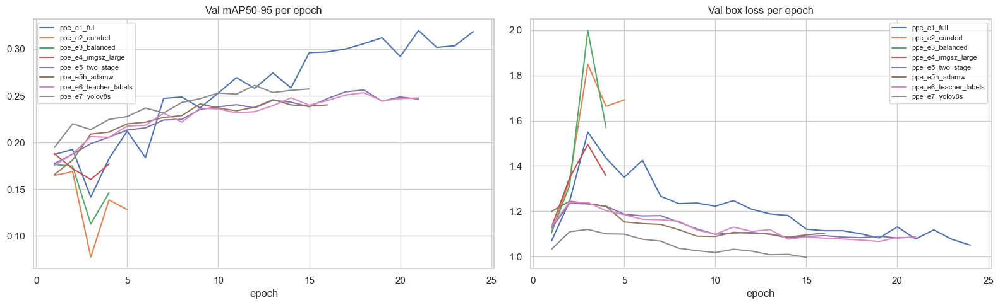

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/training_curves.png


In [113]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for exp_id, experiment in EXPERIMENTS.items():
    if experiment["summary"]["group"] != "main":
        continue
    log = experiment["log"]
    if "metrics/mAP50-95(B)" in log.columns:
        axes[0].plot(log["epoch overall"], log["metrics/mAP50-95(B)"], label=exp_id)
    if "val/box_loss" in log.columns:
        axes[1].plot(log["epoch overall"], log["val/box_loss"], label=exp_id)
axes[0].set_title("Val mAP50-95 per epoch")
axes[0].set_xlabel("epoch")
axes[1].set_title("Val box loss per epoch")
axes[1].set_xlabel("epoch")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
save_figure(fig, "training_curves")

### What each data step did, per SAMS class

This compares E1 (everything), E2 (curated), and E3 (balanced) class by class. The rare classes are where curation and balancing should show their effect.

,ppe_e1_full,ppe_e2_curated,ppe_e3_balanced
class,,,
helmet,0.362,0.260,0.256
no_helmet,0.278,0.120,0.129
vest,0.471,0.334,0.342
no_vest,0.286,0.147,0.132
gloves,0.414,0.304,0.267
no_gloves,0.267,0.074,0.066
boots,0.215,0.121,0.168
no_boots,0.000,0.000,0.000


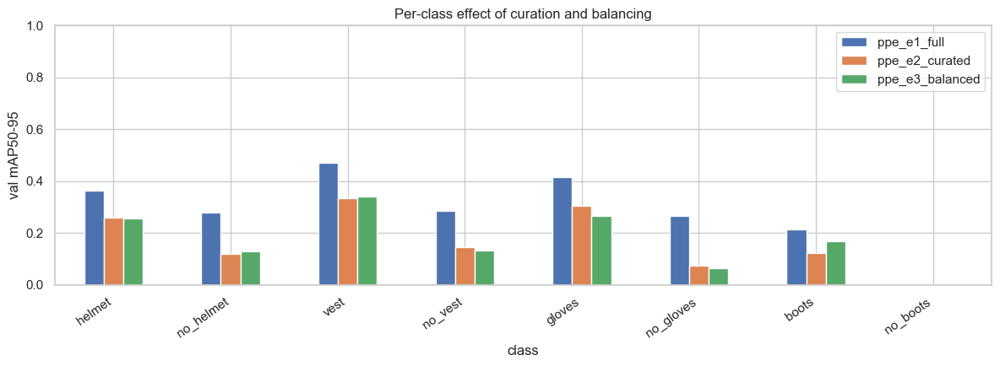

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/data_ablation_per_class.png


In [114]:
ablation = pd.DataFrame(index=FOCUS_CLASSES)
ablation.index.name = "class"
for exp_id in ["ppe_e1_full", "ppe_e2_curated", "ppe_e3_balanced"]:
    per_class = EXPERIMENTS[exp_id]["per_class"]
    ablation[exp_id] = per_class["mAP50-95"].reindex(FOCUS_CLASSES)
save_table(ablation.round(3), "data_ablation_per_class")

fig, ax = plt.subplots(figsize=(12, 4.5))
ablation.plot(kind="bar", ax=ax)
ax.set_ylabel("val mAP50-95")
ax.set_ylim(0, 1)
ax.set_title("Per-class effect of curation and balancing")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
save_figure(fig, "data_ablation_per_class")

In [115]:
ranked = main_ledger.sort_values(["missing_recall", "map50_95"], ascending=False).reset_index(drop=True)
top_missing = float(ranked.loc[0, "missing_recall"])
close_runs = ranked[ranked["missing_recall"] >= top_missing - WINNER_TOLERANCE]
winner_row = close_runs.sort_values("map50_95", ascending=False).iloc[0]

WINNER_ID = winner_row["experiment_id"]
WINNER = EXPERIMENTS[WINNER_ID]
BEST_WEIGHTS = Path(WINNER["summary"]["best_pt"])
BEST_IMGSZ_FINAL = int(WINNER["recipe"]["imgsz"])
BEST_DATA = WINNER["recipe"]["data_yaml"]

display(pd.DataFrame([{
    "chosen experiment": WINNER_ID,
    "val mAP50-95": winner_row["map50_95"],
    "val mAP50": winner_row["map50"],
    "missing recall": winner_row["missing_recall"],
    "image size": BEST_IMGSZ_FINAL,
    "two stage": WINNER["recipe"]["two_stage"],
    "weights": str(BEST_WEIGHTS),
}]).set_index("chosen experiment").round(4))


,val mAP50-95,val mAP50,missing recall,image size,two stage,weights
chosen experiment,,,,,,
ppe_e1_full,0.3194,0.5559,0.4045,640,False,/content/drive/MyDrive/SAMS/models/vision/ppe/...


## 13. Evaluate the chosen model in detail

Everything in this section uses val only. Test is still untouched.

### 13.1 Per-class scores

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,135,380 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 78.8±54.6 MB/s, size: 213.1 KB)
val: Scanning /content/SAMS/datasets/vision/ppe/merged/labels/valcand.cache... 1599 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1599/1599 353.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 100/100 10.0it/s 10.0s
                   all       1599       8464       0.67       0.56      0.556      0.319
Speed: 0.6ms preprocess, 1.1ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/drive/MyDrive/SAMS/results/vision/ppe/ppe_best_val


,val boxes,precision,recall,mAP50,mAP50-95
class,,,,,
helmet,704,0.519,0.761,0.635,0.362
gloves,470,0.778,0.843,0.839,0.414
vest,460,0.726,0.757,0.753,0.471
boots,316,0.857,0.285,0.370,0.215
goggles,379,0.744,0.734,0.757,0.386
none,81,0.368,0.383,0.277,0.107
Person,4347,0.832,0.936,0.949,0.773
no_helmet,293,0.320,0.580,0.427,0.278
no_goggle,521,0.819,0.399,0.580,0.273


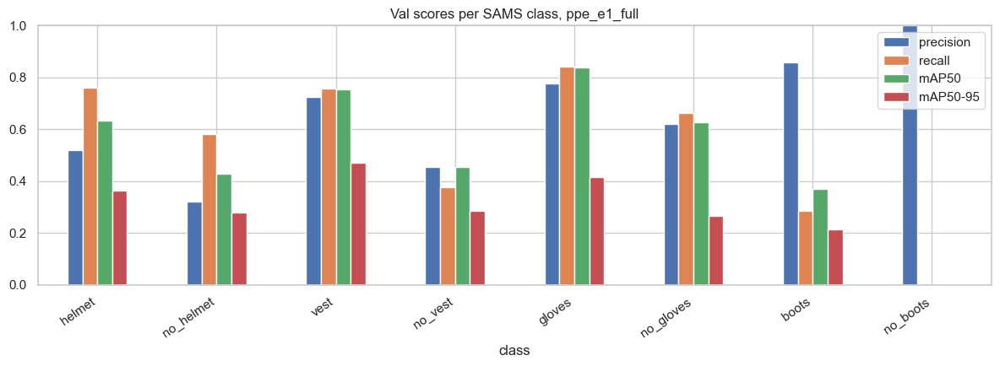

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/best_val_per_class.png


In [116]:
val_metrics = score_model(BEST_WEIGHTS, BEST_DATA, BEST_IMGSZ_FINAL, plots=True, name="ppe_best_val")
best_per_class = per_class_frame(val_metrics)

val_box_counts = class_counts_for_images(VAL_IMAGES)
count_column = []
for class_name in best_per_class.index:
    count_column.append(int(val_box_counts.get(NAME_TO_ID[class_name], 0)))
best_per_class.insert(0, "val boxes", count_column)
save_table(best_per_class.round(3), "best_val_per_class")

focus_view = best_per_class.reindex(FOCUS_CLASSES).dropna(subset=["mAP50-95"])
fig, ax = plt.subplots(figsize=(12, 4.5))
focus_view[["precision", "recall", "mAP50", "mAP50-95"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_title(f"Val scores per SAMS class, {WINNER_ID}")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
save_figure(fig, "best_val_per_class")

### 13.2 Confusion matrix

Columns are the true class, rows are the predicted class, and each column adds up to 1. The `background` row is labels the model missed, and the `background` column is predictions where there was no label.

The table under it pulls out the errors that matter most for SAMS: a worn item read as missing (a false alarm) and a missing item read as worn (a missed violation).

true,helmet,gloves,vest,boots,goggles,none,Person,no_helmet,no_goggle,no_gloves,no_boots,no_vest,background
predicted,,,,,,,,,,,,,
helmet,655,4,3,1,8,1,2,18,1,4,0,0,12980
gloves,1,445,0,3,0,6,0,0,0,5,0,0,9852
vest,2,0,398,0,0,3,9,0,0,0,0,10,6643
boots,1,2,0,219,0,1,0,0,0,3,44,0,8265
goggles,0,0,0,0,315,4,0,0,24,0,0,0,4838
none,0,2,8,1,0,57,1,0,0,14,0,3,12037
Person,14,1,40,4,0,0,4309,1,1,1,0,13,47966
no_helmet,13,0,0,0,9,2,5,248,20,1,0,0,11487
no_goggle,0,0,0,0,18,0,0,3,364,0,0,0,5629


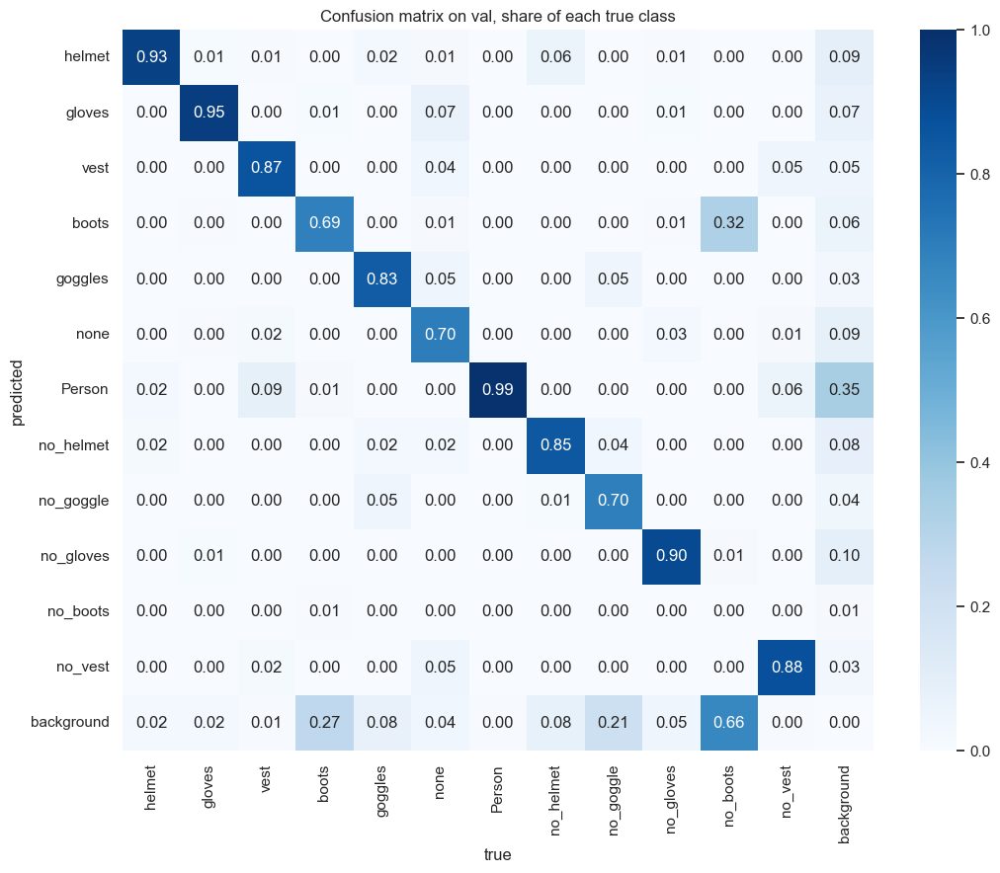

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/best_val_confusion_matrix.png


,true worn read as missing,true worn not found,true missing read as worn,true missing not found
item,,,,
helmet,0.018,0.024,0.061,0.078
vest,0.017,0.007,0.045,0.005
gloves,0.011,0.023,0.009,0.047
boots,0.006,0.272,0.321,0.664


In [117]:
matrix = val_metrics.confusion_matrix.matrix
matrix_labels = list(CLASS_NAMES.values()) + ["background"]
confusion = pd.DataFrame(matrix, index=matrix_labels, columns=matrix_labels)
confusion.index.name = "predicted"
confusion.columns.name = "true"
column_totals = confusion.sum(axis=0).replace(0, np.nan)
confusion_share = confusion / column_totals
save_table(confusion.astype(int), "best_val_confusion_counts")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(confusion_share, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Confusion matrix on val, share of each true class")
plt.tight_layout()
save_figure(fig, "best_val_confusion_matrix")

pair_rows = []
for worn_name, missing_name in WORN_MISSING_PAIRS:
    worn_total = confusion[worn_name].sum()
    missing_total = confusion[missing_name].sum()
    row = {"item": worn_name}
    if worn_total > 0:
        row["true worn read as missing"] = confusion.loc[missing_name, worn_name] / worn_total
        row["true worn not found"] = confusion.loc["background", worn_name] / worn_total
    if missing_total > 0:
        row["true missing read as worn"] = confusion.loc[worn_name, missing_name] / missing_total
        row["true missing not found"] = confusion.loc["background", missing_name] / missing_total
    pair_rows.append(row)
save_table(pd.DataFrame(pair_rows).set_index("item").round(3), "best_val_worn_missing_errors")

### 13.3 Precision-recall and F1 curves

Ultralytics records, for every class, precision, recall, and F1 at 1,000 confidence thresholds between 0 and 1. F1 is the balance of precision and recall. These curves are used in 13.4 to choose a threshold per class.

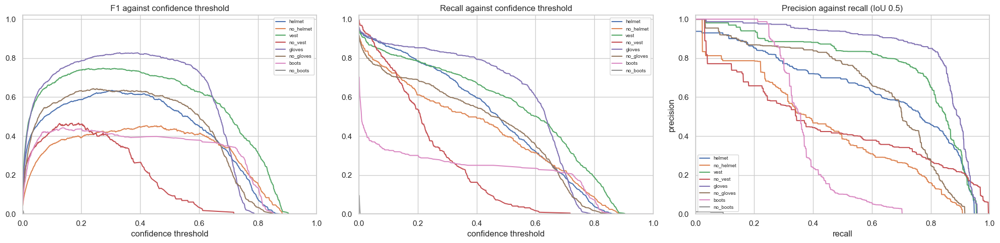

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/best_val_curves.png


In [118]:
box_metrics = val_metrics.box
THRESHOLD_GRID = np.asarray(box_metrics.px)
curve_rows = {}
for position, class_id in enumerate(box_metrics.ap_class_index):
    curve_rows[CLASS_NAMES[int(class_id)]] = position

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for class_name in FOCUS_CLASSES:
    if class_name not in curve_rows:
        continue
    position = curve_rows[class_name]
    axes[0].plot(THRESHOLD_GRID, box_metrics.f1_curve[position], label=class_name)
    axes[1].plot(THRESHOLD_GRID, box_metrics.r_curve[position], label=class_name)
    if hasattr(box_metrics, "prec_values") and len(box_metrics.prec_values) > position:
        recall_axis = np.linspace(0, 1, len(box_metrics.prec_values[position]))
        axes[2].plot(recall_axis, box_metrics.prec_values[position], label=class_name)
axes[0].set_title("F1 against confidence threshold")
axes[0].set_xlabel("confidence threshold")
axes[1].set_title("Recall against confidence threshold")
axes[1].set_xlabel("confidence threshold")
axes[2].set_title("Precision against recall (IoU 0.5)")
axes[2].set_xlabel("recall")
axes[2].set_ylabel("precision")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=7)
plt.tight_layout()
save_figure(fig, "best_val_curves")

### 13.4 One confidence threshold per class

A single threshold for every class is a poor fit: rare classes usually score lower confidences and need a lower threshold to be caught at all.

- Worn classes and other classes use the threshold with the highest F1.
- Missing-gear classes use the threshold with the highest F-beta, with beta `MISSING_F_BETA`. With beta 2, recall counts twice as much as precision, because missing a violation costs more than a false alarm. The first version used the highest threshold that still reached a fixed recall on val; when that recall could not be reached the thresholds fell to the 0.05 floor, and missing-gear recall dropped from 0.45 on val to 0.05 on test. F-beta takes the whole precision-recall curve into account and is far less sensitive to a few val images.
- Every threshold is kept between 0.05 and 0.80.

The thresholds are written to `metadata.json` as `class_conf`, which `ppe_inference.py` applies per class. `conf` is set to the median of the SAMS class thresholds, for code that reads only one value.

In [119]:
CLASS_CONF = {}
threshold_rows = []
beta_squared = MISSING_F_BETA ** 2
for class_name, position in curve_rows.items():
    f1_values = np.asarray(box_metrics.f1_curve[position])
    recall_values = np.asarray(box_metrics.r_curve[position])
    precision_values = np.asarray(box_metrics.p_curve[position])
    if class_name in MISSING_CLASSES:
        with np.errstate(divide="ignore", invalid="ignore"):
            scores = (1 + beta_squared) * precision_values * recall_values / (beta_squared * precision_values + recall_values)
        scores = np.nan_to_num(scores)
        rule = f"highest F{MISSING_F_BETA:g}"
    else:
        scores = f1_values
        rule = "highest F1"
    chosen_index = int(np.argmax(scores))
    threshold = float(np.clip(THRESHOLD_GRID[chosen_index], 0.05, 0.80))
    CLASS_CONF[class_name] = round(threshold, 3)
    threshold_rows.append({
        "class": class_name,
        "threshold": round(threshold, 3),
        "rule": rule,
        "precision at threshold": float(precision_values[chosen_index]),
        "recall at threshold": float(recall_values[chosen_index]),
        "F1 at threshold": float(f1_values[chosen_index]),
        "score maximised": float(scores[chosen_index]),
    })

focus_thresholds = []
for class_name in FOCUS_CLASSES:
    if class_name in CLASS_CONF:
        focus_thresholds.append(CLASS_CONF[class_name])
GLOBAL_CONF = round(float(np.median(focus_thresholds)), 3)

save_table(pd.DataFrame(threshold_rows).set_index("class").round(3), "best_val_class_thresholds")
print("Single fallback threshold (median of SAMS classes):", GLOBAL_CONF)

,threshold,rule,precision at threshold,recall at threshold,F1 at threshold,score maximised
class,,,,,,
helmet,0.301,highest F1,0.571,0.713,0.634,0.634
gloves,0.331,highest F1,0.832,0.823,0.827,0.827
vest,0.274,highest F1,0.747,0.750,0.748,0.748
boots,0.138,highest F1,0.721,0.320,0.443,0.443
goggles,0.383,highest F1,0.848,0.678,0.753,0.753
none,0.220,highest F1,0.352,0.469,0.402,0.402
Person,0.475,highest F1,0.924,0.873,0.898,0.898
no_helmet,0.134,highest F2,0.262,0.712,0.383,0.530
no_goggle,0.131,highest F1,0.748,0.491,0.593,0.593


Single fallback threshold (median of SAMS classes): 0.167


### 13.5 Box-by-box analysis on val

The chosen model predicts every val image at a low confidence (0.05). Each prediction is matched to the label of the same class that it overlaps most, as long as the overlap (IoU, intersection over union) is at least `MATCH_IOU`. Each label can be matched once.

From these matches, four analyses are built:

1. Recall by box size, to see whether small gloves and shoes are the problem.
2. Bootstrap confidence intervals for precision, recall, and F1 at the per-class thresholds.
3. Confidence calibration: whether a confidence of 0.7 really means right about 70 percent of the time.
4. A gallery of the images where the model missed the most missing-gear labels.

In [120]:
def box_iou(box_a, box_b):
    """IoU of two [xc, yc, w, h] boxes in normalised coordinates."""
    a_left = box_a[0] - box_a[2] / 2
    a_right = box_a[0] + box_a[2] / 2
    a_top = box_a[1] - box_a[3] / 2
    a_bottom = box_a[1] + box_a[3] / 2
    b_left = box_b[0] - box_b[2] / 2
    b_right = box_b[0] + box_b[2] / 2
    b_top = box_b[1] - box_b[3] / 2
    b_bottom = box_b[1] + box_b[3] / 2
    overlap_w = max(0.0, min(a_right, b_right) - max(a_left, b_left))
    overlap_h = max(0.0, min(a_bottom, b_bottom) - max(a_top, b_top))
    overlap = overlap_w * overlap_h
    union = box_a[2] * box_a[3] + box_b[2] * box_b[3] - overlap
    if union <= 0:
        return 0.0
    return overlap / union


def confidence_of(prediction):
    return prediction[1]


def match_predictions(label_rows, prediction_rows):
    """Greedy matching, highest confidence first.

    label_rows: [class_id, xc, yc, w, h]
    prediction_rows: [class_id, confidence, xc, yc, w, h]
    Returns which labels were found, and (prediction, is_correct) pairs.
    """
    label_found = [False] * len(label_rows)
    outcomes = []
    for prediction in sorted(prediction_rows, key=confidence_of, reverse=True):
        best_overlap = 0.0
        best_label = -1
        for label_number, label in enumerate(label_rows):
            if label_found[label_number] or label[0] != prediction[0]:
                continue
            overlap = box_iou(prediction[2:6], label[1:5])
            if overlap > best_overlap:
                best_overlap = overlap
                best_label = label_number
        is_correct = best_overlap >= MATCH_IOU
        if is_correct:
            label_found[best_label] = True
        outcomes.append((prediction, is_correct))
    return label_found, outcomes


analysis_model = YOLO(str(BEST_WEIGHTS))
ALL_PREDICTIONS = {}
for start in range(0, len(VAL_IMAGES), 32):
    chunk = VAL_IMAGES[start:start + 32]
    chunk_paths = []
    for image_path in chunk:
        chunk_paths.append(str(image_path))
    results = analysis_model.predict(chunk_paths, conf=0.05, imgsz=BEST_IMGSZ_FINAL, device=YOLO_DEVICE, verbose=False)
    for image_path, result in zip(chunk, results):
        classes = result.boxes.cls.cpu().numpy()
        confidences = result.boxes.conf.cpu().numpy()
        positions = result.boxes.xywhn.cpu().numpy()
        rows = []
        for number in range(len(classes)):
            rows.append([
                int(classes[number]), float(confidences[number]),
                float(positions[number][0]), float(positions[number][1]),
                float(positions[number][2]), float(positions[number][3]),
            ])
        ALL_PREDICTIONS[str(image_path)] = rows
del analysis_model
free_memory()

image_sizes = {}
for _, row in manifest.iterrows():
    image_sizes[row["image"]] = (row["width"], row["height"])

true_positive = np.zeros((len(VAL_IMAGES), NUM_CLASSES))
false_positive = np.zeros((len(VAL_IMAGES), NUM_CLASSES))
false_negative = np.zeros((len(VAL_IMAGES), NUM_CLASSES))
label_records = []
calibration_records = []
KEPT_PREDICTIONS = {}

for image_number, image_path in enumerate(VAL_IMAGES):
    key = str(image_path)
    label_rows = read_labels(label_path_for(image_path))
    all_predictions = ALL_PREDICTIONS[key]

    kept = []
    for prediction in all_predictions:
        threshold = CLASS_CONF.get(CLASS_NAMES[prediction[0]], GLOBAL_CONF)
        if prediction[1] >= threshold:
            kept.append(prediction)
    KEPT_PREDICTIONS[key] = kept

    label_found, outcomes = match_predictions(label_rows, kept)
    width, height = image_sizes[key]
    for label, found in zip(label_rows, label_found):
        if found:
            true_positive[image_number, label[0]] += 1
        else:
            false_negative[image_number, label[0]] += 1
        label_records.append({
            "image": key,
            "class": CLASS_NAMES[label[0]],
            "size": size_bucket(label[3], label[4], width, height),
            "found": found,
        })
    for prediction, is_correct in outcomes:
        if not is_correct:
            false_positive[image_number, prediction[0]] += 1

    all_found, all_outcomes = match_predictions(label_rows, all_predictions)
    for prediction, is_correct in all_outcomes:
        calibration_records.append({
            "class": CLASS_NAMES[prediction[0]],
            "confidence": prediction[1],
            "correct": is_correct,
        })

label_results = pd.DataFrame(label_records)
calibration_results = pd.DataFrame(calibration_records)
print("Val labels checked:", len(label_results))
print("Val predictions checked for calibration:", len(calibration_results))

Val labels checked: 8464
Val predictions checked for calibration: 17560


#### Recall by box size

Each cell is the share of labels of that class and size that the model found at its per-class threshold. Low recall only in the `small` column means more pixels (larger image size, or cropping around the hands and feet) would help more than more data.

,small,medium,large,small labels,medium labels,large labels
class,,,,,,
helmet,0.363,0.791,0.888,157,422,125
no_helmet,0.630,0.702,0.869,54,178,61
vest,0.529,0.605,0.825,17,157,286
no_vest,0.556,0.716,0.708,9,116,96
gloves,0.286,0.824,0.000,14,455,1
no_gloves,0.188,0.710,0.200,48,482,5
boots,0.013,0.413,1.000,155,109,52
no_boots,0.000,0.000,NaN,133,4,0


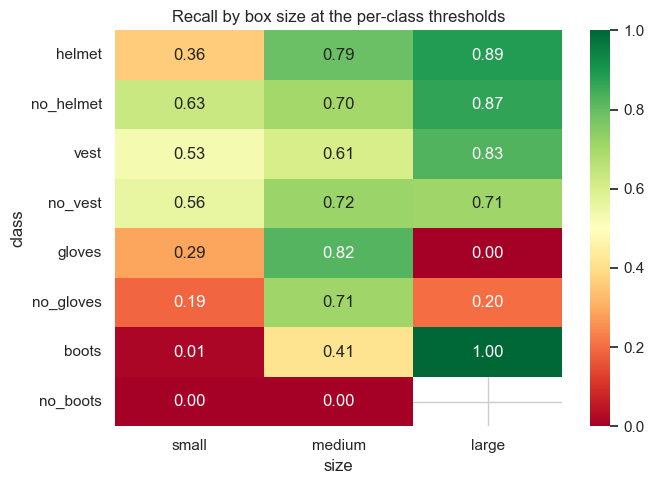

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/best_val_recall_by_size.png


In [121]:
focus_labels = label_results[label_results["class"].isin(FOCUS_CLASSES)]
size_recall = focus_labels.pivot_table(index="class", columns="size", values="found", aggfunc="mean")
size_recall = size_recall.reindex(index=FOCUS_CLASSES, columns=["small", "medium", "large"])
size_count = focus_labels.pivot_table(index="class", columns="size", values="found", aggfunc="count")
size_count = size_count.reindex(index=FOCUS_CLASSES, columns=["small", "medium", "large"]).fillna(0).astype(int)
size_count.columns = ["small labels", "medium labels", "large labels"]
save_table(pd.concat([size_recall.round(3), size_count], axis=1), "best_val_recall_by_size")

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(size_recall, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax)
ax.set_title("Recall by box size at the per-class thresholds")
plt.tight_layout()
save_figure(fig, "best_val_recall_by_size")

#### Bootstrap confidence intervals

The val images are resampled with replacement `BOOTSTRAP_ROUNDS` times, and precision, recall, and F1 are recomputed each time. The 2.5 and 97.5 percentiles give a 95 percent interval. If two models have overlapping intervals, the difference between them is not reliable.

/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1437: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


,precision,precision 2.5%,precision 97.5%,recall,recall 2.5%,recall 97.5%,F1 2.5%,F1 97.5%
class,,,,,,,,
helmet,0.549,0.508,0.592,0.713,0.659,0.764,0.585,0.656
no_helmet,0.265,0.230,0.301,0.724,0.657,0.789,0.346,0.430
vest,0.728,0.678,0.775,0.739,0.680,0.797,0.694,0.774
no_vest,0.328,0.277,0.378,0.706,0.631,0.777,0.392,0.501
gloves,0.833,0.792,0.873,0.806,0.759,0.851,0.782,0.853
no_gloves,0.579,0.525,0.627,0.658,0.597,0.712,0.567,0.658
boots,0.669,0.556,0.772,0.313,0.245,0.387,0.350,0.501
no_boots,0.000,NaN,NaN,0.000,0.000,0.000,NaN,NaN


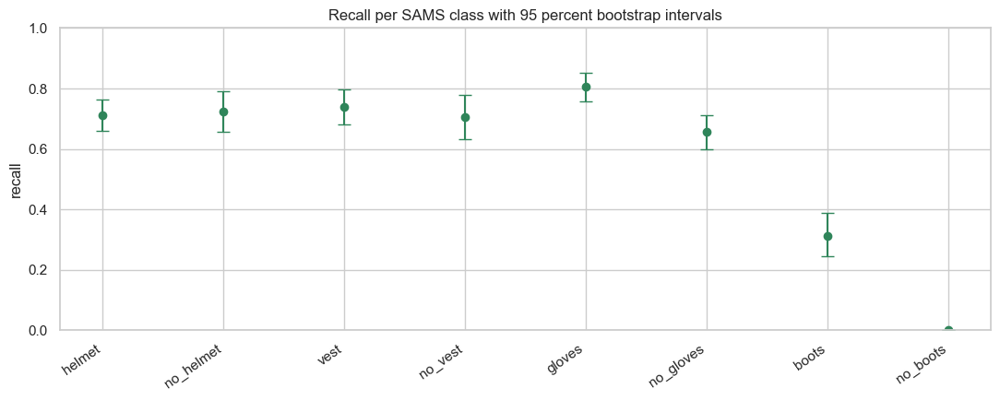

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/best_val_bootstrap_recall.png


In [122]:
bootstrap_rng = np.random.default_rng(SEED)
image_count = len(VAL_IMAGES)
bootstrap_precision = []
bootstrap_recall = []
for _ in range(BOOTSTRAP_ROUNDS):
    sample = bootstrap_rng.integers(0, image_count, image_count)
    tp_sum = true_positive[sample].sum(axis=0)
    fp_sum = false_positive[sample].sum(axis=0)
    fn_sum = false_negative[sample].sum(axis=0)
    with np.errstate(divide="ignore", invalid="ignore"):
        bootstrap_precision.append(tp_sum / (tp_sum + fp_sum))
        bootstrap_recall.append(tp_sum / (tp_sum + fn_sum))
bootstrap_precision = np.array(bootstrap_precision)
bootstrap_recall = np.array(bootstrap_recall)
with np.errstate(divide="ignore", invalid="ignore"):
    bootstrap_f1 = 2 * bootstrap_precision * bootstrap_recall / (bootstrap_precision + bootstrap_recall)

tp_total = true_positive.sum(axis=0)
fp_total = false_positive.sum(axis=0)
fn_total = false_negative.sum(axis=0)
interval_rows = []
for class_name in FOCUS_CLASSES:
    class_id = NAME_TO_ID[class_name]
    if tp_total[class_id] + fn_total[class_id] == 0:
        continue
    precision = tp_total[class_id] / max(tp_total[class_id] + fp_total[class_id], 1)
    recall = tp_total[class_id] / (tp_total[class_id] + fn_total[class_id])
    interval_rows.append({
        "class": class_name,
        "precision": precision,
        "precision 2.5%": np.nanpercentile(bootstrap_precision[:, class_id], 2.5),
        "precision 97.5%": np.nanpercentile(bootstrap_precision[:, class_id], 97.5),
        "recall": recall,
        "recall 2.5%": np.nanpercentile(bootstrap_recall[:, class_id], 2.5),
        "recall 97.5%": np.nanpercentile(bootstrap_recall[:, class_id], 97.5),
        "F1 2.5%": np.nanpercentile(bootstrap_f1[:, class_id], 2.5),
        "F1 97.5%": np.nanpercentile(bootstrap_f1[:, class_id], 97.5),
    })
interval_table = pd.DataFrame(interval_rows).set_index("class")
save_table(interval_table.round(3), "best_val_bootstrap_intervals")

fig, ax = plt.subplots(figsize=(11, 4.5))
lower_error = interval_table["recall"] - interval_table["recall 2.5%"]
upper_error = interval_table["recall 97.5%"] - interval_table["recall"]
ax.errorbar(interval_table.index, interval_table["recall"], yerr=[lower_error, upper_error],
            fmt="o", capsize=5, color="#2f855a")
ax.set_ylim(0, 1)
ax.set_ylabel("recall")
ax.set_title("Recall per SAMS class with 95 percent bootstrap intervals")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
save_figure(fig, "best_val_bootstrap_recall")

#### Confidence calibration

Predictions are grouped into ten confidence bins. For each bin, the share of correct predictions is compared with the mean confidence. A well-calibrated model sits on the diagonal. The expected calibration error (ECE) is the average gap, weighted by how many predictions fall in each bin. SAMS votes across frames using these confidences, so a model that is very over-confident needs higher thresholds.

,predictions,mean_confidence,share_correct
bin,,,
"(-0.001, 0.1]",4448,0.070,0.049
"(0.1, 0.2]",3152,0.142,0.113
"(0.2, 0.3]",1587,0.246,0.231
"(0.3, 0.4]",1121,0.348,0.358
"(0.4, 0.5]",959,0.449,0.488
"(0.5, 0.6]",1058,0.553,0.650
"(0.6, 0.7]",1276,0.653,0.797
"(0.7, 0.8]",1385,0.752,0.917
"(0.8, 0.9]",1771,0.853,0.975


,predictions,ECE
class,,
all classes,17560,0.059
helmet,2066,0.030
no_helmet,1340,0.092
vest,883,0.064
no_vest,834,0.057
gloves,915,0.132
no_gloves,1136,0.066
boots,272,0.102


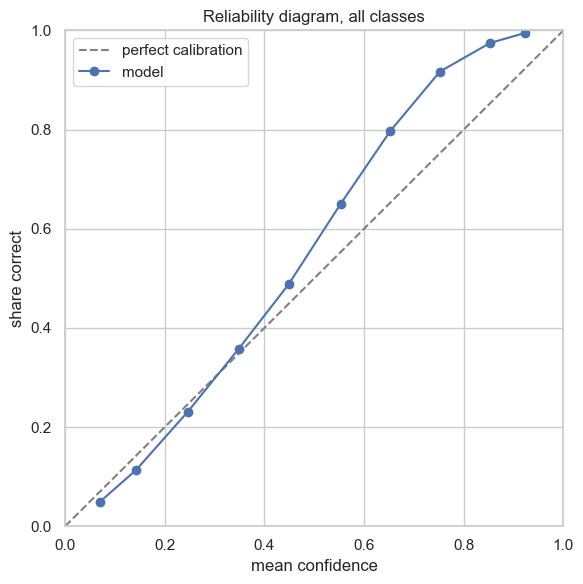

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/best_val_reliability_diagram.png


In [123]:
bin_edges = np.linspace(0, 1, 11)


def calibration_table(frame):
    binned = frame.copy()
    binned["bin"] = pd.cut(binned["confidence"], bins=bin_edges, include_lowest=True)
    table = binned.groupby("bin", observed=True).agg(
        predictions=("correct", "count"),
        mean_confidence=("confidence", "mean"),
        share_correct=("correct", "mean"),
    )
    return table


overall_calibration = calibration_table(calibration_results)
save_table(overall_calibration.round(3), "best_val_calibration_bins")

ece_rows = []
for class_name in ["all classes"] + FOCUS_CLASSES:
    if class_name == "all classes":
        subset = calibration_results
    else:
        subset = calibration_results[calibration_results["class"] == class_name]
    if subset.empty:
        continue
    table = calibration_table(subset)
    weights = table["predictions"] / table["predictions"].sum()
    gaps = (table["share_correct"] - table["mean_confidence"]).abs()
    ece_rows.append({"class": class_name, "predictions": len(subset), "ECE": float((weights * gaps).sum())})
save_table(pd.DataFrame(ece_rows).set_index("class").round(3), "best_val_calibration_error")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
ax.plot(overall_calibration["mean_confidence"], overall_calibration["share_correct"], marker="o", label="model")
ax.set_xlabel("mean confidence")
ax.set_ylabel("share correct")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Reliability diagram, all classes")
ax.legend()
plt.tight_layout()
save_figure(fig, "best_val_reliability_diagram")

#### Where the model misses missing gear

The six val images with the most missed missing-gear labels. Green boxes are the labels, red boxes are the predictions kept at the per-class thresholds. Look for a pattern: small hands, dark scenes, workers far away, or labels that are themselves wrong.

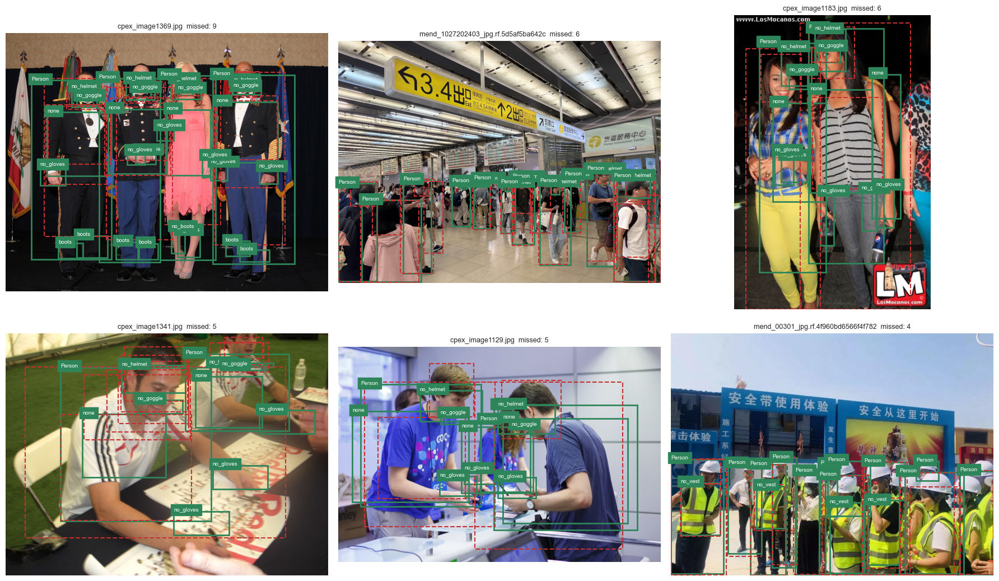

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/best_val_missed_missing_gear.png


In [124]:
missing_ids = []
for class_name in MISSING_CLASSES:
    missing_ids.append(NAME_TO_ID[class_name])
missed_per_image = false_negative[:, missing_ids].sum(axis=1)
worst_order = np.argsort(-missed_per_image)

gallery = []
for image_number in worst_order[:6]:
    if missed_per_image[image_number] > 0:
        gallery.append(image_number)

if not gallery:
    display(pd.DataFrame([{"result": "No missing-gear labels were missed on val"}]))
else:
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    for ax in axes.flatten():
        ax.axis("off")
    for ax, image_number in zip(axes.flatten(), gallery):
        image_path = VAL_IMAGES[image_number]
        label_rows = read_labels(label_path_for(image_path))
        prediction_rows = []
        for prediction in KEPT_PREDICTIONS[str(image_path)]:
            prediction_rows.append([prediction[0], prediction[2], prediction[3], prediction[4], prediction[5]])
        draw_boxes(ax, image_path, label_rows, color="#2f855a")
        image = Image.open(image_path)
        for row in prediction_rows:
            left = (row[1] - row[3] / 2) * image.width
            top = (row[2] - row[4] / 2) * image.height
            ax.add_patch(patches.Rectangle((left, top), row[3] * image.width, row[4] * image.height,
                                           fill=False, linewidth=1.5, edgecolor="#c53030", linestyle="--"))
        ax.set_title(f"{image_path.name[:35]}  missed: {int(missed_per_image[image_number])}", fontsize=9)
    plt.tight_layout()
    save_figure(fig, "best_val_missed_missing_gear")

### 13.6 Robustness to bad camera conditions

`ROBUST_SAMPLE` val images are scored as they are, and again after one fixed degradation at a time. Only the image changes, so the labels are the same. A large drop shows which condition to add more training data for.

| Condition | What it imitates |
|-----------|------------------|
| motion blur | A worker walking, or camera shake |
| dark | Night shift or a badly lit corner |
| heavy jpeg | A heavily compressed stream |
| low resolution | A distant worker on a low-resolution camera |
| sensor noise | A cheap or overheating camera sensor |

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,135,380 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2576.7±1379.9 MB/s, size: 539.2 KB)
val: Scanning /content/SAMS/datasets/vision/ppe/merged/labels/robust_clean... 600 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 600/600 1.4Kit/s 0.4s
val: New cache created: /content/SAMS/datasets/vision/ppe/merged/labels/robust_clean.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 11.1it/s 3.4s
                   all        600       3224      0.684      0.572      0.578      0.334
Speed: 0.5ms preprocess, 1.2ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,135,380 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.

,precision,recall,mAP50,mAP50-95,missing recall,mAP50-95 drop vs clean
condition,,,,,,
clean,0.684,0.572,0.578,0.334,0.408,0.000
motion blur,0.664,0.537,0.542,0.289,0.381,0.045
dark,0.605,0.414,0.388,0.214,0.323,0.120
heavy jpeg,0.671,0.518,0.533,0.303,0.360,0.030
low resolution,0.676,0.487,0.504,0.270,0.345,0.064
sensor noise,0.587,0.457,0.421,0.230,0.321,0.104


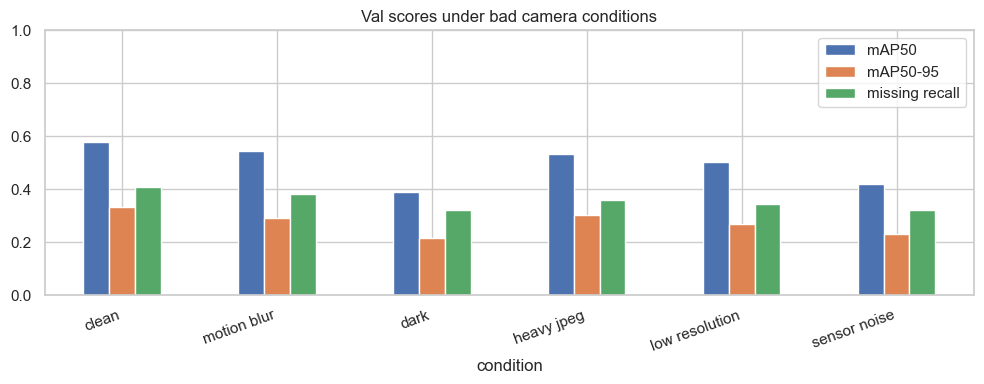

Saved figure: /content/drive/MyDrive/SAMS/results/vision/ppe/best_val_robustness.png


In [125]:
robust_rng = np.random.default_rng(SEED)
sample_count = min(ROBUST_SAMPLE, len(VAL_IMAGES))
chosen_positions = sorted(robust_rng.choice(len(VAL_IMAGES), size=sample_count, replace=False))
robust_images = []
for position in chosen_positions:
    robust_images.append(VAL_IMAGES[position])

CONDITIONS = {
    "clean": None,
    "motion blur": A.MotionBlur(blur_limit=(9, 13), p=1.0),
    "dark": A.RandomBrightnessContrast(brightness_limit=(-0.45, -0.35), contrast_limit=(0.0, 0.0), p=1.0),
    "heavy jpeg": A.ImageCompression(quality_range=(10, 20), p=1.0),
    "low resolution": A.Downscale(scale_range=(0.3, 0.35), p=1.0),
    "sensor noise": A.GaussNoise(std_range=(0.08, 0.12), p=1.0),
}

robust_rows = []
for condition, transform in CONDITIONS.items():
    folder = "robust_" + condition.replace(" ", "_")
    image_dir = MERGED / "images" / folder
    label_dir = MERGED / "labels" / folder
    for directory in [image_dir, label_dir]:
        if directory.exists():
            shutil.rmtree(directory)
        directory.mkdir(parents=True)

    written = []
    for image_path in robust_images:
        target = image_dir / image_path.name
        if transform is None:
            shutil.copy2(image_path, target)
        else:
            pixels = np.array(Image.open(image_path).convert("RGB"))
            changed = transform(image=pixels)["image"]
            Image.fromarray(changed).save(target, quality=95)
        shutil.copy2(label_path_for(image_path), label_dir / f"{image_path.stem}.txt")
        written.append(target)

    list_path = write_list(folder, written)
    data_yaml = write_data_yaml(folder, VAL_LIST, list_path, list_path)
    metrics = score_model(BEST_WEIGHTS, data_yaml, BEST_IMGSZ_FINAL)
    per_class = per_class_frame(metrics)
    robust_rows.append({
        "condition": condition,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
        "missing recall": mean_missing_recall(per_class),
    })

robust_table = pd.DataFrame(robust_rows).set_index("condition")
clean_score = robust_table.loc["clean", "mAP50-95"]
robust_table["mAP50-95 drop vs clean"] = clean_score - robust_table["mAP50-95"]
save_table(robust_table.round(3), "best_val_robustness")

fig, ax = plt.subplots(figsize=(10, 4))
robust_table[["mAP50", "mAP50-95", "missing recall"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Val scores under bad camera conditions")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
save_figure(fig, "best_val_robustness")

## 14. Final test, live metadata, export check, model card

### 14.1 Score the chosen model once on test

The chosen weights are copied to `models/vision/ppe/best.pt` and scored on the test split of each source and on all test images together. This is the only time test is used.

In [126]:
PROMOTED = MODELS_DIR / "best.pt"
shutil.copy2(BEST_WEIGHTS, PROMOTED)

test_rows = []
TEST_RESULTS = {}
for name, list_path in TEST_LISTS.items():
    test_yaml = write_data_yaml(f"test_{name}", TRAIN_LISTS["balanced"], VAL_LIST, list_path)
    metrics = score_model(PROMOTED, test_yaml, BEST_IMGSZ_FINAL, split="test")
    per_class = per_class_frame(metrics)
    TEST_RESULTS[name] = {
        "images": len(read_list(list_path)),
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "map50": float(metrics.box.map50),
        "map50_95": float(metrics.box.map),
        "missing_recall": mean_missing_recall(per_class),
    }
    row = {"test set": name}
    row.update(TEST_RESULTS[name])
    test_rows.append(row)
    if name == "all":
        test_per_class = per_class

save_table(pd.DataFrame(test_rows).set_index("test set").round(4), "final_test_by_source")
save_table(test_per_class.round(3), "final_test_per_class")


def class_recall(per_class, class_name):
    if class_name not in per_class.index:
        return float("nan")
    return float(per_class.loc[class_name, "recall"])


boots_val = EXPERIMENTS[WINNER_ID]["per_class"]
summary_rows = [
    {"item": "chosen experiment", "value": WINNER_ID},
    {"item": "base model", "value": WINNER["recipe"]["weights"]},
    {"item": "image size", "value": BEST_IMGSZ_FINAL},
    {"item": "two-stage fine-tuning", "value": WINNER["recipe"]["two_stage"]},
    {"item": "training images", "value": WINNER["summary"]["train images"]},
    {"item": "val mAP50-95", "value": round(float(WINNER["summary"]["map50_95"]), 4)},
    {"item": "val missing-gear recall", "value": round(float(WINNER["summary"]["missing_recall"]), 4)},
    {"item": "val boots recall", "value": round(class_recall(boots_val, "boots"), 4)},
    {"item": "val no_boots recall", "value": round(class_recall(boots_val, "no_boots"), 4)},
    {"item": "test mAP50-95 (all sources)", "value": round(float(TEST_RESULTS["all"]["map50_95"]), 4)},
    {"item": "test missing-gear recall (all sources)", "value": round(float(TEST_RESULTS["all"]["missing_recall"]), 4)},
]
if "site" in TEST_RESULTS:
    summary_rows.append({"item": "test missing-gear recall (site)", "value": round(float(TEST_RESULTS["site"]["missing_recall"]), 4)})
    summary_rows.append({"item": "test mAP50-95 (site)", "value": round(float(TEST_RESULTS["site"]["map50_95"]), 4)})
else:
    summary_rows.append({"item": "site frames in training", "value": "site" in SOURCES})
summary_rows += [
    {"item": "weights", "value": str(PROMOTED)},
    {"item": "metadata", "value": str(MODELS_DIR / "metadata.json")},
    {"item": "model card", "value": str(MODELS_DIR / "model_card.md")},
    {"item": "tables and charts", "value": str(RESULTS_DIR)},
]
save_table(pd.DataFrame(summary_rows).set_index("item"), "final_summary")
if "site" not in SOURCES:
    print("WARNING: no SAMS site frames were used. Collect datasets/vision/ppe/site/ before trusting missing-gear recall on your camera.")


Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,135,380 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.6 ms, read: 51.6±8.4 MB/s, size: 92.3 KB)
val: Scanning /content/SAMS/datasets/vision/ppe/merged/labels/test... 2062 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2062/2062 907.4it/s 2.3s
val: New cache created: /content/SAMS/datasets/vision/ppe/merged/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 129/129 15.1it/s 8.5s
                   all       2062       7805      0.547      0.438      0.402      0.211
Speed: 0.4ms preprocess, 1.0ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,135,380 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1991

,images,precision,recall,map50,map50_95,missing_recall
test set,,,,,,
all,2062,0.5466,0.4383,0.4025,0.2114,0.0382
cpex,141,0.6567,0.4383,0.4677,0.2235,0.0583
wppe,1921,0.5942,0.3838,0.3892,0.2035,0.0539


,precision,recall,mAP50,mAP50-95
class,,,,
helmet,0.851,0.692,0.791,0.207
gloves,0.225,0.673,0.236,0.100
vest,0.612,0.820,0.798,0.488
boots,0.837,0.376,0.452,0.242
goggles,0.649,0.795,0.747,0.349
none,0.381,0.237,0.239,0.080
Person,0.797,0.949,0.957,0.799
no_helmet,0.578,0.115,0.131,0.031
no_goggle,0.082,0.164,0.063,0.026


### 14.2 Metadata for the live service

`ppe_inference.py` reads `items`, `conf`, `imgsz`, and `person` from this file. `vest` now has `no_vest` as its missing class, so the live service can flag a missing vest. `class_conf` holds the per-class thresholds from 13.4. The current live code reads only `conf`, so using `class_conf` there is a follow-up change in `ppe_inference.py`.

In [127]:
promoted_model = YOLO(str(PROMOTED))
promoted_names = {}
for class_id, class_name in promoted_model.names.items():
    promoted_names[int(class_id)] = str(class_name)
del promoted_model

winner_train_list = yaml.safe_load(Path(BEST_DATA).read_text())["train"]
dataset_hash = hashlib.sha256(Path(winner_train_list).read_bytes()).hexdigest()

metadata = {
    "model_id": f"{Path(WINNER['recipe']['weights']).stem}_ppe_sams",
    "best_experiment_id": WINNER_ID,
    "trained_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": {
        "sources": SOURCE_NAMES,
        "mendeley_doi": MENDELEY_DOI,
        "worker_ppe_hf": "keremberke/protective-equipment-detection",
        "train_images": len(read_list(winner_train_list)),
        "val_images": len(VAL_IMAGES),
        "train_list_sha256": dataset_hash,
        "person_boxes_machine_made_for": ["mend", "wppe"],
        "teacher_labels": {
            "used": bool(USE_TEACHER_LABELS),
            "teacher": TEACHER_ID,
            "conf": TEACHER_CONF,
            "classes_by_source": UNLABELLED_BY_SOURCE,
        },
        "site_frames": "site" in SOURCES,
    },
    "class_names": promoted_names,
    "person": ["Person", "person"],
    "items": SAMS_ITEMS,
    "conf": GLOBAL_CONF,
    "class_conf": CLASS_CONF,
    "class_conf_rule": f"F1 for worn and other classes, F{MISSING_F_BETA:g} for missing gear, on val",
    "imgsz": BEST_IMGSZ_FINAL,
    "tracker": "bytetrack.yaml",
    "recipe": {
        "weights_in": WINNER["recipe"]["weights"],
        "two_stage": WINNER["recipe"]["two_stage"],
        "freeze_layers_stage_a": FREEZE_LAYERS,
        "epochs_limit": WINNER["summary"]["epochs_limit"],
        "epochs_run": WINNER["summary"]["epochs_run"],
        "hyperparameters": WINNER["recipe"]["hparams"],
    },
    "val": {
        "map50": WINNER["summary"]["map50"],
        "map50_95": WINNER["summary"]["map50_95"],
        "missing_recall": WINNER["summary"]["missing_recall"],
    },
    "test": TEST_RESULTS,
    "versions": {
        "ultralytics": ultralytics.__version__,
        "torch": torch.__version__,
        "albumentations": A.__version__,
    },
}
with (MODELS_DIR / "metadata.json").open("w") as handle:
    json.dump(metadata, handle, indent=2, default=str)

metadata_view = pd.DataFrame([
    {"field": "model_id", "value": metadata["model_id"]},
    {"field": "best_experiment_id", "value": WINNER_ID},
    {"field": "imgsz", "value": BEST_IMGSZ_FINAL},
    {"field": "conf", "value": GLOBAL_CONF},
    {"field": "vest missing class", "value": ", ".join(SAMS_ITEMS["vest"]["missing"])},
    {"field": "val mAP50-95", "value": round(WINNER["summary"]["map50_95"], 4)},
    {"field": "test mAP50-95 (all)", "value": round(TEST_RESULTS["all"]["map50_95"], 4)},
    {"field": "weights", "value": str(PROMOTED)},
]).set_index("field")
display(metadata_view)

,value
field,
model_id,yolov8n_ppe_sams
best_experiment_id,ppe_e1_full
imgsz,640
conf,0.167
vest missing class,no_vest
val mAP50-95,0.3194
test mAP50-95 (all),0.2114
weights,/content/drive/MyDrive/SAMS/models/vision/ppe/...


### 14.3 Model card

A one-page summary saved as `model_card.md` next to the weights, so anyone using the model can see where it came from, how well it works per source, and where it is weak.

In [128]:
card_lines = [
    "# SAMS PPE detector",
    "",
    f"- Model: {metadata['model_id']} (experiment {WINNER_ID})",
    f"- Trained: {metadata['trained_utc']}",
    f"- Image size: {BEST_IMGSZ_FINAL}, two-stage fine-tuning: {WINNER['recipe']['two_stage']}, optimizer: {WINNER['recipe']['hparams']['optimizer']}",
    f"- Epochs run: {WINNER['summary']['epochs_run']} of at most {WINNER['summary']['epochs_limit']}",
    f"- Teacher-filled labels: {USE_TEACHER_LABELS} (teacher {TEACHER_ID}, confidence at least {TEACHER_CONF})",
    f"- Training images: {metadata['dataset']['train_images']}, val images: {len(VAL_IMAGES)}",
    "",
    "## Intended use",
    "",
    "Finds each worker (Person) and their hard hat, vest, gloves, and safety shoes, worn or missing, in SAMS camera frames.",
    "monitoring/services/ppe_inference.py reads items, person, class_conf, conf, and imgsz from metadata.json.",
    "",
    "## Test results per source",
    "",
    "| Test set | Images | mAP50 | mAP50-95 | Missing-gear recall |",
    "|----------|--------|-------|----------|---------------------|",
]
for name, result in TEST_RESULTS.items():
    card_lines.append(f"| {name} | {result['images']} | {result['map50']:.3f} | {result['map50_95']:.3f} | {result['missing_recall']:.3f} |")
card_lines += [
    "",
    "## Thresholds",
    "",
    "| Class | Threshold |",
    "|-------|-----------|",
]
for class_name, threshold in CLASS_CONF.items():
    card_lines.append(f"| {class_name} | {threshold} |")
card_lines += [
    "",
    "## Known limitations",
    "",
    "- Person boxes in Mendeley and the Worker PPE set are machine-made.",
    "- Val and test keep each source's labelling gaps, so gear a source does not label counts as a false detection there.",
]
if "site" not in SOURCES:
    card_lines.append("- No SAMS site frames were used: every score above comes from public datasets.")
    card_lines.append("- Collect site train/val/test under datasets/vision/ppe/site/ and empty frames under background/ before the next train.")
card_lines.append("- Boots and no_boots stay the weakest classes until site feet shots are labelled; check val boots / no_boots recall in final_summary.csv.")
(MODELS_DIR / "model_card.md").write_text("\n".join(card_lines) + "\n")
print("Model card written to", MODELS_DIR / "model_card.md")


Model card written to /content/drive/MyDrive/SAMS/models/vision/ppe/model_card.md


### 14.4 Export check

The model is exported to ONNX, the format most deployment runtimes accept. The ONNX file is scored on test again (accuracy should not drop) and both versions are timed on 100 val images, one image at a time, the way the live stream runs. Without `onnxruntime-gpu`, the ONNX model runs on the CPU, so its speed shows CPU deployment.

In [129]:
def measure_fps(weights_path, images, imgsz):
    model = YOLO(str(weights_path))
    for image_path in images[:5]:
        model.predict(str(image_path), imgsz=imgsz, device=YOLO_DEVICE, verbose=False)
    started = time.time()
    for image_path in images:
        model.predict(str(image_path), imgsz=imgsz, device=YOLO_DEVICE, verbose=False)
    elapsed = time.time() - started
    del model
    free_memory()
    return len(images) / elapsed


export_model = YOLO(str(PROMOTED))
onnx_path = Path(export_model.export(format="onnx", imgsz=BEST_IMGSZ_FINAL, simplify=True))
del export_model

timing_images = VAL_IMAGES[:100]
test_all_yaml = write_data_yaml("test_all", TRAIN_LISTS["balanced"], VAL_LIST, TEST_LISTS["all"])
export_rows = []
for format_name, weights_path in [("PyTorch", PROMOTED), ("ONNX", onnx_path)]:
    metrics = score_model(weights_path, test_all_yaml, BEST_IMGSZ_FINAL, split="test")
    export_rows.append({
        "format": format_name,
        "file": weights_path.name,
        "size MB": round(weights_path.stat().st_size / 1e6, 1),
        "test mAP50": float(metrics.box.map50),
        "test mAP50-95": float(metrics.box.map),
        "frames per second": measure_fps(weights_path, timing_images, BEST_IMGSZ_FINAL),
    })
save_table(pd.DataFrame(export_rows).set_index("format").round(3), "export_check")

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,135,380 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/SAMS/models/vision/ppe/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 16, 8400) (6.2 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 847ms
Prepared 2 packages in 239ms
Installed 2 packages in 7ms
 + colorama==0.4.6
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 6.9s, saved as '/content/d

,file,size MB,test mAP50,test mAP50-95,frames per second
format,,,,,
PyTorch,best.pt,6.5,0.402,0.211,24.936
ONNX,best.onnx,12.8,0.400,0.211,12.638
